# Beyond the Ratings: How Anime Atmosphere Shapes Popularity and Audience Loyalty

## Project overview

Anime popularity, user ratings, and audience loyalty represent different aspects of viewer reception. A title may attract a large audience without receiving particularly high ratings, while another title may remain relatively niche but develop a highly loyal fanbase.

This project investigates how anime atmosphere is associated with audience size, user ratings, and viewer loyalty. Atmosphere categories are derived from anime genres and themes. The analysis also examines how the distribution and popularity of different atmospheres have changed over time.

## Main research question

How is anime atmosphere associated with audience size, user ratings, and viewer loyalty, and how have these relationships changed over time?

## Tools

- Python
- Pandas
- NumPy
- Plotly
- Streamlit

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

px.defaults.template = "plotly_white"

## 1. Data loading

The dataset is loaded from a CSV file and stored in a Pandas DataFrame.

In [3]:
DATA_PATH = "anime_dataset.csv"

df_raw = pd.read_csv(DATA_PATH)

print(f"Number of rows: {df_raw.shape[0]:,}")
print(f"Number of columns: {df_raw.shape[1]}")

Number of rows: 30,075
Number of columns: 29


In [4]:
df_raw.head()

,mal_id,title,title_english,title_japanese,type,source,episodes,status,airing,aired_from,aired_to,duration,rating,score,scored_by,rank,popularity,members,favorites,season,year,studios,producers,licensors,genres,themes,demographics,synopsis,image_url
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,TV,Original,26.0,Finished Airing,False,1998-04-03,1999-04-24,24 min per ep,R - 17+ (violence & profanity),8.75,1059628.0,49.0,41,2051751,89485,spring,1998.0,Sunrise,Bandai Visual|Victor Entertainment|Audio Planning U,Funimation,Action|Award Winning|Sci-Fi,Adult Cast|Space,NaN,"Crime is timeless. By the year 2071, humanity has expanded across the galaxy, filling the surface of other planets w...",https://myanimelist.net/images/anime/4/19644.jpg
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,Movie,Original,1.0,Finished Airing,False,2001-09-01,NaN,1 hr 55 min,R - 17+ (violence & profanity),8.38,231900.0,240.0,658,411149,1782,NaN,NaN,Bones,Sunrise|Bandai Visual,Sony Pictures Entertainment|Funimation,Action|Sci-Fi,Adult Cast|Space,NaN,"Another day, another bounty—such is the life of the often unlucky crew of the Bebop. However, this routine is interr...",https://myanimelist.net/images/anime/1439/93480.jpg
2,6,Trigun,Trigun,トライガン,TV,Manga,26.0,Finished Airing,False,1998-04-01,1998-09-30,24 min per ep,PG-13 - Teens 13 or older,8.22,400979.0,420.0,265,832801,17610,spring,1998.0,Madhouse,Victor Entertainment|Arts Pro,Funimation,Action|Adventure|Sci-Fi,Adult Cast,Shounen,"Vash the Stampede is the man with a $$60,000,000,000 bounty on his head. The reason: he's a merciless villain who la...",https://myanimelist.net/images/anime/1130/120002.jpg
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),TV,Original,26.0,Finished Airing,False,2002-07-03,2002-12-25,25 min per ep,PG-13 - Teens 13 or older,7.25,46538.0,3529.0,1989,129274,707,summer,2002.0,Sunrise,Bandai Visual|Dentsu|Victor Entertainment,Funimation|Bandai Entertainment,Action|Drama|Mystery|Supernatural,Detective,NaN,"Though hidden away from the general public, Witches—those with supernatural powers—have always existed in human soci...",https://myanimelist.net/images/anime/10/19969.jpg
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,TV,Manga,52.0,Finished Airing,False,2004-09-30,2005-09-29,23 min per ep,PG - Children,7.01,7229.0,4900.0,5891,16881,18,fall,2004.0,Toei Animation,TV Tokyo|Dentsu,Illumitoon Entertainment,Action|Adventure|Fantasy,NaN,Shounen,"It is the dark century and the people are suffering under the rule of the devil, Vandel, who is able to manipulate m...",https://myanimelist.net/images/anime/7/21569.jpg


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30075 entries, 0 to 30074
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mal_id          30075 non-null  int64  
 1   title           30075 non-null  str    
 2   title_english   13306 non-null  str    
 3   title_japanese  29951 non-null  str    
 4   type            30003 non-null  str    
 5   source          30075 non-null  str    
 6   episodes        29236 non-null  float64
 7   status          30075 non-null  str    
 8   airing          30075 non-null  bool   
 9   aired_from      29166 non-null  str    
 10  aired_to        11594 non-null  str    
 11  duration        30075 non-null  str    
 12  rating          29473 non-null  str    
 13  score           19892 non-null  float64
 14  scored_by       19892 non-null  float64
 15  rank            22584 non-null  float64
 16  popularity      30075 non-null  int64  
 17  members         30075 non-null  int64  
 1

## 2. Initial data quality inspection

Before cleaning the dataset, missing values, duplicate records, and data types are examined.

In [6]:
missing_values = (
    df_raw.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

missing_values["missing_percentage"] = (
    missing_values["missing_count"] / len(df_raw) * 100
).round(2)

missing_values

,missing_count,missing_percentage
licensors,24877,82.72
year,23550,78.30
season,23550,78.30
demographics,18941,62.98
aired_to,18481,61.45
title_english,16769,55.76
producers,15796,52.52
themes,12098,40.23
studios,11938,39.69
score,10183,33.86


In [7]:
print("Fully duplicated rows:", df_raw.duplicated().sum())
print("Duplicated MAL IDs:", df_raw["mal_id"].duplicated().sum())

Fully duplicated rows: 139
Duplicated MAL IDs: 139


In [8]:
df_raw.dtypes

mal_id              int64
title                 str
title_english         str
title_japanese        str
type                  str
source                str
episodes          float64
status                str
airing               bool
aired_from            str
aired_to              str
duration              str
rating                str
score             float64
scored_by         float64
rank              float64
popularity          int64
members             int64
favorites           int64
season                str
year              float64
studios               str
producers             str
licensors             str
genres                str
themes                str
demographics          str
synopsis              str
image_url             str
dtype: object

## 3. Data cleaning

A separate working copy is created so that the original dataset remains unchanged. Duplicate anime entries are removed using `mal_id`, which is the unique MyAnimeList identifier.

In [9]:
df = df_raw.copy()

In [10]:
df = df.drop_duplicates(subset="mal_id").copy()

print(f"Rows before duplicate removal: {len(df_raw):,}")
print(f"Rows after duplicate removal: {len(df):,}")

Rows before duplicate removal: 30,075
Rows after duplicate removal: 29,936


### Date conversion

The original date columns are converted from text into Pandas datetime format. Invalid values are converted into missing datetime values.

In [11]:
df["aired_from"] = pd.to_datetime(
    df["aired_from"],
    errors="coerce"
)

df["aired_to"] = pd.to_datetime(
    df["aired_to"],
    errors="coerce"
)

In [12]:
df[["aired_from", "aired_to"]].dtypes

aired_from    datetime64[us]
aired_to      datetime64[us]
dtype: object

### Release year

The original `year` column contains many missing values. Therefore, a more complete `release_year` variable is extracted from `aired_from`.

In [13]:
df["release_year"] = df["aired_from"].dt.year

In [14]:
df[
    ["title", "year", "aired_from", "release_year"]
].head(10)

,title,year,aired_from,release_year
0,Cowboy Bebop,1998.0,1998-04-03,1998.0
1,Cowboy Bebop: Tengoku no Tobira,NaN,2001-09-01,2001.0
2,Trigun,1998.0,1998-04-01,1998.0
3,Witch Hunter Robin,2002.0,2002-07-03,2002.0
4,Bouken Ou Beet,2004.0,2004-09-30,2004.0
5,Eyeshield 21,2005.0,2005-04-06,2005.0
6,Hachimitsu to Clover,2005.0,2005-04-15,2005.0
7,Hungry Heart: Wild Striker,2002.0,2002-09-11,2002.0
8,Initial D Fourth Stage,2004.0,2004-04-17,2004.0
9,Monster,2004.0,2004-04-07,2004.0


### Numeric conversion

Columns that should contain numeric values are explicitly converted to numeric types. Invalid values are replaced with missing values.

In [15]:
numeric_columns = [
    "episodes",
    "score",
    "scored_by",
    "rank",
    "popularity",
    "members",
    "favorites",
    "release_year"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

In [16]:
df[numeric_columns].dtypes

episodes        float64
score           float64
scored_by       float64
rank            float64
popularity        int64
members           int64
favorites         int64
release_year    float64
dtype: object

### Multi-value columns

The `genres`, `themes`, `studios`, and `demographics` columns contain several values separated by the `|` symbol. These strings are converted into Python lists to make later analysis easier.

In [17]:
list_columns = [
    "genres",
    "themes",
    "studios",
    "demographics"
]

for column in list_columns:
    df[f"{column}_list"] = (
        df[column]
        .fillna("")
        .str.split("|")
        .apply(lambda values: [
            value.strip()
            for value in values
            if value.strip()
        ])
    )

In [18]:
df[
    [
        "genres",
        "genres_list",
        "themes",
        "themes_list",
        "studios",
        "studios_list"
    ]
].head()

,genres,genres_list,themes,themes_list,studios,studios_list
0,Action|Award Winning|Sci-Fi,"[Action, Award Winning, Sci-Fi]",Adult Cast|Space,"[Adult Cast, Space]",Sunrise,[Sunrise]
1,Action|Sci-Fi,"[Action, Sci-Fi]",Adult Cast|Space,"[Adult Cast, Space]",Bones,[Bones]
2,Action|Adventure|Sci-Fi,"[Action, Adventure, Sci-Fi]",Adult Cast,[Adult Cast],Madhouse,[Madhouse]
3,Action|Drama|Mystery|Supernatural,"[Action, Drama, Mystery, Supernatural]",Detective,[Detective],Sunrise,[Sunrise]
4,Action|Adventure|Fantasy,"[Action, Adventure, Fantasy]",NaN,[],Toei Animation,[Toei Animation]


## 4. Feature engineering

Several new variables are created for the analysis:

- `decade`: release decade
- `log_members`: logarithmic audience size
- `favorite_rate`: proportion of members who added an anime to favorites
- `favorite_rate_pct`: the same proportion expressed as a percentage
- `genre_count`: number of genres
- `theme_count`: number of themes

In [19]:
df["decade"] = np.where(
    df["release_year"].notna(),
    (df["release_year"] // 10 * 10)
        .astype("Int64")
        .astype(str)
        + "s",
    pd.NA
)

In [20]:
df["log_members"] = np.log10(df["members"] + 1)

In [21]:
df["favorite_rate"] = np.where(
    df["members"] > 0,
    df["favorites"] / df["members"],
    np.nan
)

df["favorite_rate_pct"] = df["favorite_rate"] * 100

In [22]:
df["genre_count"] = df["genres_list"].str.len()
df["theme_count"] = df["themes_list"].str.len()

In [23]:
df[
    [
        "title",
        "release_year",
        "decade",
        "score",
        "members",
        "favorites",
        "favorite_rate_pct",
        "genres_list",
        "themes_list"
    ]
].head()

,title,release_year,decade,score,members,favorites,favorite_rate_pct,genres_list,themes_list
0,Cowboy Bebop,1998.0,1990s,8.75,2051751,89485,4.361397,"[Action, Award Winning, Sci-Fi]","[Adult Cast, Space]"
1,Cowboy Bebop: Tengoku no Tobira,2001.0,2000s,8.38,411149,1782,0.433420,"[Action, Sci-Fi]","[Adult Cast, Space]"
2,Trigun,1998.0,1990s,8.22,832801,17610,2.114551,"[Action, Adventure, Sci-Fi]",[Adult Cast]
3,Witch Hunter Robin,2002.0,2000s,7.25,129274,707,0.546900,"[Action, Drama, Mystery, Supernatural]",[Detective]
4,Bouken Ou Beet,2004.0,2000s,7.01,16881,18,0.106629,"[Action, Adventure, Fantasy]",[]


## 5. Atmosphere classification

The original dataset does not contain a direct atmosphere variable. Therefore, atmosphere categories are constructed using rule-based combinations of genres and themes.

Each anime receives one primary atmosphere. For every category, the number of matching genres and themes is calculated. The category with the highest number of matches is selected.

Titles with no matching genre or theme are assigned to `Other`.

This classification is an analytical interpretation rather than an objective label.

In [24]:
atmosphere_rules = {
    "Cozy / Quiet": {
        "genres": [
            "Slice of Life"
        ],
        "themes": [
            "Iyashikei",
            "CGDCT",
            "Pets",
            "Childcare"
        ]
    },

    "Melancholic / Reflective": {
        "genres": [
            "Drama"
        ],
        "themes": [
            "Psychological",
            "Adult Cast",
            "Workplace"
        ]
    },

    "Dark / Tense": {
        "genres": [
            "Horror",
            "Suspense",
            "Mystery"
        ],
        "themes": [
            "Gore",
            "Survival",
            "Organized Crime",
            "High Stakes Game"
        ]
    },

    "Romantic / Emotional": {
        "genres": [
            "Romance",
            "Boys Love",
            "Girls Love"
        ],
        "themes": [
            "Love Polygon",
            "Love Status Quo"
        ]
    },

    "Energetic / Adventurous": {
        "genres": [
            "Action",
            "Adventure",
            "Sports"
        ],
        "themes": [
            "Martial Arts",
            "Combat Sports",
            "Team Sports",
            "Racing",
            "Super Power"
        ]
    },

    "Fantasy / Escapist": {
        "genres": [
            "Fantasy",
            "Supernatural",
            "Sci-Fi"
        ],
        "themes": [
            "Isekai",
            "Reincarnation",
            "Mythology",
            "Urban Fantasy",
            "Vampire",
            "Space",
            "Time Travel",
            "Video Game"
        ]
    },

    "Light / Comedic": {
        "genres": [
            "Comedy"
        ],
        "themes": [
            "Parody",
            "Gag Humor"
        ]
    }
}

In [25]:
def calculate_atmosphere_scores(row):
    genres = set(row["genres_list"])
    themes = set(row["themes_list"])

    scores = {}

    for atmosphere, rules in atmosphere_rules.items():
        genre_matches = len(
            genres.intersection(rules["genres"])
        )

        theme_matches = len(
            themes.intersection(rules["themes"])
        )

        scores[atmosphere] = (
            genre_matches + theme_matches
        )

    return scores

In [26]:
df["atmosphere_scores"] = df.apply(
    calculate_atmosphere_scores,
    axis=1
)

In [27]:
def choose_primary_atmosphere(scores):
    best_atmosphere = max(
        scores,
        key=scores.get
    )

    if scores[best_atmosphere] == 0:
        return "Other"

    return best_atmosphere

In [28]:
df["atmosphere"] = df["atmosphere_scores"].apply(
    choose_primary_atmosphere
)

In [29]:
df["atmosphere_match_score"] = (
    df["atmosphere_scores"]
    .apply(lambda scores: max(scores.values()))
)

In [30]:
df[
    [
        "title",
        "genres",
        "themes",
        "atmosphere",
        "atmosphere_match_score"
    ]
].head(20)

,title,genres,themes,atmosphere,atmosphere_match_score
0,Cowboy Bebop,Action|Award Winning|Sci-Fi,Adult Cast|Space,Fantasy / Escapist,2
1,Cowboy Bebop: Tengoku no Tobira,Action|Sci-Fi,Adult Cast|Space,Fantasy / Escapist,2
2,Trigun,Action|Adventure|Sci-Fi,Adult Cast,Energetic / Adventurous,2
3,Witch Hunter Robin,Action|Drama|Mystery|Supernatural,Detective,Melancholic / Reflective,1
4,Bouken Ou Beet,Action|Adventure|Fantasy,NaN,Energetic / Adventurous,2
5,Eyeshield 21,Sports,Team Sports,Energetic / Adventurous,2
6,Hachimitsu to Clover,Comedy|Drama|Romance,Adult Cast|Love Polygon|Visual Arts,Melancholic / Reflective,2
7,Hungry Heart: Wild Striker,Sports,Team Sports,Energetic / Adventurous,2
8,Initial D Fourth Stage,Action|Drama,Racing,Energetic / Adventurous,2
9,Monster,Drama|Mystery|Suspense,Adult Cast|Psychological,Melancholic / Reflective,3


### Atmosphere classification check

The distribution of atmosphere categories is examined as part of the preliminary exploratory analysis. This does not count as one of the final analytical questions because it is a one-dimensional frequency summary.

In [31]:
atmosphere_counts = (
    df["atmosphere"]
    .value_counts()
    .rename_axis("atmosphere")
    .reset_index(name="anime_count")
)

atmosphere_counts

,atmosphere,anime_count
0,Other,8418
1,Energetic / Adventurous,6307
2,Fantasy / Escapist,5055
3,Light / Comedic,3389
4,Melancholic / Reflective,2939
5,Cozy / Quiet,1488
6,Romantic / Emotional,1290
7,Dark / Tense,1050


### Classification limitation

Some anime match several atmosphere categories with the same score. In such cases, the category appearing first in the rule hierarchy is selected.

The `atmosphere_match_score` variable shows how strongly an anime matched its selected atmosphere. A score of 1 represents a weaker classification than a score of 2 or more.

In [32]:
df[
    df["atmosphere_match_score"] <= 1
][
    [
        "title",
        "genres",
        "themes",
        "atmosphere",
        "atmosphere_match_score"
    ]
].head(20)

,title,genres,themes,atmosphere,atmosphere_match_score
3,Witch Hunter Robin,Action|Drama|Mystery|Supernatural,Detective,Melancholic / Reflective,1
12,Tennis no Oujisama,Sports,School,Energetic / Adventurous,1
18,Yakitate!! Japan,Comedy|Gourmet,NaN,Light / Comedic,1
26,Rurouni Kenshin: Meiji Kenkaku Romantan,Action|Comedy|Romance,Historical|Samurai,Romantic / Emotional,1
27,Rurouni Kenshin: Meiji Kenkaku Romantan - Ishinshishi e no Chinkonka,Drama,Historical|Samurai,Melancholic / Reflective,1
30,Aa! Megami-sama!,Comedy|Romance|Supernatural,NaN,Romantic / Emotional,1
31,Aa! Megami-sama! (TV),Comedy|Romance|Supernatural,NaN,Romantic / Emotional,1
33,Kidou Tenshi Angelic Layer,Award Winning|Comedy|Drama|Sci-Fi,Strategy Game,Melancholic / Reflective,1
34,Ai Yori Aoshi,Comedy|Drama|Romance,Harem,Melancholic / Reflective,1
35,Appleseed (Movie),Sci-Fi,Mecha|Military,Fantasy / Escapist,1


## 6. Cleaned dataset overview

The cleaned dataset retains missing values where they may still be useful for some analyses. Instead of removing every incomplete row globally, each analytical question will use a separate subset containing only the variables required for that question.

In [33]:
print(f"Original number of rows: {len(df_raw):,}")
print(f"Rows after duplicate removal: {len(df):,}")
print(f"Number of columns after feature engineering: {df.shape[1]}")

Original number of rows: 30,075
Rows after duplicate removal: 29,936
Number of columns after feature engineering: 43


In [34]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
mal_id,29936.0,NaN,NaN,NaN,34889.662046,1.0,16741.5,38757.5,51910.25,64012.0,19938.340061
title,29936,29934,Souseiki,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title_english,13221,13035,Way of Choices,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title_japanese,29812,28739,おしりたんてい,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,29872,9,TV,8633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,29936,17,Original,12877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
episodes,29190.0,NaN,NaN,NaN,13.971805,1.0,1.0,2.0,13.0,3000.0,47.369169
status,29936,3,Finished Airing,29011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airing,29936,2,False,29567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aired_from,29065,NaN,NaN,NaN,2010-01-20 09:52:29.891622,1917-01-01 00:00:00,2004-07-25 00:00:00,2014-04-27 00:00:00,2020-06-08 00:00:00,2028-01-01 00:00:00,NaN


## 7. Preliminary exploratory data analysis

Before answering the main analytical questions, a short exploratory analysis is conducted to understand the structure of the cleaned dataset.

This section examines:

- the distribution of anime formats;
- the distribution of user scores;
- the growth of anime releases over time;
- the most common genres;
- the extreme skew in audience size.

These figures provide context but are not counted among the final analytical questions because they mainly describe individual variables.

In [35]:
CVD_COLORS = [
    "#0072B2",  # blue
    "#E69F00",  # orange
    "#009E73",  # green
    "#D55E00",  # vermilion
    "#CC79A7",  # purple
    "#56B4E9",  # light blue
    "#F0E442",  # yellow
    "#000000"   # black
]

HIGHLIGHT_COLOR = "#0072B2"
CONTEXT_COLOR = "#B8B8B8"

In [36]:
def apply_chart_style(fig, title, subtitle=None):
    full_title = title

    if subtitle:
        full_title = (
            f"{title}"
            f"<br><sup>{subtitle}</sup>"
        )

    fig.update_layout(
        title={
            "text": full_title,
            "x": 0,
            "xanchor": "left"
        },
        font={
            "family": "Arial",
            "size": 14,
            "color": "#222222"
        },
        plot_bgcolor="white",
        paper_bgcolor="white",
        margin={
            "l": 70,
            "r": 40,
            "t": 100,
            "b": 70
        },
        legend_title_text="",
        hoverlabel={
            "bgcolor": "white",
            "font_size": 13
        }
    )

    fig.update_xaxes(
        showgrid=False,
        zeroline=False,
        linecolor="#D9D9D9"
    )

    fig.update_yaxes(
        showgrid=False,
        zeroline=False,
        linecolor="#D9D9D9"
    )

    return fig

### 7.1 Anime formats

The dataset contains several release formats, including TV series, movies, OVAs, ONAs, music videos, and specials.

This chart provides an overview of how frequently each format appears in the dataset.

In [37]:
type_counts = (
    df["type"]
    .dropna()
    .value_counts()
    .rename_axis("type")
    .reset_index(name="anime_count")
)

type_counts

,type,anime_count
0,TV,8633
1,Movie,4992
2,Music,4322
3,ONA,4307
4,OVA,4237
5,Special,1767
6,TV Special,798
7,CM,500
8,PV,316


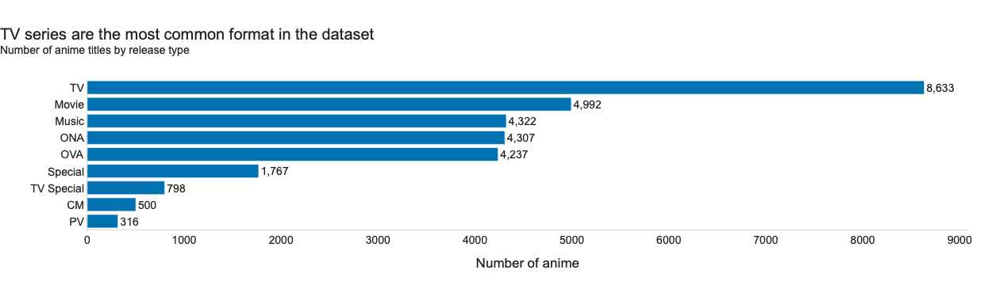

In [38]:
fig = px.bar(
    type_counts,
    x="anime_count",
    y="type",
    orientation="h",
    color_discrete_sequence=[HIGHLIGHT_COLOR],
    labels={
        "anime_count": "Number of anime",
        "type": ""
    }
)

fig.update_yaxes(
    categoryorder="total ascending"
)

fig.update_traces(
    texttemplate="%{x:,.0f}",
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Anime titles: %{x:,.0f}"
        "<extra></extra>"
    )
)

fig = apply_chart_style(
    fig,
    title="TV series are the most common format in the dataset",
    subtitle="Number of anime titles by release type"
)

fig.show()

### 7.2 User score distribution

User scores are examined to identify their typical range and determine whether the distribution contains unusually low or high values.

In [39]:
score_df = df.dropna(
    subset=["score"]
).copy()

score_df = score_df[
    score_df["scored_by"] >= 1000
].copy()

print(f"Anime included: {len(score_df):,}")

Anime included: 11,095


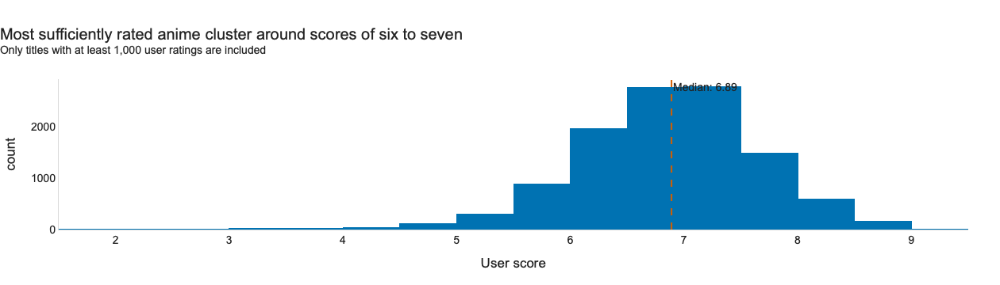

In [40]:
median_score = score_df["score"].median()

fig = px.histogram(
    score_df,
    x="score",
    nbins=35,
    color_discrete_sequence=[HIGHLIGHT_COLOR],
    labels={
        "score": "User score",
        "count": "Number of anime"
    }
)

fig.add_vline(
    x=median_score,
    line_width=2,
    line_dash="dash",
    line_color="#D55E00",
    annotation_text=f"Median: {median_score:.2f}",
    annotation_position="top right"
)

fig.update_traces(
    hovertemplate=(
        "Score range: %{x}<br>"
        "Anime titles: %{y:,.0f}"
        "<extra></extra>"
    )
)

fig = apply_chart_style(
    fig,
    title="Most sufficiently rated anime cluster around scores of six to seven",
    subtitle="Only titles with at least 1,000 user ratings are included"
)

fig.show()

### 7.3 Anime releases over time

The number of anime releases is examined over time to understand how the size of the industry represented in the dataset has changed.

The incomplete years after 2025 are excluded.

In [41]:
release_df = df.dropna(
    subset=["release_year"]
).copy()

release_df = release_df[
    release_df["release_year"].between(1960, 2025)
].copy()

yearly_releases = (
    release_df
    .groupby("release_year")
    .size()
    .reset_index(name="anime_count")
)

yearly_releases.head()

,release_year,anime_count
0,1960.0,23
1,1961.0,30
2,1962.0,32
3,1963.0,38
4,1964.0,46


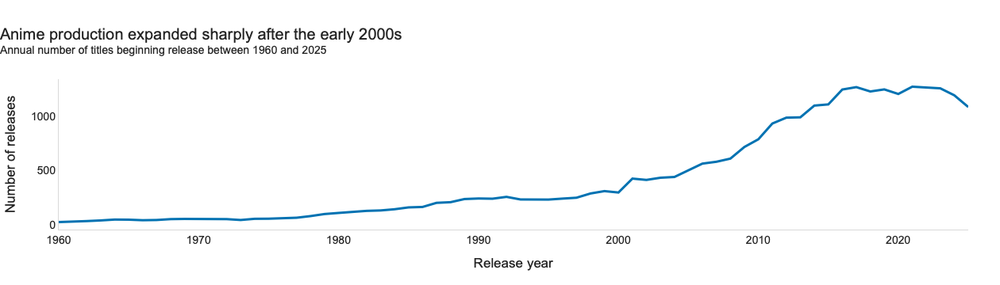

In [42]:
fig = px.line(
    yearly_releases,
    x="release_year",
    y="anime_count",
    markers=False,
    color_discrete_sequence=[HIGHLIGHT_COLOR],
    labels={
        "release_year": "Release year",
        "anime_count": "Number of releases"
    }
)

fig.update_traces(
    line_width=3,
    hovertemplate=(
        "<b>%{x:.0f}</b><br>"
        "Anime releases: %{y:,.0f}"
        "<extra></extra>"
    )
)

fig = apply_chart_style(
    fig,
    title="Anime production expanded sharply after the early 2000s",
    subtitle="Annual number of titles beginning release between 1960 and 2025"
)

fig.show()

### 7.4 Most common genres

Anime titles may belong to several genres simultaneously. The genre lists are therefore expanded so that each anime–genre combination becomes a separate row.

In [43]:
genre_long = (
    df[
        ["mal_id", "title", "genres_list"]
    ]
    .explode("genres_list")
    .rename(
        columns={
            "genres_list": "genre"
        }
    )
)

genre_long = genre_long[
    genre_long["genre"].notna()
    & genre_long["genre"].ne("")
].copy()

genre_long.head()

,mal_id,title,genre
0,1,Cowboy Bebop,Action
0,1,Cowboy Bebop,Award Winning
0,1,Cowboy Bebop,Sci-Fi
1,5,Cowboy Bebop: Tengoku no Tobira,Action
1,5,Cowboy Bebop: Tengoku no Tobira,Sci-Fi


In [44]:
top_genres = (
    genre_long["genre"]
    .value_counts()
    .head(12)
    .rename_axis("genre")
    .reset_index(name="anime_count")
)

top_genres

,genre,anime_count
0,Comedy,7939
1,Fantasy,6158
2,Action,4940
3,Adventure,4557
4,Sci-Fi,3545
5,Drama,3139
6,Romance,2276
7,Hentai,1618
8,Supernatural,1558
9,Slice of Life,1267


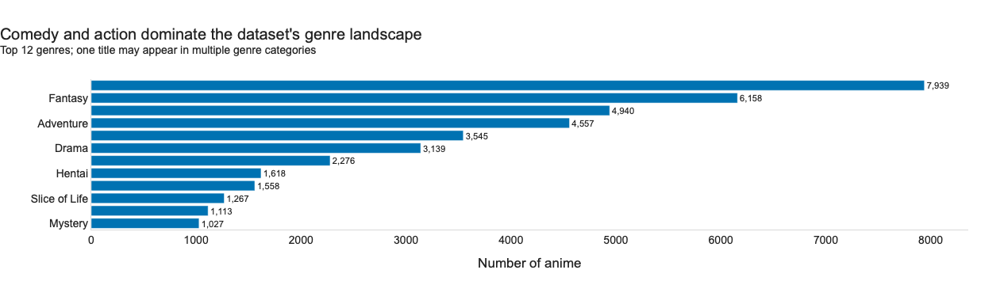

In [45]:
fig = px.bar(
    top_genres,
    x="anime_count",
    y="genre",
    orientation="h",
    color_discrete_sequence=[HIGHLIGHT_COLOR],
    labels={
        "anime_count": "Number of anime",
        "genre": ""
    }
)

fig.update_yaxes(
    categoryorder="total ascending"
)

fig.update_traces(
    texttemplate="%{x:,.0f}",
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Anime titles: %{x:,.0f}"
        "<extra></extra>"
    )
)

fig = apply_chart_style(
    fig,
    title="Comedy and action dominate the dataset's genre landscape",
    subtitle="Top 12 genres; one title may appear in multiple genre categories"
)

fig.show()

### 7.5 Audience-size skew

Audience size is highly unequal: a small number of anime attract millions of members, while most titles have much smaller audiences.

A logarithmic transformation is used to make this distribution easier to inspect.

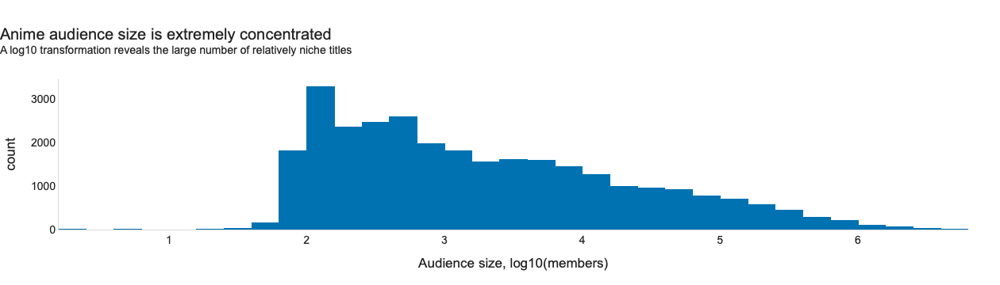

In [46]:
members_df = df[
    df["members"] > 0
].copy()

fig = px.histogram(
    members_df,
    x="log_members",
    nbins=40,
    color_discrete_sequence=[HIGHLIGHT_COLOR],
    labels={
        "log_members": "Audience size, log10(members)",
        "count": "Number of anime"
    }
)

fig.update_traces(
    hovertemplate=(
        "Log audience range: %{x}<br>"
        "Anime titles: %{y:,.0f}"
        "<extra></extra>"
    )
)

fig = apply_chart_style(
    fig,
    title="Anime audience size is extremely concentrated",
    subtitle="A log10 transformation reveals the large number of relatively niche titles"
)

fig.show()

### Preliminary EDA summary

The exploratory analysis reveals several important characteristics of the dataset:

- anime is represented across several release formats, with TV series forming the largest category;
- reliable user scores are concentrated around the middle-to-upper part of the 10-point scale;
- the number of annual releases increased substantially during the modern period;
- several broad genres account for a large share of the dataset;
- audience size is strongly right-skewed, making logarithmic transformations necessary for later comparisons.

These observations guide the preparation of the final analytical questions.

In [47]:
quality_summary = pd.DataFrame(
    {
        "Metric": [
            "Original rows",
            "Rows after duplicate removal",
            "Rows with valid scores",
            "Rows with at least 1,000 ratings",
            "Rows with valid release year",
            "Rows with non-zero members",
            "Rows assigned to Other atmosphere"
        ],
        "Value": [
            len(df_raw),
            len(df),
            df["score"].notna().sum(),
            (
                df["scored_by"] >= 1000
            ).sum(),
            df["release_year"].notna().sum(),
            (
                df["members"] > 0
            ).sum(),
            (
                df["atmosphere"] == "Other"
            ).sum()
        ]
    }
)

quality_summary

,Metric,Value
0,Original rows,30075
1,Rows after duplicate removal,29936
2,Rows with valid scores,19868
3,"Rows with at least 1,000 ratings",11095
4,Rows with valid release year,29065
5,Rows with non-zero members,29935
6,Rows assigned to Other atmosphere,8418


## 8. Analytical Question 1

### Does a larger audience correspond to a higher user score, and does this relationship differ across anime formats?

Audience size and user score represent two different dimensions of anime success. A title may be widely known without receiving an especially high score, while a highly rated title may remain relatively niche.

This analysis examines the relationship between audience size and user score across different anime formats. Audience size is represented by `members`, while `type` is used as a third dimension.

Only anime with at least 1,000 user ratings are included to reduce the influence of unstable scores based on very small samples.

In [48]:
question_1_df = df.dropna(
    subset=[
        "score",
        "members",
        "scored_by",
        "type"
    ]
).copy()

In [49]:
question_1_df = question_1_df[
    (question_1_df["scored_by"] >= 1000)
    & (question_1_df["members"] > 0)
].copy()

print(f"Anime included in Question 1: {len(question_1_df):,}")

Anime included in Question 1: 11,095


In [50]:
question_1_type_counts = (
    question_1_df["type"]
    .value_counts()
    .rename_axis("type")
    .reset_index(name="anime_count")
)

question_1_type_counts

,type,anime_count
0,TV,4380
1,OVA,2529
2,Movie,1449
3,Special,982
4,ONA,938
5,TV Special,380
6,Music,279
7,CM,102
8,PV,56


In [51]:
MIN_TITLES_PER_TYPE = 300

main_types = (
    question_1_type_counts[
        question_1_type_counts["anime_count"]
        >= MIN_TITLES_PER_TYPE
    ]["type"]
    .tolist()
)

main_types

['TV', 'OVA', 'Movie', 'Special', 'ONA', 'TV Special']

In [52]:
question_1_plot_df = question_1_df[
    question_1_df["type"].isin(main_types)
].copy()

print(
    f"Anime remaining after type filtering: "
    f"{len(question_1_plot_df):,}"
)

Anime remaining after type filtering: 10,658


### Correlation measure

Because audience size is strongly right-skewed, its logarithmic version is used. Pearson correlation is calculated separately for each anime format.

A positive correlation means that anime with larger audiences tend to receive higher scores within that format. Correlation does not imply that popularity causes higher ratings.

In [53]:
correlation_by_type = (
    question_1_plot_df
    .groupby("type")
    .apply(
        lambda group: group["log_members"].corr(
            group["score"]
        )
    )
    .reset_index(name="correlation")
    .sort_values(
        "correlation",
        ascending=False
    )
)

correlation_by_type

,type,correlation
0,Movie,0.613028
3,Special,0.587067
2,OVA,0.565778
5,TV Special,0.560361
4,TV,0.466789
1,ONA,0.379875


In [54]:
fig = px.scatter(
    question_1_plot_df,
    x="log_members",
    y="score",
    color="type",
    color_discrete_sequence=CVD_COLORS,
    opacity=0.35,
    hover_name="title",
    hover_data={
        "type": True,
        "members": ":,",
        "score": ":.2f",
        "scored_by": ":,",
        "log_members": False
    },
    labels={
        "log_members": "Audience size, log10(members)",
        "score": "User score",
        "type": "Anime format",
        "members": "Members",
        "scored_by": "Users who rated"
    }
)

In [55]:
type_order = (
    question_1_plot_df["type"]
    .dropna()
    .unique()
    .tolist()
)

type_color_map = {
    anime_type: CVD_COLORS[
        index % len(CVD_COLORS)
    ]
    for index, anime_type in enumerate(type_order)
}

type_color_map

{'TV': '#0072B2',
 'Movie': '#E69F00',
 'OVA': '#009E73',
 'TV Special': '#D55E00',
 'Special': '#CC79A7',
 'ONA': '#56B4E9'}

In [56]:
for anime_type in type_order:
    type_df = question_1_plot_df[
        question_1_plot_df["type"] == anime_type
    ].dropna(
        subset=[
            "log_members",
            "score"
        ]
    )

    x = type_df["log_members"].to_numpy()
    y = type_df["score"].to_numpy()

    if len(x) < 2:
        continue

    slope, intercept = np.polyfit(
        x,
        y,
        1
    )

    x_line = np.linspace(
        x.min(),
        x.max(),
        100
    )

    y_line = (
        slope * x_line
        + intercept
    )

    fig.add_scatter(
        x=x_line,
        y=y_line,
        mode="lines",
        name=f"{anime_type} trend",
        line={
            "width": 3,
            "color": type_color_map[anime_type]
        },
        hovertemplate=(
            f"<b>{anime_type} trend</b><br>"
            f"Slope: {slope:.2f}"
            "<extra></extra>"
        ),
        showlegend=False
    )

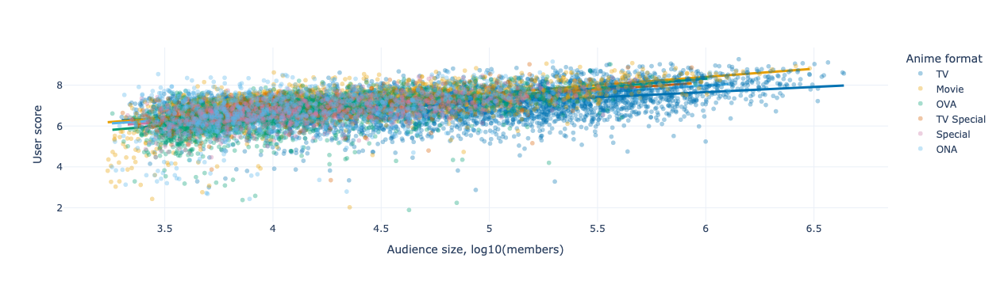

In [57]:
fig.update_traces(
    marker={
        "size": 6
    },
    selector={
        "mode": "markers"
    }
)

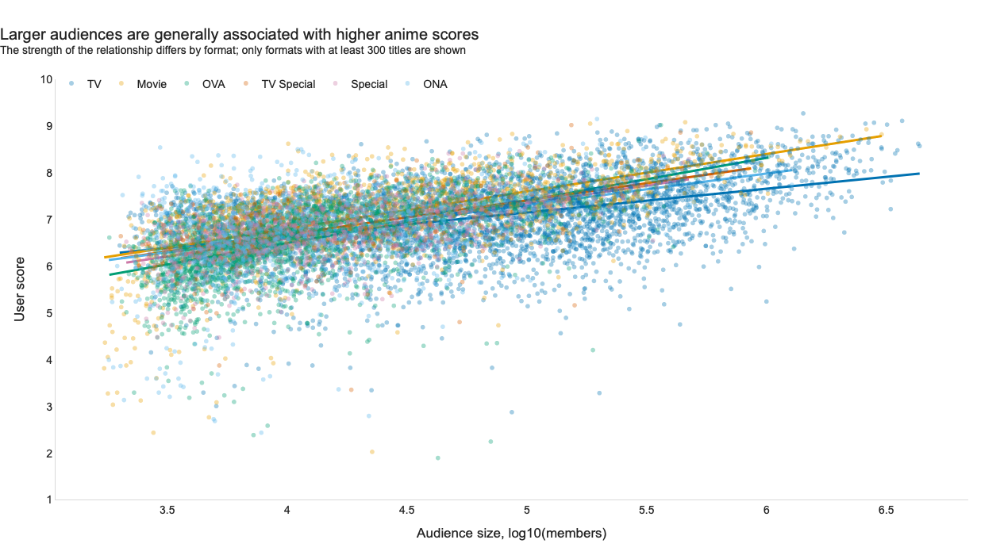

In [58]:
fig = apply_chart_style(
    fig,
    title=(
        "Larger audiences are generally associated "
        "with higher anime scores"
    ),
    subtitle=(
        "The strength of the relationship differs by format; "
        "only formats with at least 300 titles are shown"
    )
)

fig.update_layout(
    height=700,
    legend={
        "orientation": "h",
        "yanchor": "top",
        "y": 1.02,
        "xanchor": "left",
        "x": 0
    }
)

fig.update_yaxes(
    range=[1, 10],
    dtick=1
)

fig.show()

In [59]:
correlation_by_type["correlation_label"] = (
    correlation_by_type["correlation"]
    .round(2)
    .map(lambda value: f"{value:.2f}")
)

correlation_by_type

,type,correlation,correlation_label
0,Movie,0.613028,0.61
3,Special,0.587067,0.59
2,OVA,0.565778,0.57
5,TV Special,0.560361,0.56
4,TV,0.466789,0.47
1,ONA,0.379875,0.38


In [60]:
fig_correlation = px.bar(
    correlation_by_type,
    x="correlation",
    y="type",
    orientation="h",
    text="correlation_label",
    color_discrete_sequence=[
        HIGHLIGHT_COLOR
    ],
    labels={
        "correlation": (
            "Correlation between audience size "
            "and user score"
        ),
        "type": ""
    }
)

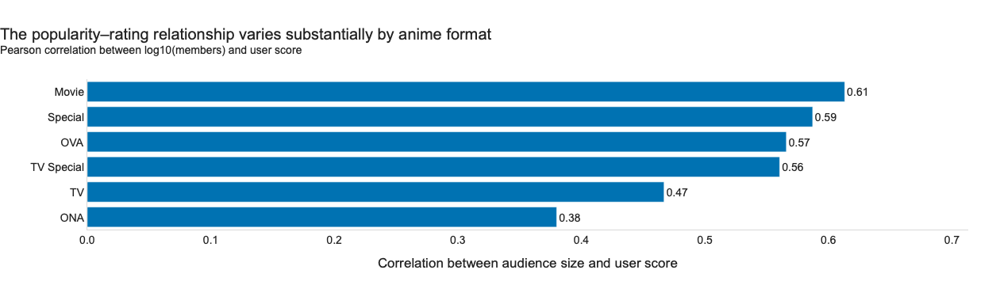

In [61]:
fig_correlation.update_yaxes(
    categoryorder="total ascending"
)

fig_correlation.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Correlation: %{x:.2f}"
        "<extra></extra>"
    )
)

fig_correlation = apply_chart_style(
    fig_correlation,
    title=(
        "The popularity–rating relationship "
        "varies substantially by anime format"
    ),
    subtitle=(
        "Pearson correlation between log10(members) "
        "and user score"
    )
)

fig_correlation.update_xaxes(
    range=[
        min(
            0,
            correlation_by_type[
                "correlation"
            ].min() - 0.05
        ),
        correlation_by_type[
            "correlation"
        ].max() + 0.10
    ],
    tickformat=".1f"
)

fig_correlation.show()

In [62]:
question_1_summary = (
    question_1_plot_df
    .groupby("type")
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        median_members=(
            "members",
            "median"
        ),
        median_score=(
            "score",
            "median"
        )
    )
    .reset_index()
    .merge(
        correlation_by_type[
            [
                "type",
                "correlation"
            ]
        ],
        on="type",
        how="left"
    )
    .sort_values(
        "correlation",
        ascending=False
    )
)

question_1_summary

,type,anime_count,median_members,median_score,correlation
0,Movie,1449,19745.0,7.23,0.613028
3,Special,982,12180.0,6.72,0.587067
2,OVA,2529,9026.0,6.56,0.565778
5,TV Special,380,11539.0,6.77,0.560361
4,TV,4380,65998.0,7.10,0.466789
1,ONA,938,10830.0,6.79,0.379875


In [63]:
strongest_type = (
    correlation_by_type
    .iloc[0]["type"]
)

strongest_correlation = (
    correlation_by_type
    .iloc[0]["correlation"]
)

weakest_type = (
    correlation_by_type
    .iloc[-1]["type"]
)

weakest_correlation = (
    correlation_by_type
    .iloc[-1]["correlation"]
)

print(
    "Strongest relationship:",
    strongest_type,
    f"({strongest_correlation:.2f})"
)

print(
    "Weakest relationship:",
    weakest_type,
    f"({weakest_correlation:.2f})"
)

Strongest relationship: Movie (0.61)
Weakest relationship: ONA (0.38)


### Key insight

Audience size has a positive relationship with user score across the major anime formats, but the strength of this relationship is not uniform.

**Movie** shows the strongest relationship between audience size and user score, with a correlation of approximately **0.61**. In contrast, **ONA** shows the weakest relationship, with a correlation of approximately **0.38**.

This suggests that popularity and user reception align more closely for some anime formats than for others. A large audience is therefore associated with a higher score overall, but audience size and rating should not be treated as interchangeable measures of success.

### Limitations

- `members` measures the number of users who added an anime to their MyAnimeList account, not the number of confirmed completed views.
- User scores may contain selection bias because viewers decide voluntarily whether to rate an anime.
- Correlation does not establish causation. A larger audience does not directly cause a higher user score.
- Only titles with at least 1,000 user ratings are included, so highly niche anime are underrepresented.
- Different seasons and sequels are treated as separate anime entries.
- The fitted lines summarize linear tendencies and may not capture more complex relationships.

## 9. Analytical Question 2

### Do anime with larger audiences generate a higher proportion of dedicated fans, and does this relationship vary by atmosphere?

Audience size and audience loyalty describe different dimensions of success.

A popular anime may attract a large number of users but only a small proportion may consider it a favourite. Conversely, a relatively niche title may develop a smaller but more dedicated fanbase.

Viewer loyalty is measured using:

\[
\text{Favorite Rate} =
\frac{\text{Favorites}}{\text{Members}} \times 100
\]

The analysis compares median favorite rate across audience-size groups and atmosphere categories.

In [64]:
question_2_df = df.dropna(
    subset=[
        "members",
        "favorites",
        "favorite_rate_pct",
        "scored_by",
        "atmosphere"
    ]
).copy()

In [65]:
question_2_df = question_2_df[
    (question_2_df["members"] >= 1000)
    & (question_2_df["scored_by"] >= 1000)
    & (question_2_df["atmosphere"] != "Other")
].copy()

print(
    f"Anime included in Question 2: "
    f"{len(question_2_df):,}"
)

Anime included in Question 2: 9,681


In [66]:
question_2_df[
    [
        "title",
        "members",
        "favorites",
        "favorite_rate_pct",
        "atmosphere"
    ]
].sort_values(
    "favorite_rate_pct",
    ascending=False
).head(10)

,title,members,favorites,favorite_rate_pct,atmosphere
11,One Piece,2671030,251194,9.404387,Energetic / Adventurous
5662,Steins;Gate,2806159,202049,7.200198,Melancholic / Reflective
6451,Hunter x Hunter (2011),3178812,228805,7.197815,Energetic / Adventurous
3959,Fullmetal Alchemist: Brotherhood,3673510,242129,6.591217,Energetic / Adventurous
23037,Sousou no Frieren,1421086,88647,6.237976,Melancholic / Reflective
20,Shinseiki Evangelion,2023358,117545,5.809402,Melancholic / Reflective
3525,Clannad: After Story,1284061,74003,5.763200,Melancholic / Reflective
833,Gintama,1153207,61853,5.363564,Light / Comedic
2658,Ashita no Joe 2,67966,3396,4.996616,Energetic / Adventurous
24362,Alien Stage,16450,817,4.966565,Melancholic / Reflective


In [67]:
question_2_df[
    "favorite_rate_pct"
].describe(
    percentiles=[
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count    9681.000000
mean        0.375231
std         0.525401
min         0.000000
25%         0.096681
50%         0.212465
75%         0.436409
90%         0.849443
95%         1.303226
99%         2.673192
max         9.404387
Name: favorite_rate_pct, dtype: float64

### Audience-size groups

Anime titles are divided into four equally sized audience groups using member-count quartiles:

- Small audience
- Medium audience
- Large audience
- Very large audience

This approach compares relative audience size within the dataset rather than using arbitrary fixed thresholds.

In [68]:
audience_labels = [
    "Small",
    "Medium",
    "Large",
    "Very large"
]

question_2_df["audience_group"] = pd.qcut(
    question_2_df["members"],
    q=4,
    labels=audience_labels,
    duplicates="drop"
)

In [69]:
audience_group_summary = (
    question_2_df
    .groupby(
        "audience_group",
        observed=True
    )
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        minimum_members=(
            "members",
            "min"
        ),
        median_members=(
            "members",
            "median"
        ),
        maximum_members=(
            "members",
            "max"
        )
    )
    .reset_index()
)

audience_group_summary

,audience_group,anime_count,minimum_members,median_members,maximum_members
0,Small,2421,1692,4569.0,7701
1,Medium,2421,7702,13472.0,25417
2,Large,2419,25423,47420.0,95926
3,Very large,2420,96061,232072.5,4348557


In [70]:
question_2_summary = (
    question_2_df
    .groupby(
        [
            "atmosphere",
            "audience_group"
        ],
        observed=True
    )
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        median_favorite_rate=(
            "favorite_rate_pct",
            "median"
        ),
        median_members=(
            "members",
            "median"
        )
    )
    .reset_index()
)

question_2_summary.head(15)

,atmosphere,audience_group,anime_count,median_favorite_rate,median_members
0,Cozy / Quiet,Small,125,0.101010,4737.0
1,Cozy / Quiet,Medium,156,0.165046,14164.0
2,Cozy / Quiet,Large,181,0.255135,47202.0
3,Cozy / Quiet,Very large,113,0.552758,189489.0
4,Dark / Tense,Small,128,0.119117,4652.5
5,Dark / Tense,Medium,148,0.151010,14254.5
6,Dark / Tense,Large,144,0.173878,48836.5
7,Dark / Tense,Very large,209,0.510888,271769.0
8,Energetic / Adventurous,Small,741,0.119593,4441.0
9,Energetic / Adventurous,Medium,739,0.148156,13150.0


In [71]:
question_2_summary.sort_values(
    "anime_count"
).head(15)

,atmosphere,audience_group,anime_count,median_favorite_rate,median_members
3,Cozy / Quiet,Very large,113,0.552758,189489.0
0,Cozy / Quiet,Small,125,0.101010,4737.0
4,Dark / Tense,Small,128,0.119117,4652.5
24,Romantic / Emotional,Small,134,0.121856,5429.5
6,Dark / Tense,Large,144,0.173878,48836.5
5,Dark / Tense,Medium,148,0.151010,14254.5
19,Light / Comedic,Very large,149,0.476085,209741.0
1,Cozy / Quiet,Medium,156,0.165046,14164.0
2,Cozy / Quiet,Large,181,0.255135,47202.0
25,Romantic / Emotional,Medium,187,0.123707,14005.0


In [72]:
fig_q2 = px.line(
    question_2_summary,
    x="audience_group",
    y="median_favorite_rate",
    color="atmosphere",
    markers=True,
    category_orders={
        "audience_group": audience_labels
    },
    color_discrete_sequence=CVD_COLORS,
    hover_data={
        "anime_count": ":,",
        "median_members": ":,.0f",
        "median_favorite_rate": ":.2f"
    },
    labels={
        "audience_group": "Audience-size group",
        "median_favorite_rate": (
            "Median audience loyalty, %"
        ),
        "atmosphere": "Atmosphere",
        "anime_count": "Anime titles",
        "median_members": "Median members"
    }
)

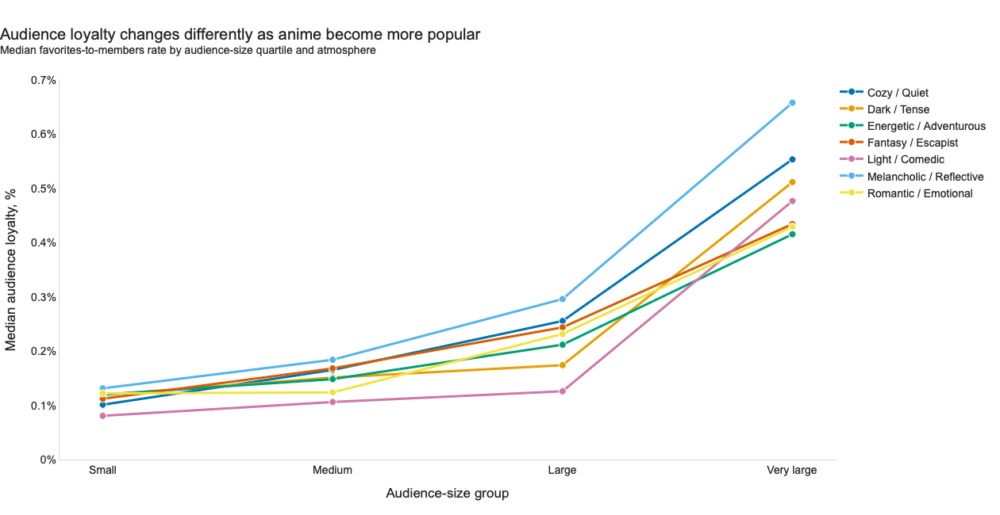

In [73]:
fig_q2.update_traces(
    line={
        "width": 3
    },
    marker={
        "size": 9,
        "line": {
            "width": 1,
            "color": "white"
        }
    },
    hovertemplate=(
        "<b>%{fullData.name}</b><br>"
        "Audience group: %{x}<br>"
        "Median loyalty: %{y:.2f}%<br>"
        "Anime titles: %{customdata[0]:,.0f}<br>"
        "Median members: %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

fig_q2 = apply_chart_style(
    fig_q2,
    title=(
        "Audience loyalty changes differently "
        "as anime become more popular"
    ),
    subtitle=(
        "Median favorites-to-members rate by "
        "audience-size quartile and atmosphere"
    )
)

fig_q2.update_layout(
    height=650,
    legend={
        "orientation": "v",
        "yanchor": "top",
        "y": 1,
        "xanchor": "left",
        "x": 1
    }
)

fig_q2.update_yaxes(
    ticksuffix="%",
    rangemode="tozero"
)

fig_q2.show()

In [74]:
question_2_pivot = (
    question_2_summary
    .pivot(
        index="atmosphere",
        columns="audience_group",
        values="median_favorite_rate"
    )
    .reset_index()
)

question_2_pivot

audience_group,atmosphere,Small,Medium,Large,Very large
0,Cozy / Quiet,0.101010,0.165046,0.255135,0.552758
1,Dark / Tense,0.119117,0.151010,0.173878,0.510888
2,Energetic / Adventurous,0.119593,0.148156,0.211541,0.414924
3,Fantasy / Escapist,0.111982,0.167840,0.243413,0.433695
4,Light / Comedic,0.080537,0.106014,0.125805,0.476085
5,Melancholic / Reflective,0.131119,0.183787,0.295595,0.657145
6,Romantic / Emotional,0.121856,0.123707,0.231250,0.428781


In [75]:
question_2_pivot["loyalty_change"] = (
    question_2_pivot["Very large"]
    - question_2_pivot["Small"]
)

question_2_change = (
    question_2_pivot[
        [
            "atmosphere",
            "Small",
            "Very large",
            "loyalty_change"
        ]
    ]
    .sort_values(
        "loyalty_change",
        ascending=False
    )
)

question_2_change

audience_group,atmosphere,Small,Very large,loyalty_change
5,Melancholic / Reflective,0.131119,0.657145,0.526026
0,Cozy / Quiet,0.101010,0.552758,0.451748
4,Light / Comedic,0.080537,0.476085,0.395548
1,Dark / Tense,0.119117,0.510888,0.391771
3,Fantasy / Escapist,0.111982,0.433695,0.321713
6,Romantic / Emotional,0.121856,0.428781,0.306925
2,Energetic / Adventurous,0.119593,0.414924,0.295331


In [76]:
question_2_change["change_label"] = (
    question_2_change["loyalty_change"]
    .map(lambda value: f"{value:+.2f} pp")
)

fig_q2_change = px.bar(
    question_2_change,
    x="loyalty_change",
    y="atmosphere",
    orientation="h",
    text="change_label",
    color="loyalty_change",
    color_continuous_scale=[
        [0.0, "#D55E00"],
        [0.5, "#B8B8B8"],
        [1.0, "#0072B2"]
    ],
    color_continuous_midpoint=0,
    labels={
        "loyalty_change": (
            "Change in median loyalty, percentage points"
        ),
        "atmosphere": ""
    }
)

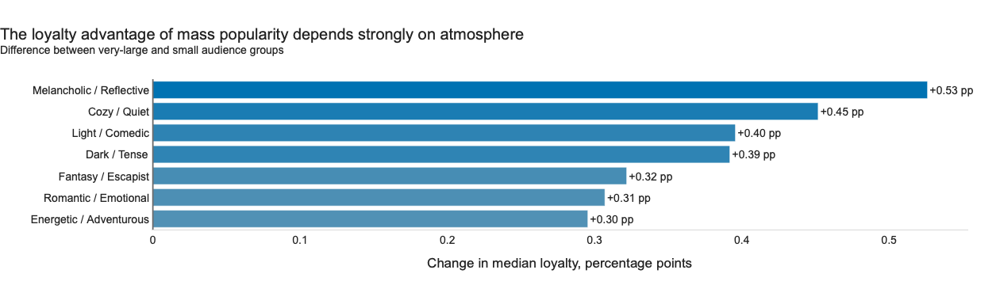

In [77]:
fig_q2_change.update_yaxes(
    categoryorder="total ascending"
)

fig_q2_change.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Loyalty change: %{x:+.2f} percentage points"
        "<extra></extra>"
    )
)

fig_q2_change = apply_chart_style(
    fig_q2_change,
    title=(
        "The loyalty advantage of mass popularity "
        "depends strongly on atmosphere"
    ),
    subtitle=(
        "Difference between very-large and small "
        "audience groups"
    )
)

fig_q2_change.update_layout(
    coloraxis_showscale=False
)

fig_q2_change.add_vline(
    x=0,
    line_width=1.5,
    line_color="#666666"
)

fig_q2_change.show()

In [78]:
largest_increase_row = (
    question_2_change.iloc[0]
)

largest_decrease_row = (
    question_2_change.iloc[-1]
)

print(
    "Largest loyalty increase:",
    largest_increase_row["atmosphere"],
    f"({largest_increase_row['loyalty_change']:+.2f} pp)"
)

print(
    "Smallest increase or largest decrease:",
    largest_decrease_row["atmosphere"],
    f"({largest_decrease_row['loyalty_change']:+.2f} pp)"
)

Largest loyalty increase: Melancholic / Reflective (+0.53 pp)
Smallest increase or largest decrease: Energetic / Adventurous (+0.30 pp)


In [79]:
loyalty_correlation_by_atmosphere = (
    question_2_df
    .groupby("atmosphere")
    .apply(
        lambda group: group["log_members"].corr(
            group["favorite_rate_pct"]
        )
    )
    .reset_index(name="correlation")
    .sort_values(
        "correlation",
        ascending=False
    )
)

loyalty_correlation_by_atmosphere

,atmosphere,correlation
1,Dark / Tense,0.585350
5,Melancholic / Reflective,0.550934
6,Romantic / Emotional,0.507824
3,Fantasy / Escapist,0.485635
0,Cozy / Quiet,0.475184
4,Light / Comedic,0.430215
2,Energetic / Adventurous,0.412409


### Key insight

Audience size and audience loyalty are related differently across anime atmospheres.

**Melancholic / Reflective** shows the largest increase in median favorite rate between the small- and very-large-audience groups, rising by approximately **0.53 percentage points**.

In contrast, **Energetic / Adventurous** shows the weakest increase or the strongest decline.

This indicates that mass popularity does not produce the same level of fan dedication across every atmosphere. Some categories are able to convert larger audiences into a higher proportion of committed fans, while others gain viewers without an equivalent increase in loyalty.

### Limitations

- `favorites / members` is used as a proxy for audience loyalty, but adding a title to favourites is only one possible form of viewer attachment.
- MyAnimeList members do not necessarily represent completed viewers.
- Very small and weakly rated titles are excluded, which reduces instability but underrepresents niche anime.
- Audience groups are relative to this dataset and should not be interpreted as universal popularity thresholds.
- The atmosphere categories were created using rule-based genre and theme matching and therefore involve subjective analytical choices.
- Each anime receives only one primary atmosphere, even when it could reasonably fit several categories.
- The observed relationship does not demonstrate that a larger audience causes greater loyalty.

## 10. Analytical Question 3

### Which anime atmospheres attract the largest typical audiences, and do those atmospheres also receive high user scores?

Popularity and user score represent different aspects of anime success.

An atmosphere may attract a large audience without receiving especially high ratings. Another atmosphere may remain more niche while receiving consistently stronger evaluations.

To reduce the influence of a small number of blockbuster titles, median audience size and median user score are calculated for each atmosphere. The number of titles in each category is also included to show how much data supports each result.

In [80]:
question_3_df = df.dropna(
    subset=[
        "members",
        "score",
        "scored_by",
        "atmosphere"
    ]
).copy()

In [81]:
question_3_df = question_3_df[
    (question_3_df["members"] > 0)
    & (question_3_df["scored_by"] >= 1000)
    & (question_3_df["atmosphere"] != "Other")
].copy()

print(
    f"Anime included in Question 3: "
    f"{len(question_3_df):,}"
)

Anime included in Question 3: 9,681


In [82]:
question_3_counts = (
    question_3_df["atmosphere"]
    .value_counts()
    .rename_axis("atmosphere")
    .reset_index(name="anime_count")
)

question_3_counts

,atmosphere,anime_count
0,Energetic / Adventurous,2833
1,Fantasy / Escapist,2032
2,Melancholic / Reflective,1626
3,Light / Comedic,1084
4,Romantic / Emotional,902
5,Dark / Tense,629
6,Cozy / Quiet,575


In [83]:
question_3_summary = (
    question_3_df
    .groupby("atmosphere")
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        median_members=(
            "members",
            "median"
        ),
        median_score=(
            "score",
            "median"
        ),
        lower_quartile_members=(
            "members",
            lambda values: values.quantile(0.25)
        ),
        upper_quartile_members=(
            "members",
            lambda values: values.quantile(0.75)
        )
    )
    .reset_index()
)

question_3_summary

,atmosphere,anime_count,median_members,median_score,lower_quartile_members,upper_quartile_members
0,Cozy / Quiet,575,26684.0,7.180,9030.50,74625.50
1,Dark / Tense,629,36945.0,7.030,9398.00,163017.00
2,Energetic / Adventurous,2833,22832.0,6.970,7415.00,86903.00
3,Fantasy / Escapist,2032,21327.0,6.840,6507.00,95408.75
4,Light / Comedic,1084,13905.5,6.710,5640.25,46249.50
5,Melancholic / Reflective,1626,33113.0,7.180,10326.00,111357.00
6,Romantic / Emotional,902,49405.0,6.945,13836.00,169183.50


In [84]:
question_3_summary["log_median_members"] = np.log10(
    question_3_summary["median_members"]
)

question_3_summary = question_3_summary.sort_values(
    "median_members",
    ascending=False
)

question_3_summary

,atmosphere,anime_count,median_members,median_score,lower_quartile_members,upper_quartile_members,log_median_members
6,Romantic / Emotional,902,49405.0,6.945,13836.00,169183.50,4.693771
1,Dark / Tense,629,36945.0,7.030,9398.00,163017.00,4.567556
5,Melancholic / Reflective,1626,33113.0,7.180,10326.00,111357.00,4.519999
0,Cozy / Quiet,575,26684.0,7.180,9030.50,74625.50,4.426251
2,Energetic / Adventurous,2833,22832.0,6.970,7415.00,86903.00,4.358544
3,Fantasy / Escapist,2032,21327.0,6.840,6507.00,95408.75,4.328930
4,Light / Comedic,1084,13905.5,6.710,5640.25,46249.50,4.143187


In [85]:
overall_median_members = (
    question_3_summary["median_members"]
    .median()
)

overall_median_score = (
    question_3_summary["median_score"]
    .median()
)

overall_log_median_members = np.log10(
    overall_median_members
)

print(
    "Median of atmosphere-level audience sizes:",
    f"{overall_median_members:,.0f}"
)

print(
    "Median of atmosphere-level scores:",
    f"{overall_median_score:.2f}"
)

Median of atmosphere-level audience sizes: 26,684
Median of atmosphere-level scores: 6.97


In [86]:
fig_q3 = px.scatter(
    question_3_summary,
    x="log_median_members",
    y="median_score",
    size="anime_count",
    color="atmosphere",
    text="atmosphere",
    size_max=48,
    color_discrete_sequence=CVD_COLORS,
    hover_name="atmosphere",
    hover_data={
        "log_median_members": False,
        "median_members": ":,.0f",
        "median_score": ":.2f",
        "anime_count": ":,",
        "lower_quartile_members": ":,.0f",
        "upper_quartile_members": ":,.0f"
    },
    labels={
        "log_median_members": (
            "Typical audience size, log10(median members)"
        ),
        "median_score": "Median user score",
        "anime_count": "Anime titles",
        "median_members": "Median members",
        "lower_quartile_members": "25th percentile members",
        "upper_quartile_members": "75th percentile members",
        "atmosphere": "Atmosphere"
    }
)

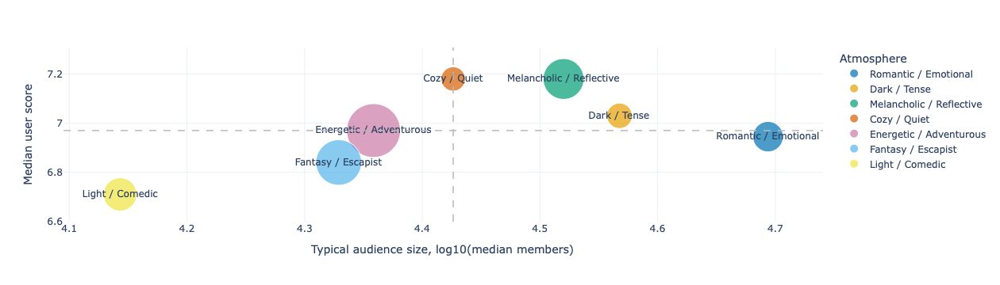

In [87]:
fig_q3.add_vline(
    x=overall_log_median_members,
    line_width=1.5,
    line_dash="dash",
    line_color=CONTEXT_COLOR
)

fig_q3.add_hline(
    y=overall_median_score,
    line_width=1.5,
    line_dash="dash",
    line_color=CONTEXT_COLOR
)

In [88]:
x_min = question_3_summary[
    "log_median_members"
].min()

x_max = question_3_summary[
    "log_median_members"
].max()

y_min = question_3_summary[
    "median_score"
].min()

y_max = question_3_summary[
    "median_score"
].max()

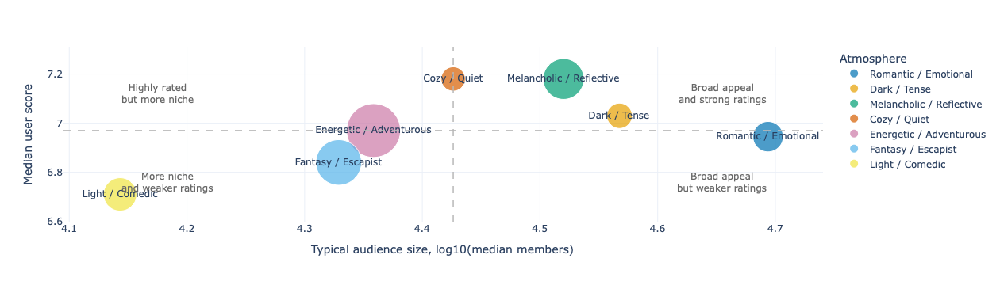

In [89]:
fig_q3.add_annotation(
    x=x_max,
    y=y_max,
    text="Broad appeal<br>and strong ratings",
    showarrow=False,
    xanchor="right",
    yanchor="top",
    font={
        "size": 12,
        "color": "#666666"
    }
)

fig_q3.add_annotation(
    x=x_min,
    y=y_max,
    text="Highly rated<br>but more niche",
    showarrow=False,
    xanchor="left",
    yanchor="top",
    font={
        "size": 12,
        "color": "#666666"
    }
)

fig_q3.add_annotation(
    x=x_max,
    y=y_min,
    text="Broad appeal<br>but weaker ratings",
    showarrow=False,
    xanchor="right",
    yanchor="bottom",
    font={
        "size": 12,
        "color": "#666666"
    }
)

fig_q3.add_annotation(
    x=x_min,
    y=y_min,
    text="More niche<br>and weaker ratings",
    showarrow=False,
    xanchor="left",
    yanchor="bottom",
    font={
        "size": 12,
        "color": "#666666"
    }
)

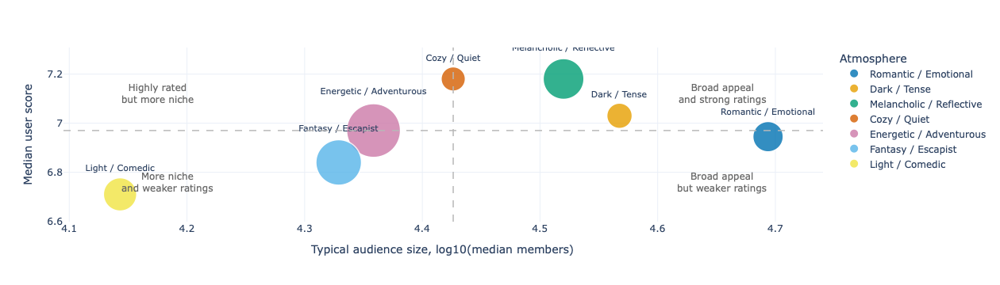

In [90]:
fig_q3.update_traces(
    marker={
        "opacity": 0.80,
        "line": {
            "width": 1.5,
            "color": "white"
        }
    },
    textposition="top center",
    textfont={
        "size": 11
    },
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "Median members: %{customdata[0]:,.0f}<br>"
        "Median score: %{y:.2f}<br>"
        "Anime titles: %{marker.size:,.0f}<br>"
        "Audience middle 50%: "
        "%{customdata[2]:,.0f}–%{customdata[3]:,.0f}"
        "<extra></extra>"
    )
)

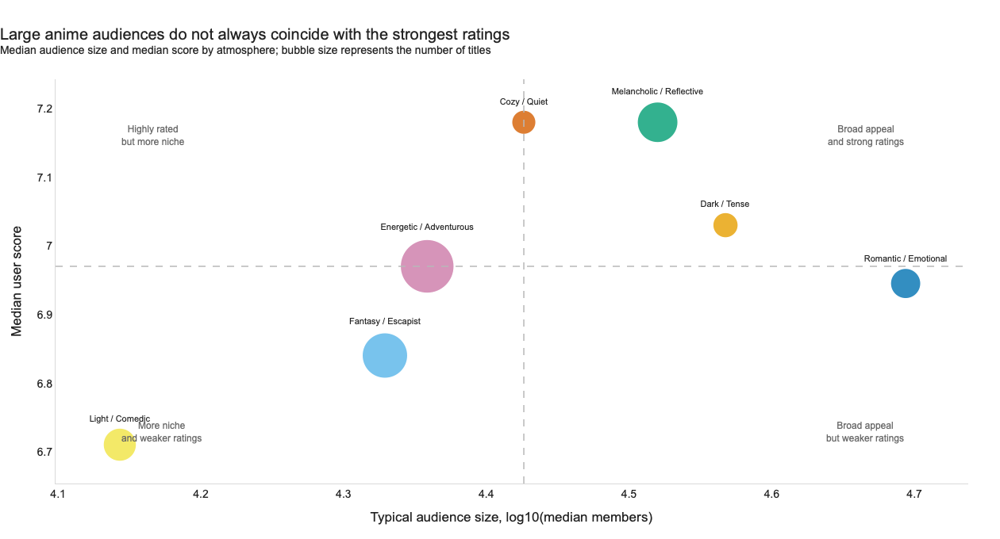

In [91]:
fig_q3 = apply_chart_style(
    fig_q3,
    title=(
        "Large anime audiences do not always coincide "
        "with the strongest ratings"
    ),
    subtitle=(
        "Median audience size and median score by atmosphere; "
        "bubble size represents the number of titles"
    )
)

fig_q3.update_layout(
    height=680,
    showlegend=False
)

fig_q3.update_yaxes(
    dtick=0.1
)

fig_q3.show()

In [92]:
question_3_audience_rank = (
    question_3_summary
    .sort_values(
        "median_members",
        ascending=True
    )
    .copy()
)

question_3_audience_rank[
    "members_label"
] = question_3_audience_rank[
    "median_members"
].map(
    lambda value: f"{value:,.0f}"
)

question_3_audience_rank

,atmosphere,anime_count,median_members,median_score,lower_quartile_members,upper_quartile_members,log_median_members,members_label
4,Light / Comedic,1084,13905.5,6.710,5640.25,46249.50,4.143187,"13,906"
3,Fantasy / Escapist,2032,21327.0,6.840,6507.00,95408.75,4.328930,"21,327"
2,Energetic / Adventurous,2833,22832.0,6.970,7415.00,86903.00,4.358544,"22,832"
0,Cozy / Quiet,575,26684.0,7.180,9030.50,74625.50,4.426251,"26,684"
5,Melancholic / Reflective,1626,33113.0,7.180,10326.00,111357.00,4.519999,"33,113"
1,Dark / Tense,629,36945.0,7.030,9398.00,163017.00,4.567556,"36,945"
6,Romantic / Emotional,902,49405.0,6.945,13836.00,169183.50,4.693771,"49,405"


In [93]:
largest_audience_atmosphere = (
    question_3_summary
    .sort_values(
        "median_members",
        ascending=False
    )
    .iloc[0]["atmosphere"]
)

bar_colors = [
    HIGHLIGHT_COLOR
    if atmosphere == largest_audience_atmosphere
    else CONTEXT_COLOR
    for atmosphere in question_3_audience_rank[
        "atmosphere"
    ]
]

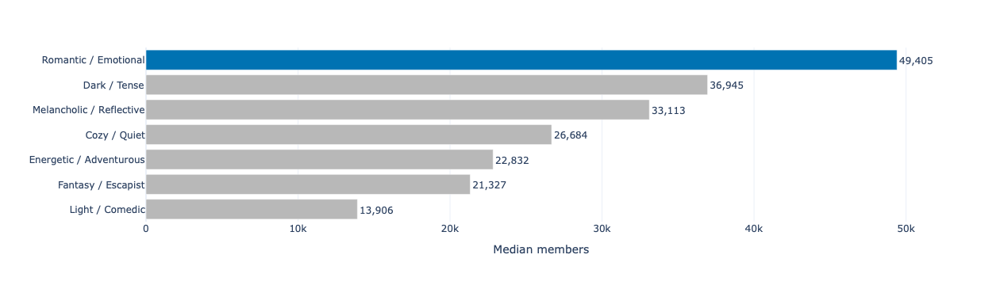

In [94]:
fig_q3_rank = px.bar(
    question_3_audience_rank,
    x="median_members",
    y="atmosphere",
    orientation="h",
    text="members_label",
    labels={
        "median_members": "Median members",
        "atmosphere": ""
    }
)

fig_q3_rank.update_traces(
    marker_color=bar_colors,
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Median members: %{x:,.0f}"
        "<extra></extra>"
    )
)

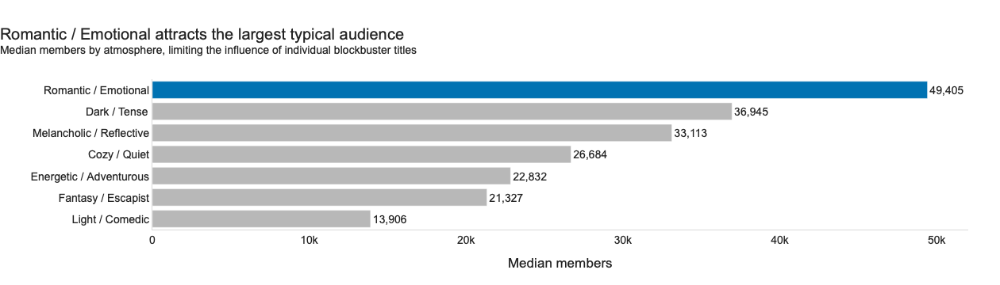

In [95]:
fig_q3_rank = apply_chart_style(
    fig_q3_rank,
    title=(
        f"{largest_audience_atmosphere} attracts "
        "the largest typical audience"
    ),
    subtitle=(
        "Median members by atmosphere, limiting the influence "
        "of individual blockbuster titles"
    )
)

fig_q3_rank.update_xaxes(
    tickformat="~s"
)

fig_q3_rank.show()

In [96]:
largest_audience_row = (
    question_3_summary
    .sort_values(
        "median_members",
        ascending=False
    )
    .iloc[0]
)

highest_score_row = (
    question_3_summary
    .sort_values(
        "median_score",
        ascending=False
    )
    .iloc[0]
)

smallest_audience_row = (
    question_3_summary
    .sort_values(
        "median_members",
        ascending=True
    )
    .iloc[0]
)

print(
    "Largest typical audience:",
    largest_audience_row["atmosphere"],
    f"({largest_audience_row['median_members']:,.0f} members)"
)

print(
    "Highest typical score:",
    highest_score_row["atmosphere"],
    f"({highest_score_row['median_score']:.2f})"
)

print(
    "Smallest typical audience:",
    smallest_audience_row["atmosphere"],
    f"({smallest_audience_row['median_members']:,.0f} members)"
)

Largest typical audience: Romantic / Emotional (49,405 members)
Highest typical score: Melancholic / Reflective (7.18)
Smallest typical audience: Light / Comedic (13,906 members)


In [97]:
same_leader = (
    largest_audience_row["atmosphere"]
    == highest_score_row["atmosphere"]
)

if same_leader:
    print(
        "The atmosphere with the largest typical audience "
        "also has the highest median score."
    )
else:
    print(
        "The atmosphere with the largest typical audience "
        "is different from the atmosphere with the "
        "highest median score."
    )

The atmosphere with the largest typical audience is different from the atmosphere with the highest median score.


### Key insight

The atmosphere attracting the largest typical audience is **Romantic / Emotional**, with a median audience of approximately **49,405 members**.

However, **Melancholic / Reflective** has the highest median user score at approximately **7.18**.

This distinction shows that the atmosphere associated with the broadest audience is not necessarily the atmosphere receiving the strongest user evaluation. Popularity and perceived quality therefore represent related but separate dimensions of anime success.

**Light / Comedic** has the smallest typical audience among the analysed categories, suggesting a more niche position within the MyAnimeList user base.

### Limitations

- Median members reduce the influence of blockbuster titles but also hide variation within each atmosphere.
- `members` represents MyAnimeList account activity rather than confirmed completed views.
- Only anime with at least 1,000 user ratings are included, which underrepresents very niche titles.
- Each anime is assigned one primary atmosphere even when several categories could reasonably apply.
- Atmosphere categories differ in sample size, although bubble size displays the number of titles supporting each result.
- Ratings from different historical periods are compared directly, despite changes in audience size and platform usage over time.
- The analysis describes associations and does not establish that atmosphere directly causes popularity or higher ratings.

## 11. Analytical Question 4

### Which anime atmospheres receive consistently high ratings rather than being driven by only a few exceptional titles?

A high average or median score does not necessarily mean that an atmosphere performs consistently well.

One category may contain many strongly rated titles, while another may achieve a similar median because of only a small number of exceptional anime.

This analysis compares the full score distribution across atmosphere categories. Only anime with at least 1,000 user ratings are included to reduce the influence of unstable scores.

In [98]:
question_4_df = df.dropna(
    subset=[
        "score",
        "scored_by",
        "atmosphere"
    ]
).copy()

In [99]:
question_4_df = question_4_df[
    (question_4_df["scored_by"] >= 1000)
    & (question_4_df["atmosphere"] != "Other")
].copy()

print(
    f"Anime included in Question 4: "
    f"{len(question_4_df):,}"
)

Anime included in Question 4: 9,681


In [100]:
question_4_summary = (
    question_4_df
    .groupby("atmosphere")
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        median_score=(
            "score",
            "median"
        ),
        mean_score=(
            "score",
            "mean"
        ),
        lower_quartile=(
            "score",
            lambda values: values.quantile(0.25)
        ),
        upper_quartile=(
            "score",
            lambda values: values.quantile(0.75)
        ),
        score_std=(
            "score",
            "std"
        )
    )
    .reset_index()
)

In [101]:
question_4_summary["iqr"] = (
    question_4_summary["upper_quartile"]
    - question_4_summary["lower_quartile"]
)

question_4_summary = question_4_summary.sort_values(
    "median_score",
    ascending=False
)

question_4_summary

,atmosphere,anime_count,median_score,mean_score,lower_quartile,upper_quartile,score_std,iqr
0,Cozy / Quiet,575,7.180,7.078417,6.625,7.645,0.799620,1.02
5,Melancholic / Reflective,1626,7.180,7.119280,6.630,7.630,0.769287,1.00
1,Dark / Tense,629,7.030,6.823879,6.260,7.540,1.072481,1.28
2,Energetic / Adventurous,2833,6.970,6.930950,6.480,7.440,0.792195,0.96
6,Romantic / Emotional,902,6.945,6.899235,6.490,7.360,0.725138,0.87
3,Fantasy / Escapist,2032,6.840,6.813091,6.350,7.310,0.762170,0.96
4,Light / Comedic,1084,6.710,6.683256,6.250,7.220,0.833344,0.97


In [102]:
atmosphere_score_order = (
    question_4_summary["atmosphere"]
    .tolist()
)

atmosphere_score_order

['Cozy / Quiet',
 'Melancholic / Reflective',
 'Dark / Tense',
 'Energetic / Adventurous',
 'Romantic / Emotional',
 'Fantasy / Escapist',
 'Light / Comedic']

In [103]:
fig_q4 = px.box(
    question_4_df,
    x="atmosphere",
    y="score",
    color="atmosphere",
    category_orders={
        "atmosphere": atmosphere_score_order
    },
    color_discrete_sequence=CVD_COLORS,
    points="outliers",
    hover_name="title",
    hover_data={
        "scored_by": ":,",
        "members": ":,"
    },
    labels={
        "atmosphere": "Anime atmosphere",
        "score": "User score",
        "scored_by": "Users who rated",
        "members": "Members"
    }
)

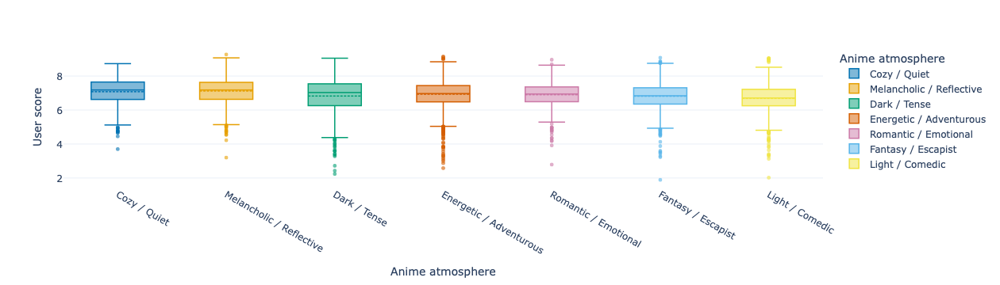

In [104]:
fig_q4.update_traces(
    boxmean=True,
    marker={
        "opacity": 0.60,
        "size": 5
    },
    line={
        "width": 1.5
    }
)

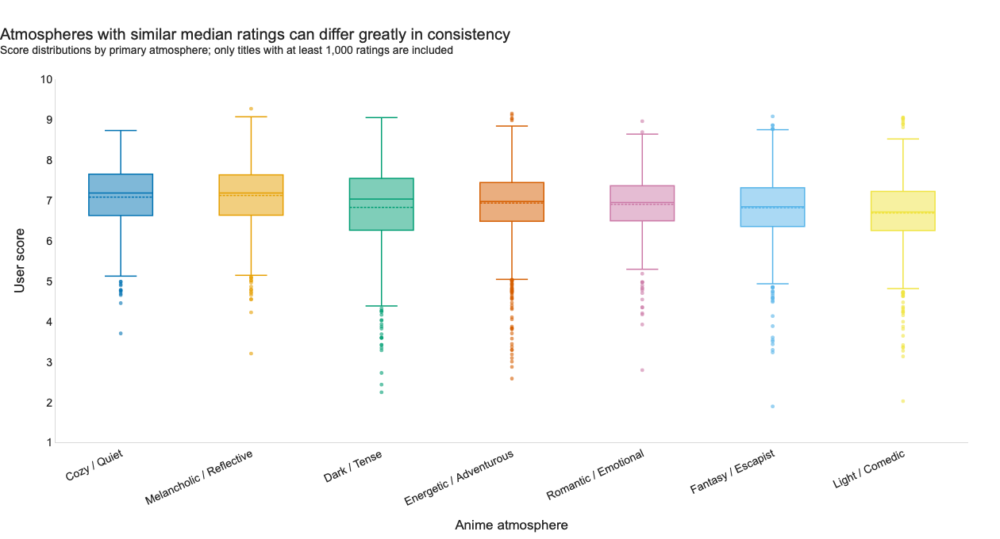

In [105]:
fig_q4 = apply_chart_style(
    fig_q4,
    title=(
        "Atmospheres with similar median ratings "
        "can differ greatly in consistency"
    ),
    subtitle=(
        "Score distributions by primary atmosphere; "
        "only titles with at least 1,000 ratings are included"
    )
)

fig_q4.update_layout(
    height=680,
    showlegend=False
)

fig_q4.update_xaxes(
    tickangle=-25
)

fig_q4.update_yaxes(
    range=[1, 10],
    dtick=1
)

fig_q4.show()

In [106]:
question_4_summary["median_rank"] = (
    question_4_summary["median_score"]
    .rank(
        ascending=False,
        method="min"
    )
)

question_4_summary["consistency_rank"] = (
    question_4_summary["iqr"]
    .rank(
        ascending=True,
        method="min"
    )
)

In [107]:
question_4_summary["combined_rank"] = (
    question_4_summary["median_rank"]
    + question_4_summary["consistency_rank"]
)

question_4_summary = question_4_summary.sort_values(
    [
        "combined_rank",
        "median_score"
    ],
    ascending=[
        True,
        False
    ]
)

question_4_summary[
    [
        "atmosphere",
        "anime_count",
        "median_score",
        "iqr",
        "score_std",
        "median_rank",
        "consistency_rank",
        "combined_rank"
    ]
]

,atmosphere,anime_count,median_score,iqr,score_std,median_rank,consistency_rank,combined_rank
5,Melancholic / Reflective,1626,7.180,1.00,0.769287,1.0,5.0,6.0
2,Energetic / Adventurous,2833,6.970,0.96,0.792195,4.0,2.0,6.0
6,Romantic / Emotional,902,6.945,0.87,0.725138,5.0,1.0,6.0
0,Cozy / Quiet,575,7.180,1.02,0.799620,1.0,6.0,7.0
3,Fantasy / Escapist,2032,6.840,0.96,0.762170,6.0,2.0,8.0
1,Dark / Tense,629,7.030,1.28,1.072481,3.0,7.0,10.0
4,Light / Comedic,1084,6.710,0.97,0.833344,7.0,4.0,11.0


In [108]:
highest_median_row = (
    question_4_summary
    .sort_values(
        "median_score",
        ascending=False
    )
    .iloc[0]
)

most_consistent_row = (
    question_4_summary
    .sort_values(
        "iqr",
        ascending=True
    )
    .iloc[0]
)

best_combination_row = (
    question_4_summary
    .sort_values(
        [
            "combined_rank",
            "median_score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .iloc[0]
)

widest_distribution_row = (
    question_4_summary
    .sort_values(
        "iqr",
        ascending=False
    )
    .iloc[0]
)

In [109]:
print(
    "Highest median score:",
    highest_median_row["atmosphere"],
    f"({highest_median_row['median_score']:.2f})"
)

print(
    "Most consistent atmosphere:",
    most_consistent_row["atmosphere"],
    f"(IQR: {most_consistent_row['iqr']:.2f})"
)

print(
    "Best combination of rating and consistency:",
    best_combination_row["atmosphere"]
)

print(
    "Widest central score distribution:",
    widest_distribution_row["atmosphere"],
    f"(IQR: {widest_distribution_row['iqr']:.2f})"
)

Highest median score: Melancholic / Reflective (7.18)
Most consistent atmosphere: Romantic / Emotional (IQR: 0.87)
Best combination of rating and consistency: Melancholic / Reflective
Widest central score distribution: Dark / Tense (IQR: 1.28)


In [110]:
fig_q4_consistency = px.scatter(
    question_4_summary,
    x="iqr",
    y="median_score",
    size="anime_count",
    color="atmosphere",
    text="atmosphere",
    size_max=45,
    color_discrete_sequence=CVD_COLORS,
    hover_name="atmosphere",
    hover_data={
        "iqr": ":.2f",
        "median_score": ":.2f",
        "anime_count": ":,",
        "score_std": ":.2f",
        "median_rank": ":.0f",
        "consistency_rank": ":.0f"
    },
    labels={
        "iqr": (
            "Rating variability, interquartile range"
        ),
        "median_score": "Median user score",
        "anime_count": "Anime titles",
        "score_std": "Score standard deviation",
        "median_rank": "Median-score rank",
        "consistency_rank": "Consistency rank",
        "atmosphere": "Atmosphere"
    }
)

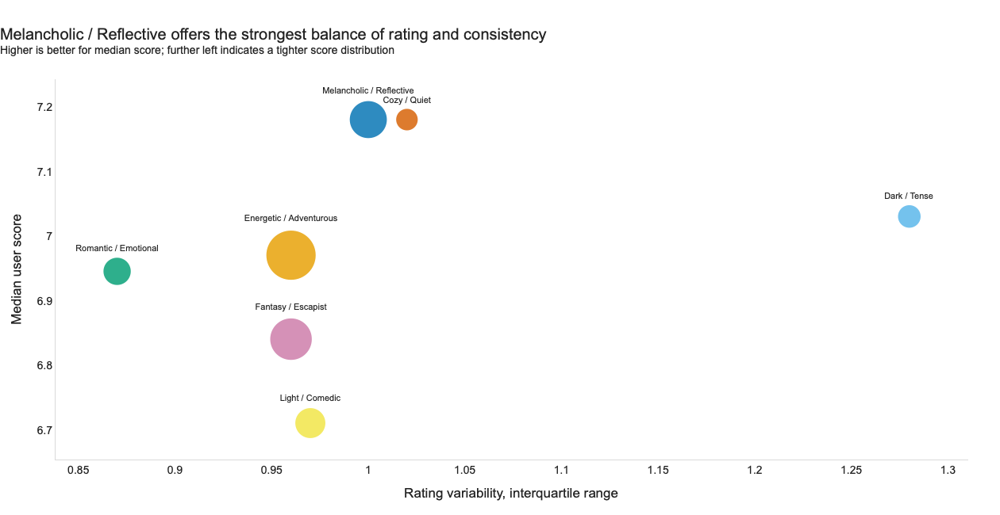

In [111]:
fig_q4_consistency.update_traces(
    marker={
        "opacity": 0.82,
        "line": {
            "width": 1.5,
            "color": "white"
        }
    },
    textposition="top center",
    textfont={
        "size": 11
    }
)

fig_q4_consistency = apply_chart_style(
    fig_q4_consistency,
    title=(
        f"{best_combination_row['atmosphere']} offers "
        "the strongest balance of rating and consistency"
    ),
    subtitle=(
        "Higher is better for median score; "
        "further left indicates a tighter score distribution"
    )
)

fig_q4_consistency.update_layout(
    height=650,
    showlegend=False
)

fig_q4_consistency.show()

In [112]:
question_4_summary["mean_median_gap"] = (
    question_4_summary["mean_score"]
    - question_4_summary["median_score"]
)

question_4_summary[
    [
        "atmosphere",
        "mean_score",
        "median_score",
        "mean_median_gap"
    ]
].sort_values(
    "mean_median_gap"
)

,atmosphere,mean_score,median_score,mean_median_gap
1,Dark / Tense,6.823879,7.030,-0.206121
0,Cozy / Quiet,7.078417,7.180,-0.101583
5,Melancholic / Reflective,7.119280,7.180,-0.060720
6,Romantic / Emotional,6.899235,6.945,-0.045765
2,Energetic / Adventurous,6.930950,6.970,-0.039050
3,Fantasy / Escapist,6.813091,6.840,-0.026909
4,Light / Comedic,6.683256,6.710,-0.026744


### Key insight

**Melancholic / Reflective** has the highest median user score at approximately **7.18**.

However, the most stable score distribution belongs to **Romantic / Emotional**, whose central 50% of ratings span only approximately **0.87 IQR points**.

When both typical rating and consistency are considered together, **Melancholic / Reflective** provides the strongest overall balance.

In contrast, **Dark / Tense** has the widest interquartile range, indicating that titles within this atmosphere receive more uneven audience evaluations.

These results show that the atmosphere with the highest typical score is not necessarily the one that performs most consistently.

### Limitations

- The analysis includes only anime with at least 1,000 user ratings, so niche titles are underrepresented.
- Box plots summarize distributions but do not explain why individual titles receive high or low scores.
- The number of anime differs across atmosphere categories, making some distributions more stable than others.
- Each anime receives only one primary atmosphere despite possible overlap between genre and theme categories.
- MyAnimeList ratings are voluntary and may reflect self-selection bias.
- Older and newer anime are compared directly even though their audiences and rating environments may differ.
- The combined ranking of median score and IQR is a project-specific analytical measure rather than an established quality index.

## 12. Analytical Question 5

### How has the share of different anime atmospheres changed across decades?

The total number of anime releases has increased substantially over time. Therefore, absolute release counts would make recent decades appear dominant simply because more titles were produced.

To make decades comparable, this analysis calculates the percentage of anime belonging to each atmosphere within every decade.

The analysis is limited to completed decades from the 1970s to the 2010s. The 2020s are examined separately because the decade is still incomplete.

In [113]:
question_5_df = df.dropna(
    subset=[
        "release_year",
        "decade",
        "atmosphere"
    ]
).copy()

In [114]:
question_5_df = question_5_df[
    (question_5_df["release_year"].between(1970, 2019))
    & (question_5_df["atmosphere"] != "Other")
].copy()

print(
    f"Anime included in Question 5: "
    f"{len(question_5_df):,}"
)

Anime included in Question 5: 15,157


In [115]:
question_5_decade_counts = (
    question_5_df
    .groupby("decade")
    .agg(
        anime_count=(
            "mal_id",
            "count"
        )
    )
    .reset_index()
    .sort_values("decade")
)

question_5_decade_counts

,decade,anime_count
0,1970s,367
1,1980s,1110
2,1990s,1957
3,2000s,3750
4,2010s,7973


In [116]:
question_5_summary = (
    question_5_df
    .groupby(
        [
            "decade",
            "atmosphere"
        ]
    )
    .agg(
        anime_count=(
            "mal_id",
            "count"
        )
    )
    .reset_index()
)

question_5_summary.head(15)

,decade,atmosphere,anime_count
0,1970s,Cozy / Quiet,8
1,1970s,Dark / Tense,6
2,1970s,Energetic / Adventurous,143
3,1970s,Fantasy / Escapist,91
4,1970s,Light / Comedic,35
5,1970s,Melancholic / Reflective,75
6,1970s,Romantic / Emotional,9
7,1980s,Cozy / Quiet,32
8,1980s,Dark / Tense,48
9,1980s,Energetic / Adventurous,394


In [117]:
question_5_summary[
    "decade_total"
] = (
    question_5_summary
    .groupby("decade")[
        "anime_count"
    ]
    .transform("sum")
)

In [118]:
question_5_summary[
    "atmosphere_share_pct"
] = (
    question_5_summary["anime_count"]
    / question_5_summary["decade_total"]
    * 100
)

In [119]:
question_5_summary = question_5_summary.sort_values(
    [
        "decade",
        "atmosphere"
    ]
)

question_5_summary.head(20)

,decade,atmosphere,anime_count,decade_total,atmosphere_share_pct
0,1970s,Cozy / Quiet,8,367,2.179837
1,1970s,Dark / Tense,6,367,1.634877
2,1970s,Energetic / Adventurous,143,367,38.964578
3,1970s,Fantasy / Escapist,91,367,24.795640
4,1970s,Light / Comedic,35,367,9.536785
5,1970s,Melancholic / Reflective,75,367,20.435967
6,1970s,Romantic / Emotional,9,367,2.452316
7,1980s,Cozy / Quiet,32,1110,2.882883
8,1980s,Dark / Tense,48,1110,4.324324
9,1980s,Energetic / Adventurous,394,1110,35.495495


In [120]:
share_check = (
    question_5_summary
    .groupby("decade")[
        "atmosphere_share_pct"
    ]
    .sum()
    .reset_index(name="total_share")
)

share_check

,decade,total_share
0,1970s,100.0
1,1980s,100.0
2,1990s,100.0
3,2000s,100.0
4,2010s,100.0


In [121]:
decade_order = [
    "1970s",
    "1980s",
    "1990s",
    "2000s",
    "2010s"
]

In [122]:
fig_q5 = px.line(
    question_5_summary,
    x="decade",
    y="atmosphere_share_pct",
    color="atmosphere",
    markers=True,
    category_orders={
        "decade": decade_order
    },
    color_discrete_sequence=CVD_COLORS,
    hover_data={
        "anime_count": ":,",
        "decade_total": ":,",
        "atmosphere_share_pct": ":.1f"
    },
    labels={
        "decade": "Release decade",
        "atmosphere_share_pct": (
            "Share of anime releases, %"
        ),
        "atmosphere": "Atmosphere",
        "anime_count": "Anime titles",
        "decade_total": "All titles in decade"
    }
)

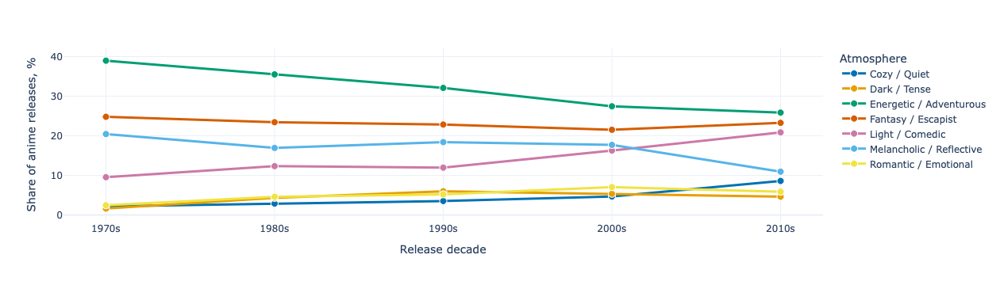

In [123]:
fig_q5.update_traces(
    line={
        "width": 3
    },
    marker={
        "size": 9,
        "line": {
            "width": 1,
            "color": "white"
        }
    },
    hovertemplate=(
        "<b>%{fullData.name}</b><br>"
        "Decade: %{x}<br>"
        "Share of releases: %{y:.1f}%<br>"
        "Anime titles: %{customdata[0]:,.0f}<br>"
        "All titles in decade: %{customdata[1]:,.0f}"
        "<extra></extra>"
    )
)

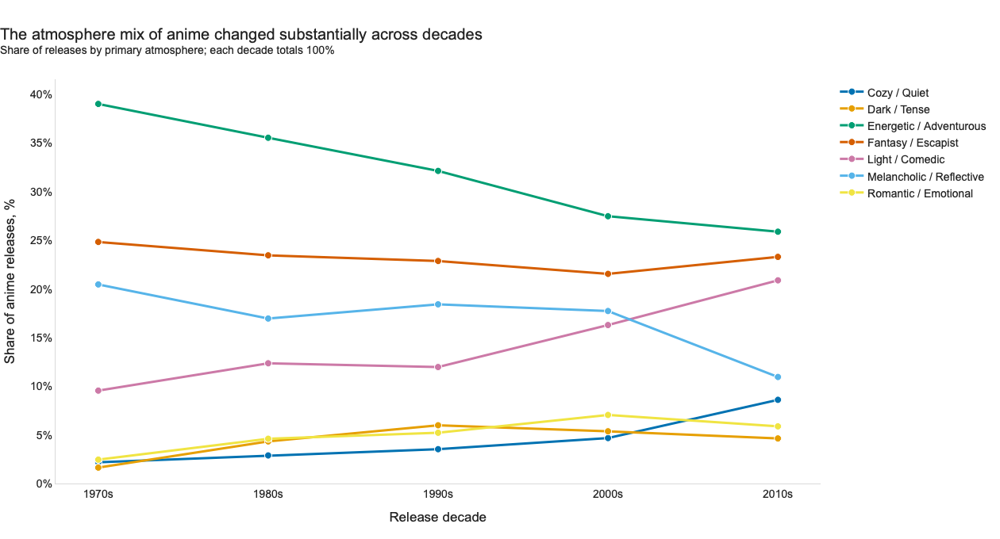

In [124]:
fig_q5 = apply_chart_style(
    fig_q5,
    title=(
        "The atmosphere mix of anime changed "
        "substantially across decades"
    ),
    subtitle=(
        "Share of releases by primary atmosphere; "
        "each decade totals 100%"
    )
)

fig_q5.update_layout(
    height=680,
    legend={
        "orientation": "v",
        "yanchor": "top",
        "y": 1,
        "xanchor": "left",
        "x": 1.02
    }
)

fig_q5.update_yaxes(
    ticksuffix="%",
    rangemode="tozero"
)

fig_q5.show()

In [125]:
fig_q5_stack = px.bar(
    question_5_summary,
    x="decade",
    y="atmosphere_share_pct",
    color="atmosphere",
    category_orders={
        "decade": decade_order
    },
    color_discrete_sequence=CVD_COLORS,
    labels={
        "decade": "Release decade",
        "atmosphere_share_pct": (
            "Share of releases, %"
        ),
        "atmosphere": "Atmosphere"
    }
)

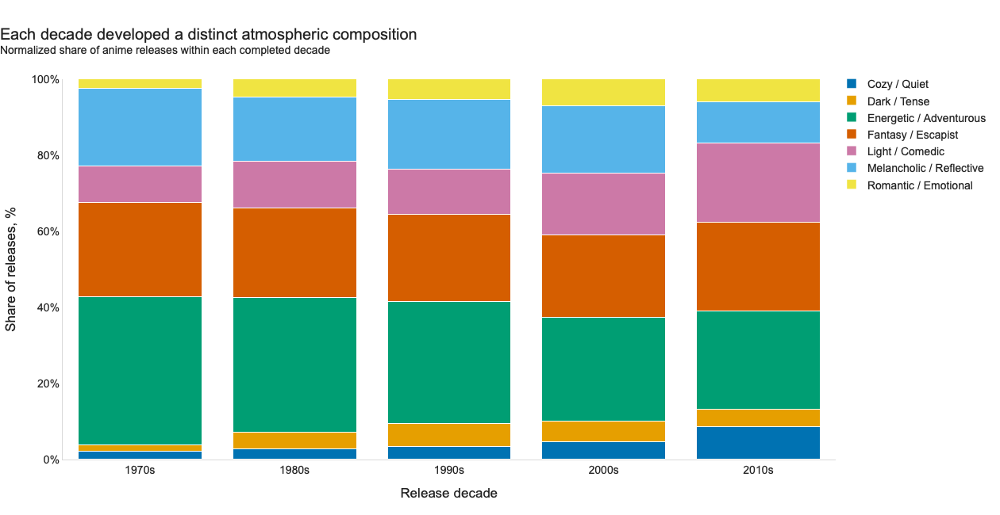

In [126]:
fig_q5_stack.update_layout(
    barmode="stack"
)

fig_q5_stack.update_traces(
    hovertemplate=(
        "<b>%{fullData.name}</b><br>"
        "Decade: %{x}<br>"
        "Share: %{y:.1f}%"
        "<extra></extra>"
    )
)

fig_q5_stack = apply_chart_style(
    fig_q5_stack,
    title=(
        "Each decade developed a distinct "
        "atmospheric composition"
    ),
    subtitle=(
        "Normalized share of anime releases "
        "within each completed decade"
    )
)

fig_q5_stack.update_layout(
    height=650,
    legend={
        "orientation": "v",
        "yanchor": "bottom",
        "y": 0.69,
        "xanchor": "left",
        "x": 1
    }
)

fig_q5_stack.update_yaxes(
    range=[0, 100],
    ticksuffix="%"
)

fig_q5_stack.show()

In [127]:
question_5_pivot = (
    question_5_summary
    .pivot(
        index="atmosphere",
        columns="decade",
        values="atmosphere_share_pct"
    )
    .reset_index()
)

question_5_pivot

decade,atmosphere,1970s,1980s,1990s,2000s,2010s
0,Cozy / Quiet,2.179837,2.882883,3.525805,4.666667,8.591496
1,Dark / Tense,1.634877,4.324324,5.978539,5.360000,4.628120
2,Energetic / Adventurous,38.964578,35.495495,32.089934,27.440000,25.849743
3,Fantasy / Escapist,24.795640,23.423423,22.841083,21.520000,23.266023
4,Light / Comedic,9.536785,12.342342,11.957077,16.266667,20.857895
5,Melancholic / Reflective,20.435967,16.936937,18.395503,17.706667,10.936912
6,Romantic / Emotional,2.452316,4.594595,5.212059,7.040000,5.869811


In [128]:
question_5_pivot[
    "share_change_1970s_to_2010s"
] = (
    question_5_pivot["2010s"]
    - question_5_pivot["1970s"]
)

question_5_change = (
    question_5_pivot[
        [
            "atmosphere",
            "1970s",
            "2010s",
            "share_change_1970s_to_2010s"
        ]
    ]
    .sort_values(
        "share_change_1970s_to_2010s",
        ascending=False
    )
)

question_5_change

decade,atmosphere,1970s,2010s,share_change_1970s_to_2010s
4,Light / Comedic,9.536785,20.857895,11.321111
0,Cozy / Quiet,2.179837,8.591496,6.411660
6,Romantic / Emotional,2.452316,5.869811,3.417495
1,Dark / Tense,1.634877,4.628120,2.993243
3,Fantasy / Escapist,24.795640,23.266023,-1.529617
5,Melancholic / Reflective,20.435967,10.936912,-9.499055
2,Energetic / Adventurous,38.964578,25.849743,-13.114835


In [129]:
question_5_change["change_label"] = (
    question_5_change[
        "share_change_1970s_to_2010s"
    ]
    .map(
        lambda value: f"{value:+.1f} pp"
    )
)

In [130]:
fig_q5_change = px.bar(
    question_5_change,
    x="share_change_1970s_to_2010s",
    y="atmosphere",
    orientation="h",
    text="change_label",
    color="share_change_1970s_to_2010s",
    color_continuous_scale=[
        [0.0, "#D55E00"],
        [0.5, "#B8B8B8"],
        [1.0, "#0072B2"]
    ],
    color_continuous_midpoint=0,
    labels={
        "share_change_1970s_to_2010s": (
            "Change in release share, percentage points"
        ),
        "atmosphere": ""
    }
)

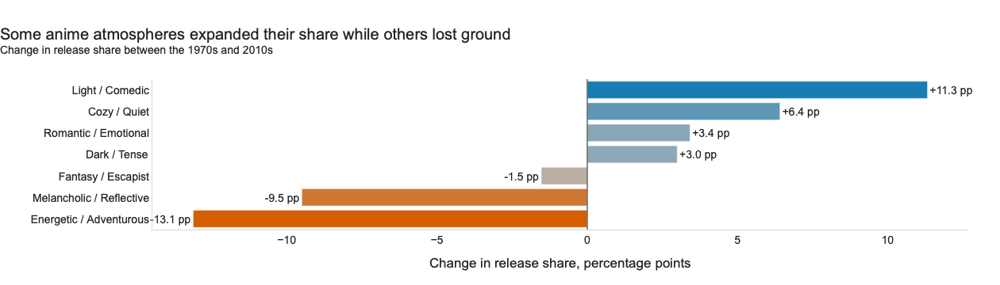

In [131]:
fig_q5_change.update_yaxes(
    categoryorder="total ascending"
)

fig_q5_change.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Change: %{x:+.1f} percentage points"
        "<extra></extra>"
    )
)

fig_q5_change.add_vline(
    x=0,
    line_width=1.5,
    line_color="#666666"
)

fig_q5_change = apply_chart_style(
    fig_q5_change,
    title=(
        "Some anime atmospheres expanded their share "
        "while others lost ground"
    ),
    subtitle=(
        "Change in release share between "
        "the 1970s and 2010s"
    )
)

fig_q5_change.update_layout(
    coloraxis_showscale=False
)

fig_q5_change.show()

In [132]:
largest_growth_row = (
    question_5_change.iloc[0]
)

largest_decline_row = (
    question_5_change.iloc[-1]
)

print(
    "Largest increase in release share:",
    largest_growth_row["atmosphere"],
    (
        f"({largest_growth_row[
            'share_change_1970s_to_2010s'
        ]:+.1f} pp)"
    )
)

print(
    "Largest decline in release share:",
    largest_decline_row["atmosphere"],
    (
        f"({largest_decline_row[
            'share_change_1970s_to_2010s'
        ]:+.1f} pp)"
    )
)

Largest increase in release share: Light / Comedic (+11.3 pp)
Largest decline in release share: Energetic / Adventurous (-13.1 pp)


In [133]:
decade_leaders = (
    question_5_summary
    .sort_values(
        [
            "decade",
            "atmosphere_share_pct"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby("decade")
    .first()
    .reset_index()
)

decade_leaders[
    [
        "decade",
        "atmosphere",
        "atmosphere_share_pct",
        "anime_count"
    ]
]

,decade,atmosphere,atmosphere_share_pct,anime_count
0,1970s,Energetic / Adventurous,38.964578,143
1,1980s,Energetic / Adventurous,35.495495,394
2,1990s,Energetic / Adventurous,32.089934,628
3,2000s,Energetic / Adventurous,27.440000,1029
4,2010s,Energetic / Adventurous,25.849743,2061


### Current 2020s snapshot

The 2020s are excluded from the main decade comparison because the decade is incomplete. However, the available years can still be examined as a provisional snapshot rather than a completed historical period.

In [134]:
question_5_2020s = df.dropna(
    subset=[
        "release_year",
        "atmosphere"
    ]
).copy()

question_5_2020s = question_5_2020s[
    (question_5_2020s["release_year"].between(2020, 2025))
    & (question_5_2020s["atmosphere"] != "Other")
].copy()

In [135]:
snapshot_2020s = (
    question_5_2020s
    .groupby("atmosphere")
    .agg(
        anime_count=(
            "mal_id",
            "count"
        )
    )
    .reset_index()
)

snapshot_2020s[
    "share_pct"
] = (
    snapshot_2020s["anime_count"]
    / snapshot_2020s["anime_count"].sum()
    * 100
)

snapshot_2020s = snapshot_2020s.sort_values(
    "share_pct",
    ascending=False
)

snapshot_2020s

,atmosphere,anime_count,share_pct
2,Energetic / Adventurous,1586,31.739043
3,Fantasy / Escapist,1194,23.894337
5,Melancholic / Reflective,613,12.267360
4,Light / Comedic,570,11.406844
0,Cozy / Quiet,465,9.305583
6,Romantic / Emotional,311,6.223734
1,Dark / Tense,258,5.163098


### Key insight

The composition of anime atmospheres changed considerably between the 1970s and the 2010s.

**Light / Comedic** recorded the largest increase in release share, rising by approximately **+11.3 pp percentage points**.

In contrast, **Energetic / Adventurous** experienced the largest decline, falling by approximately **-13.1 pp percentage points**.

The leading atmosphere also changed across decades, indicating that the anime industry did not simply expand in volume: its thematic and emotional composition shifted as well.

These changes describe production patterns rather than direct audience demand. A larger release share means that an atmosphere became more common among released titles, but it does not necessarily mean that it became more popular with viewers.

### Limitations

- Atmosphere categories are generated through rule-based genre and theme matching and therefore reflect analytical interpretation.
- One anime is assigned only one primary atmosphere, even when several categories may apply.
- The 1970s may contain fewer titles than later decades, making early-period estimates less stable.
- MyAnimeList coverage may be more complete for recent anime than for older releases.
- The analysis measures the share of released titles, not audience popularity or commercial performance.
- Different seasons and sequels are counted as separate anime entries.
- The 2020s are excluded from the main comparison because the decade is incomplete.
- Changes in release share do not establish why industry production patterns changed.

## 13. Analytical Question 6

### Which anime atmospheres gained or lost relative audience popularity from the 2000s to the current 2020–2025 period?

Raw member counts are not directly comparable across release periods. Older anime have had more time to accumulate MyAnimeList members, while recent titles have had less exposure time.

To reduce this age-related bias, every anime is assigned a relative popularity percentile within its own release period.

A percentile close to 100 means that the anime has a larger audience than most other titles released during the same period. A percentile close to 0 indicates relatively low popularity within that period.

The analysis compares three periods:

- 2000–2009
- 2010–2019
- 2020–2025

The final period is treated as a current snapshot rather than a completed decade.

In [136]:
question_6_df = df.dropna(
    subset=[
        "release_year",
        "members",
        "atmosphere"
    ]
).copy()

In [137]:
question_6_df = question_6_df[
    (question_6_df["release_year"].between(2000, 2025))
    & (question_6_df["members"] > 0)
    & (question_6_df["atmosphere"] != "Other")
].copy()

print(
    f"Anime included in Question 6: "
    f"{len(question_6_df):,}"
)

Anime included in Question 6: 16,719


In [138]:
def assign_release_period(year):
    if 2000 <= year <= 2009:
        return "2000s"

    if 2010 <= year <= 2019:
        return "2010s"

    if 2020 <= year <= 2025:
        return "2020–2025"

    return pd.NA

In [139]:
question_6_df["release_period"] = (
    question_6_df["release_year"]
    .apply(assign_release_period)
)

In [140]:
question_6_df[
    [
        "title",
        "release_year",
        "release_period",
        "members",
        "atmosphere"
    ]
].head(10)

,title,release_year,release_period,members,atmosphere
1,Cowboy Bebop: Tengoku no Tobira,2001.0,2000s,411149,Fantasy / Escapist
3,Witch Hunter Robin,2002.0,2000s,129274,Melancholic / Reflective
4,Bouken Ou Beet,2004.0,2000s,16881,Energetic / Adventurous
5,Eyeshield 21,2005.0,2000s,195854,Energetic / Adventurous
6,Hachimitsu to Clover,2005.0,2000s,285204,Melancholic / Reflective
7,Hungry Heart: Wild Striker,2002.0,2000s,26976,Energetic / Adventurous
8,Initial D Fourth Stage,2004.0,2000s,214740,Energetic / Adventurous
9,Monster,2004.0,2000s,1323745,Melancholic / Reflective
10,Naruto,2002.0,2000s,3109995,Energetic / Adventurous
12,Tennis no Oujisama,2001.0,2000s,197616,Energetic / Adventurous


In [141]:
question_6_period_counts = (
    question_6_df
    .groupby("release_period")
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        median_members=(
            "members",
            "median"
        )
    )
    .reset_index()
)

question_6_period_counts

,release_period,anime_count,median_members
0,2000s,3749,4741.0
1,2010s,7973,2568.0
2,2020–2025,4997,1456.0


In [142]:
question_6_df[
    "popularity_percentile"
] = (
    question_6_df
    .groupby("release_period")[
        "members"
    ]
    .rank(
        method="average",
        pct=True,
        ascending=True
    )
    * 100
)

In [143]:
question_6_df[
    [
        "title",
        "release_period",
        "members",
        "popularity_percentile"
    ]
].sort_values(
    [
        "release_period",
        "popularity_percentile"
    ],
    ascending=[
        True,
        False
    ]
).head(20)

,title,release_period,members,popularity_percentile
1393,Death Note,2000s,4287273,100.000000
3959,Fullmetal Alchemist: Brotherhood,2000s,3673510,99.973326
10,Naruto,2000s,3109995,99.946652
1574,Naruto: Shippuuden,2000s,2740713,99.919979
1431,Code Geass: Hangyaku no Lelouch,2000s,2465957,99.893305
3552,Toradora!,2000s,2361593,99.866631
245,Bleach,2000s,2200542,99.839957
176,Sen to Chihiro no Kamikakushi,2000s,2024733,99.813284
2646,Code Geass: Hangyaku no Lelouch R2,2000s,1950783,99.786610
4690,Fairy Tail,2000s,1843184,99.759936


In [144]:
question_6_df[
    "popularity_percentile"
].describe()

count    16719.000000
mean        50.008972
std         28.868364
min          0.018813
25%         25.011570
50%         50.010006
75%         75.005836
max        100.000000
Name: popularity_percentile, dtype: float64

In [145]:
question_6_summary = (
    question_6_df
    .groupby(
        [
            "release_period",
            "atmosphere"
        ]
    )
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        median_popularity_percentile=(
            "popularity_percentile",
            "median"
        ),
        median_members=(
            "members",
            "median"
        ),
        median_score=(
            "score",
            "median"
        )
    )
    .reset_index()
)

question_6_summary.head(15)

,release_period,atmosphere,anime_count,median_popularity_percentile,median_members,median_score
0,2000s,Cozy / Quiet,175,36.996532,1694.0,6.730
1,2000s,Dark / Tense,201,68.818352,16823.0,6.965
2,2000s,Energetic / Adventurous,1029,51.000267,5105.0,6.710
3,2000s,Fantasy / Escapist,806,44.011736,3174.5,6.460
4,2000s,Light / Comedic,610,32.308616,1090.5,6.300
5,2000s,Melancholic / Reflective,664,61.789811,10538.0,6.880
6,2000s,Romantic / Emotional,264,70.965591,20119.5,6.690
7,2010s,Cozy / Quiet,685,49.203562,2334.0,6.405
8,2010s,Dark / Tense,369,68.543835,17889.0,6.690
9,2010s,Energetic / Adventurous,2061,51.605418,3107.0,6.650


In [146]:
question_6_summary.sort_values(
    "anime_count"
).head(15)

,release_period,atmosphere,anime_count,median_popularity_percentile,median_members,median_score
0,2000s,Cozy / Quiet,175,36.996532,1694.0,6.730
1,2000s,Dark / Tense,201,68.818352,16823.0,6.965
15,2020–2025,Dark / Tense,258,63.808285,5376.5,6.685
6,2000s,Romantic / Emotional,264,70.965591,20119.5,6.690
20,2020–2025,Romantic / Emotional,311,69.601761,11487.0,6.900
8,2010s,Dark / Tense,369,68.543835,17889.0,6.690
14,2020–2025,Cozy / Quiet,465,39.573744,709.0,6.570
13,2010s,Romantic / Emotional,468,78.803462,49771.0,6.780
18,2020–2025,Light / Comedic,570,38.147889,643.0,6.290
4,2000s,Light / Comedic,610,32.308616,1090.5,6.300


In [147]:
period_order = [
    "2000s",
    "2010s",
    "2020–2025"
]

In [148]:
fig_q6 = px.line(
    question_6_summary,
    x="release_period",
    y="median_popularity_percentile",
    color="atmosphere",
    markers=True,
    category_orders={
        "release_period": period_order
    },
    color_discrete_sequence=CVD_COLORS,
    hover_data={
        "anime_count": ":,",
        "median_members": ":,.0f",
        "median_score": ":.2f",
        "median_popularity_percentile": ":.1f"
    },
    labels={
        "release_period": "Release period",
        "median_popularity_percentile": (
            "Median relative popularity percentile"
        ),
        "atmosphere": "Atmosphere",
        "anime_count": "Anime titles",
        "median_members": "Median members",
        "median_score": "Median score"
    }
)

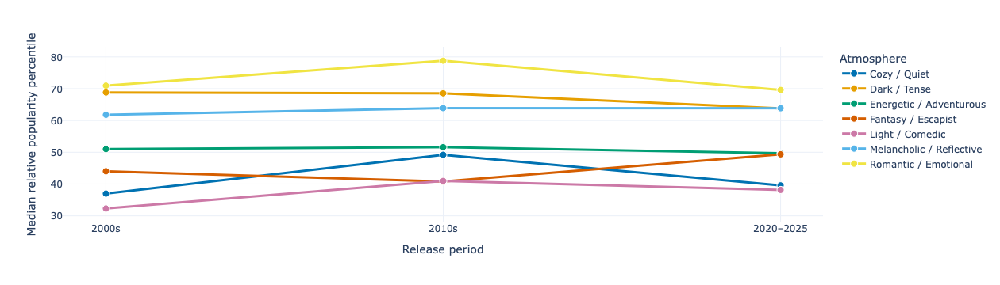

In [149]:
fig_q6.update_traces(
    line={
        "width": 3
    },
    marker={
        "size": 9,
        "line": {
            "width": 1,
            "color": "white"
        }
    },
    hovertemplate=(
        "<b>%{fullData.name}</b><br>"
        "Period: %{x}<br>"
        "Median popularity percentile: %{y:.1f}<br>"
        "Anime titles: %{customdata[0]:,.0f}<br>"
        "Median members: %{customdata[1]:,.0f}<br>"
        "Median score: %{customdata[2]:.2f}"
        "<extra></extra>"
    )
)

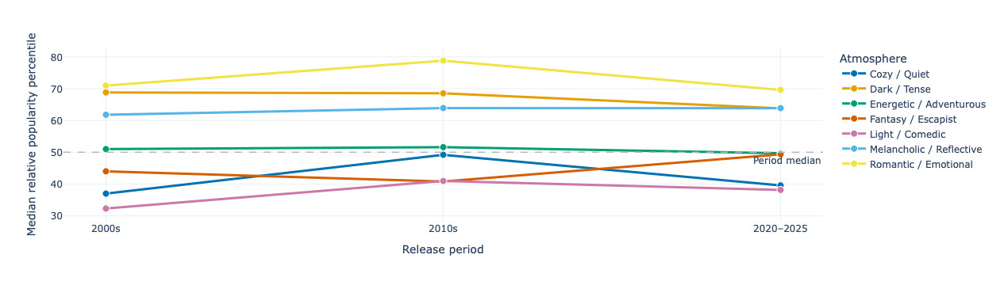

In [150]:
fig_q6.add_hline(
    y=50,
    line_width=1.5,
    line_dash="dash",
    line_color=CONTEXT_COLOR,
    annotation_text="Period median",
    annotation_position="bottom right"
)

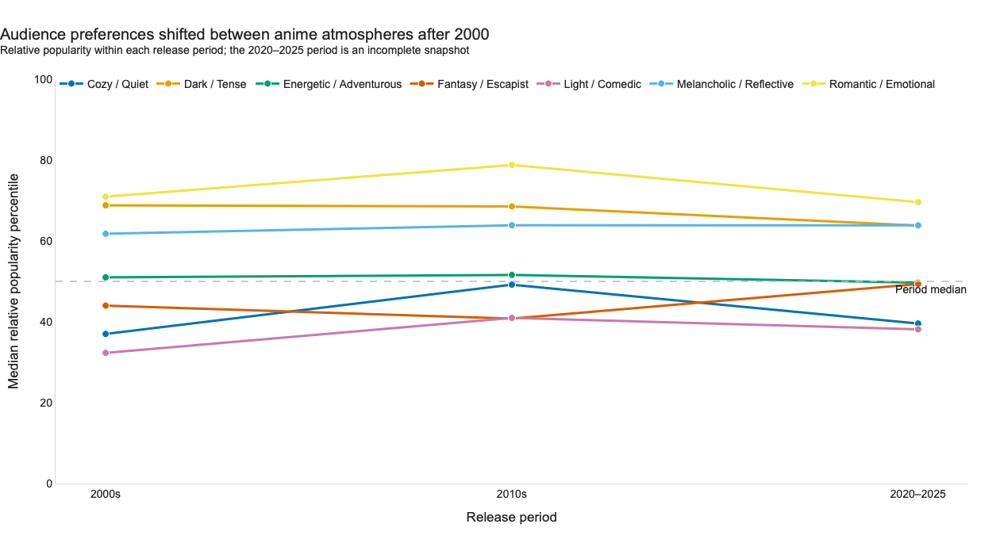

In [151]:
fig_q6 = apply_chart_style(
    fig_q6,
    title=(
        "Audience preferences shifted between "
        "anime atmospheres after 2000"
    ),
    subtitle=(
        "Relative popularity within each release period; "
        "the 2020–2025 period is an incomplete snapshot"
    )
)

fig_q6.update_layout(
    height=680,
    legend={
        "orientation": "h",
        "yanchor": "top",
        "y": 1.02,
        "xanchor": "left",
        "x": 0
    }
)

fig_q6.update_yaxes(
    range=[0, 100],
    ticksuffix=""
)

fig_q6.show()

In [152]:
question_6_pivot = (
    question_6_summary
    .pivot(
        index="atmosphere",
        columns="release_period",
        values="median_popularity_percentile"
    )
    .reset_index()
)

question_6_pivot

release_period,atmosphere,2000s,2010s,2020–2025
0,Cozy / Quiet,36.996532,49.203562,39.573744
1,Dark / Tense,68.818352,68.543835,63.808285
2,Energetic / Adventurous,51.000267,51.605418,49.689814
3,Fantasy / Escapist,44.011736,40.793930,49.354613
4,Light / Comedic,32.308616,40.969522,38.147889
5,Melancholic / Reflective,61.789811,63.890631,63.858315
6,Romantic / Emotional,70.965591,78.803462,69.601761


In [153]:
question_6_pivot[
    "popularity_change"
] = (
    question_6_pivot["2020–2025"]
    - question_6_pivot["2000s"]
)

question_6_change = (
    question_6_pivot[
        [
            "atmosphere",
            "2000s",
            "2010s",
            "2020–2025",
            "popularity_change"
        ]
    ]
    .dropna(
        subset=[
            "2000s",
            "2020–2025"
        ]
    )
    .sort_values(
        "popularity_change",
        ascending=False
    )
)

question_6_change

release_period,atmosphere,2000s,2010s,2020–2025,popularity_change
4,Light / Comedic,32.308616,40.969522,38.147889,5.839273
3,Fantasy / Escapist,44.011736,40.793930,49.354613,5.342876
0,Cozy / Quiet,36.996532,49.203562,39.573744,2.577212
5,Melancholic / Reflective,61.789811,63.890631,63.858315,2.068504
2,Energetic / Adventurous,51.000267,51.605418,49.689814,-1.310453
6,Romantic / Emotional,70.965591,78.803462,69.601761,-1.363830
1,Dark / Tense,68.818352,68.543835,63.808285,-5.010067


In [154]:
question_6_change["change_label"] = (
    question_6_change[
        "popularity_change"
    ]
    .map(
        lambda value: f"{value:+.1f}"
    )
)

In [155]:
question_6_change["direction"] = np.where(
    question_6_change[
        "popularity_change"
    ] >= 0,
    "Gained relative popularity",
    "Lost relative popularity"
)

In [156]:
fig_q6_change = px.bar(
    question_6_change,
    x="popularity_change",
    y="atmosphere",
    orientation="h",
    text="change_label",
    color="direction",
    color_discrete_map={
        "Gained relative popularity": "#0072B2",
        "Lost relative popularity": "#D55E00"
    },
    labels={
        "popularity_change": (
            "Change in median popularity percentile"
        ),
        "atmosphere": "",
        "direction": ""
    }
)

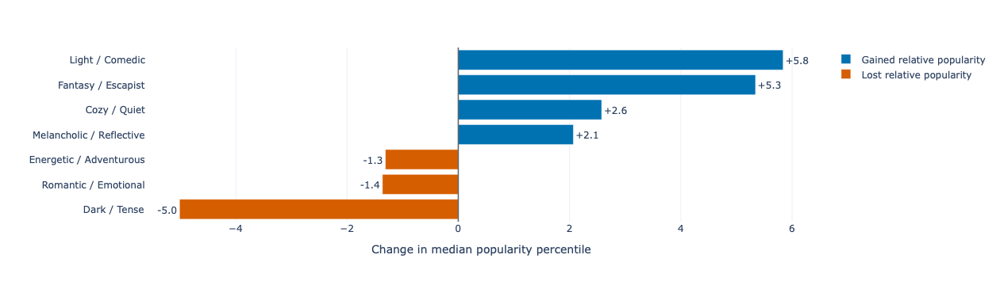

In [157]:
fig_q6_change.update_yaxes(
    categoryorder="total ascending"
)

fig_q6_change.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Change in relative popularity: %{x:+.1f} points"
        "<extra></extra>"
    )
)

fig_q6_change.add_vline(
    x=0,
    line_width=1.5,
    line_color="#666666"
)

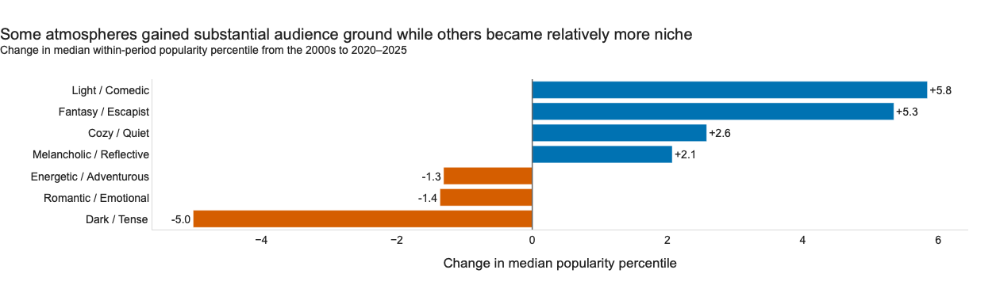

In [158]:
fig_q6_change = apply_chart_style(
    fig_q6_change,
    title=(
        "Some atmospheres gained substantial audience ground "
        "while others became relatively more niche"
    ),
    subtitle=(
        "Change in median within-period popularity percentile "
        "from the 2000s to 2020–2025"
    )
)

fig_q6_change.update_layout(
    showlegend=False
)

fig_q6_change.show()

In [159]:
largest_gain_row = question_6_change.iloc[0]
largest_loss_row = question_6_change.iloc[-1]

largest_gain_value = (
    largest_gain_row["popularity_change"]
)

largest_loss_value = (
    largest_loss_row["popularity_change"]
)

print(
    "Largest relative popularity gain:",
    largest_gain_row["atmosphere"],
    f"({largest_gain_value:+.1f} points)"
)

print(
    "Largest relative popularity loss:",
    largest_loss_row["atmosphere"],
    f"({largest_loss_value:+.1f} points)"
)

Largest relative popularity gain: Light / Comedic (+5.8 points)
Largest relative popularity loss: Dark / Tense (-5.0 points)


In [160]:
question_6_period_leaders = (
    question_6_summary
    .sort_values(
        [
            "release_period",
            "median_popularity_percentile"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby("release_period")
    .first()
    .reset_index()
)

question_6_period_leaders[
    [
        "release_period",
        "atmosphere",
        "median_popularity_percentile",
        "anime_count",
        "median_members"
    ]
]

,release_period,atmosphere,median_popularity_percentile,anime_count,median_members
0,2000s,Romantic / Emotional,70.965591,264,20119.5
1,2010s,Romantic / Emotional,78.803462,468,49771.0
2,2020–2025,Romantic / Emotional,69.601761,311,11487.0


In [161]:
current_period_leader = (
    question_6_summary[
        question_6_summary[
            "release_period"
        ] == "2020–2025"
    ]
    .sort_values(
        "median_popularity_percentile",
        ascending=False
    )
    .iloc[0]
)

print(
    "Current 2020–2025 leader:",
    current_period_leader["atmosphere"],
    (
        f"({current_period_leader[
            'median_popularity_percentile'
        ]:.1f} percentile)"
    )
)

Current 2020–2025 leader: Romantic / Emotional (69.6 percentile)


In [162]:
question_6_raw_members = (
    question_6_summary[
        [
            "release_period",
            "atmosphere",
            "median_members",
            "median_popularity_percentile",
            "anime_count"
        ]
    ]
    .sort_values(
        [
            "release_period",
            "median_members"
        ],
        ascending=[
            True,
            False
        ]
    )
)

question_6_raw_members.head(20)

,release_period,atmosphere,median_members,median_popularity_percentile,anime_count
6,2000s,Romantic / Emotional,20119.5,70.965591,264
1,2000s,Dark / Tense,16823.0,68.818352,201
5,2000s,Melancholic / Reflective,10538.0,61.789811,664
2,2000s,Energetic / Adventurous,5105.0,51.000267,1029
3,2000s,Fantasy / Escapist,3174.5,44.011736,806
0,2000s,Cozy / Quiet,1694.0,36.996532,175
4,2000s,Light / Comedic,1090.5,32.308616,610
13,2010s,Romantic / Emotional,49771.0,78.803462,468
8,2010s,Dark / Tense,17889.0,68.543835,369
12,2010s,Melancholic / Reflective,10702.0,63.890631,872


### Key insight

Relative audience preferences changed between the 2000s and the current 2020–2025 period.

**Light / Comedic** recorded the largest improvement, increasing its median within-period popularity by approximately **+ 5.8 percentile points**.

In contrast, **Dark / Tense** experienced the largest relative decline, changing by approximately **-5.0 percentile points**.

The leading atmosphere in the current 2020–2025 snapshot is **Romantic / Emotional**, with a median popularity percentile of approximately **69.6 percentile**.

These results suggest that changes in production share and changes in audience preference should be treated separately. An atmosphere may become more common without becoming relatively more popular, while another may attract stronger audiences despite representing a smaller share of releases.

### Limitations

- Relative popularity percentiles reduce but do not completely remove the age advantage of older anime.
- The 2020–2025 period is incomplete and recent titles may continue accumulating members.
- `members` represents MyAnimeList account activity rather than confirmed completed viewing.
- MyAnimeList users are not necessarily representative of the complete global anime audience.
- Percentiles describe relative position within each period and do not show absolute differences in audience size.
- Atmosphere categories were constructed using rule-based genre and theme matching.
- Each anime receives one primary atmosphere even when several categories may apply.
- Sequels and separate seasons are treated as independent anime entries.
- The results show associations over time but do not explain the causes of changing audience preferences.

## 14. Analytical Question 7

### Which highly rated anime remain relatively undiscovered, and which atmospheres produce the most hidden gems?

Some anime receive strong user evaluations without attracting a correspondingly large audience.

To identify these titles, a hidden gem is defined as an anime that:

- has a user score above the 75th percentile;
- has an audience size below the median;
- has received at least 1,000 user ratings.

The analysis first identifies individual hidden gems and then compares how frequently they occur across atmosphere categories.

In [163]:
question_7_df = df.dropna(
    subset=[
        "title",
        "score",
        "scored_by",
        "members",
        "atmosphere"
    ]
).copy()

In [164]:
question_7_df = question_7_df[
    (question_7_df["scored_by"] >= 1000)
    & (question_7_df["members"] > 0)
    & (question_7_df["atmosphere"] != "Other")
].copy()

print(
    f"Anime included in Question 7: "
    f"{len(question_7_df):,}"
)

Anime included in Question 7: 9,681


In [165]:
high_score_threshold = (
    question_7_df["score"]
    .quantile(0.75)
)

low_audience_threshold = (
    question_7_df["members"]
    .median()
)

print(
    "High-score threshold:",
    f"{high_score_threshold:.2f}"
)

print(
    "Low-audience threshold:",
    f"{low_audience_threshold:,.0f} members"
)

High-score threshold: 7.44
Low-audience threshold: 25,417 members


In [166]:
question_7_df["is_hidden_gem"] = (
    (question_7_df["score"] > high_score_threshold)
    & (
        question_7_df["members"]
        < low_audience_threshold
    )
)

In [167]:
hidden_gems = question_7_df[
    question_7_df["is_hidden_gem"]
].copy()

print(
    f"Hidden gems identified: "
    f"{len(hidden_gems):,}"
)

print(
    "Share of analysed anime:",
    f"{len(hidden_gems) / len(question_7_df) * 100:.1f}%"
)

Hidden gems identified: 427
Share of analysed anime: 4.4%


In [168]:
hidden_gems[
    [
        "title",
        "score",
        "scored_by",
        "members",
        "favorites",
        "atmosphere",
        "release_year"
    ]
].sort_values(
    [
        "score",
        "members"
    ],
    ascending=[
        False,
        True
    ]
).head(20)

,title,score,scored_by,members,favorites,atmosphere,release_year
28760,Luo Xiaohei Zhanji 2,8.62,2432.0,10094,77,Melancholic / Reflective,2025.0
21642,Chiikawa,8.61,6254.0,20337,698,Cozy / Quiet,2022.0
24362,Alien Stage,8.58,7413.0,16450,817,Melancholic / Reflective,2022.0
27862,Fanren Xiu Xian Zhuan 4th Season,8.54,1206.0,2949,48,Energetic / Adventurous,2025.0
24735,Xian Ni,8.50,2918.0,11055,353,Energetic / Adventurous,2023.0
28175,Tian Guan Cifu Short Films,8.50,2475.0,11443,174,Energetic / Adventurous,2025.0
27849,Nezha Zhi Mo Tong Nao Hai,8.46,5256.0,11123,66,Melancholic / Reflective,2025.0
21353,Doupo Cangqiong: San Nian Zhi Yue,8.44,5148.0,11643,206,Energetic / Adventurous,2021.0
21960,Doupo Cangqiong: Nian Fan,8.38,4231.0,12326,403,Energetic / Adventurous,2022.0
3870,Ramayana: The Legend of Prince Rama,8.38,7243.0,15396,229,Energetic / Adventurous,1993.0


### Hidden gem score

To rank hidden gems, two relative measures are combined:

- score percentile: higher values indicate stronger user ratings;
- obscurity percentile: higher values indicate a smaller audience.

The hidden gem score is the average of these two percentiles. This project-specific measure rewards titles that are both highly rated and relatively undiscovered.

In [169]:
question_7_df["score_percentile"] = (
    question_7_df["score"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

question_7_df["audience_percentile"] = (
    question_7_df["members"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

In [170]:
question_7_df["obscurity_percentile"] = (
    100
    - question_7_df["audience_percentile"]
)

In [171]:
question_7_df["hidden_gem_score"] = (
    question_7_df["score_percentile"]
    + question_7_df["obscurity_percentile"]
) / 2

In [172]:
hidden_gems = question_7_df[
    question_7_df["is_hidden_gem"]
].copy()

hidden_gems = hidden_gems.sort_values(
    "hidden_gem_score",
    ascending=False
)

hidden_gems[
    [
        "title",
        "score",
        "members",
        "score_percentile",
        "obscurity_percentile",
        "hidden_gem_score",
        "atmosphere"
    ]
].head(20)

,title,score,members,score_percentile,obscurity_percentile,hidden_gem_score,atmosphere
27862,Fanren Xiu Xian Zhuan 4th Season,8.54,2949,98.533209,96.777192,97.655201,Energetic / Adventurous
27846,Wu Dong Qian Kun 5th Season,7.91,2398,90.729264,99.003202,94.866233,Energetic / Adventurous
25690,Shinkiro,7.81,1905,88.363805,99.793410,94.078608,Cozy / Quiet
25622,Fanren Xiu Xian Zhuan: Xinghai Feichi,8.35,4009,97.133561,90.811900,93.972730,Energetic / Adventurous
26578,Yuanshen Tiwate Pian: Mu Jian PV - Dong Ye Yu Xi,7.79,2435,87.888648,98.863754,93.376201,Fantasy / Escapist
25713,Wu Dong Qian Kun 4th Season,7.88,3028,90.021692,96.405330,93.213511,Energetic / Adventurous
26557,Zhu Xian 2nd Season,7.94,3407,91.395517,94.168991,92.782254,Energetic / Adventurous
25007,Yi Nian Yong Heng 3rd Season,8.23,4223,95.816548,89.520711,92.668629,Energetic / Adventurous
26881,Benghuai: Xing Qiong Tiedao - Gelamo de Yujin,7.92,3404,90.972007,94.210309,92.591158,Fantasy / Escapist
22364,Xingchen Bian 5th Season,7.71,2780,85.703956,97.551906,91.627931,Energetic / Adventurous


In [173]:
top_hidden_gems = (
    hidden_gems
    .head(15)
    .sort_values(
        "hidden_gem_score",
        ascending=True
    )
    .copy()
)

top_hidden_gems[
    "hidden_gem_label"
] = (
    top_hidden_gems["hidden_gem_score"]
    .map(lambda value: f"{value:.1f}")
)

In [174]:
fig_q7 = px.bar(
    top_hidden_gems,
    x="hidden_gem_score",
    y="title",
    orientation="h",
    color="atmosphere",
    text="hidden_gem_label",
    color_discrete_sequence=CVD_COLORS,
    hover_data={
        "score": ":.2f",
        "members": ":,",
        "scored_by": ":,",
        "score_percentile": ":.1f",
        "obscurity_percentile": ":.1f",
        "hidden_gem_score": ":.1f",
        "release_year": ":.0f"
    },
    labels={
        "hidden_gem_score": "Hidden gem score",
        "title": "",
        "atmosphere": "Atmosphere",
        "score": "User score",
        "members": "Members",
        "scored_by": "Users who rated",
        "score_percentile": "Score percentile",
        "obscurity_percentile": "Obscurity percentile",
        "release_year": "Release year"
    }
)

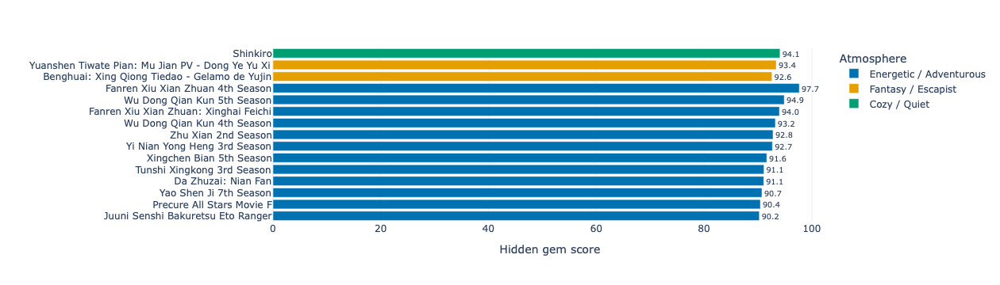

In [175]:
fig_q7.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Hidden gem score: %{x:.1f}<br>"
        "Atmosphere: %{fullData.name}<br>"
        "User score: %{customdata[0]:.2f}<br>"
        "Members: %{customdata[1]:,.0f}<br>"
        "Users who rated: %{customdata[2]:,.0f}<br>"
        "Score percentile: %{customdata[3]:.1f}<br>"
        "Obscurity percentile: %{customdata[4]:.1f}"
        "<extra></extra>"
    )
)

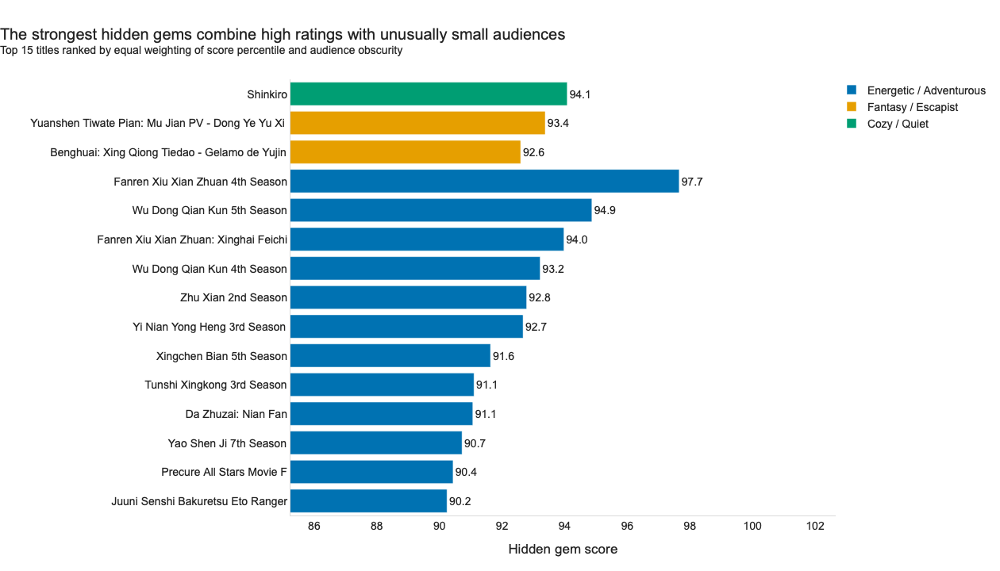

In [176]:
fig_q7 = apply_chart_style(
    fig_q7,
    title=(
        "The strongest hidden gems combine "
        "high ratings with unusually small audiences"
    ),
    subtitle=(
        "Top 15 titles ranked by equal weighting of "
        "score percentile and audience obscurity"
    )
)

fig_q7.update_layout(
    height=720,
    legend={
        "orientation": "v",
        "yanchor": "bottom",
        "y": 0.87,
        "xanchor": "left",
        "x": 1
    }
)

fig_q7.update_xaxes(
    range=[
        max(
            0,
            top_hidden_gems[
                "hidden_gem_score"
            ].min() - 5
        ),
        top_hidden_gems[
            "hidden_gem_score"
        ].max() + 5
    ]
)

fig_q7.show()

In [177]:
hidden_gem_counts = (
    hidden_gems
    .groupby("atmosphere")
    .agg(
        hidden_gem_count=(
            "mal_id",
            "count"
        )
    )
    .reset_index()
)

In [178]:
atmosphere_totals_q7 = (
    question_7_df
    .groupby("atmosphere")
    .agg(
        total_anime=(
            "mal_id",
            "count"
        )
    )
    .reset_index()
)

In [179]:
hidden_gem_atmosphere_summary = (
    atmosphere_totals_q7
    .merge(
        hidden_gem_counts,
        on="atmosphere",
        how="left"
    )
)

hidden_gem_atmosphere_summary[
    "hidden_gem_count"
] = (
    hidden_gem_atmosphere_summary[
        "hidden_gem_count"
    ]
    .fillna(0)
    .astype(int)
)

In [180]:
hidden_gem_atmosphere_summary[
    "hidden_gem_rate_pct"
] = (
    hidden_gem_atmosphere_summary[
        "hidden_gem_count"
    ]
    / hidden_gem_atmosphere_summary[
        "total_anime"
    ]
    * 100
)

hidden_gem_atmosphere_summary = (
    hidden_gem_atmosphere_summary
    .sort_values(
        "hidden_gem_rate_pct",
        ascending=False
    )
)

hidden_gem_atmosphere_summary

,atmosphere,total_anime,hidden_gem_count,hidden_gem_rate_pct
0,Cozy / Quiet,575,43,7.478261
2,Energetic / Adventurous,2833,163,5.753618
5,Melancholic / Reflective,1626,85,5.227552
1,Dark / Tense,629,31,4.928458
4,Light / Comedic,1084,31,2.859779
3,Fantasy / Escapist,2032,55,2.706693
6,Romantic / Emotional,902,19,2.106430


In [181]:
fig_q7_atmosphere = px.scatter(
    hidden_gem_atmosphere_summary,
    x="total_anime",
    y="hidden_gem_rate_pct",
    size="hidden_gem_count",
    color="atmosphere",
    text="atmosphere",
    size_max=50,
    color_discrete_sequence=CVD_COLORS,
    hover_name="atmosphere",
    hover_data={
        "total_anime": ":,",
        "hidden_gem_count": ":,",
        "hidden_gem_rate_pct": ":.1f"
    },
    labels={
        "total_anime": (
            "Number of analysed anime in atmosphere"
        ),
        "hidden_gem_rate_pct": "Hidden gem rate, %",
        "hidden_gem_count": "Hidden gems",
        "atmosphere": "Atmosphere"
    }
)

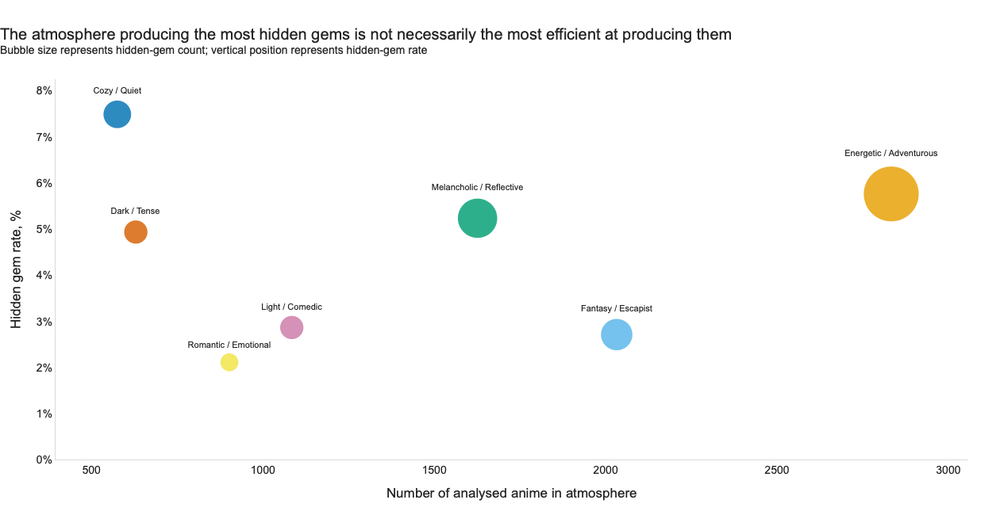

In [182]:
fig_q7_atmosphere.update_traces(
    marker={
        "opacity": 0.82,
        "line": {
            "width": 1.5,
            "color": "white"
        }
    },
    textposition="top center",
    textfont={
        "size": 11
    }
)

fig_q7_atmosphere = apply_chart_style(
    fig_q7_atmosphere,
    title=(
        "The atmosphere producing the most hidden gems "
        "is not necessarily the most efficient at producing them"
    ),
    subtitle=(
        "Bubble size represents hidden-gem count; "
        "vertical position represents hidden-gem rate"
    )
)

fig_q7_atmosphere.update_layout(
    height=650,
    showlegend=False
)

fig_q7_atmosphere.update_yaxes(
    ticksuffix="%",
    rangemode="tozero"
)

fig_q7_atmosphere.show()

In [183]:
highest_hidden_gem_rate_row = (
    hidden_gem_atmosphere_summary
    .sort_values(
        "hidden_gem_rate_pct",
        ascending=False
    )
    .iloc[0]
)

largest_hidden_gem_count_row = (
    hidden_gem_atmosphere_summary
    .sort_values(
        "hidden_gem_count",
        ascending=False
    )
    .iloc[0]
)

top_hidden_gem_row = hidden_gems.iloc[0]

In [184]:
highest_rate_value = (
    highest_hidden_gem_rate_row[
        "hidden_gem_rate_pct"
    ]
)

largest_count_value = (
    largest_hidden_gem_count_row[
        "hidden_gem_count"
    ]
)

print(
    "Highest hidden-gem rate:",
    highest_hidden_gem_rate_row["atmosphere"],
    f"({highest_rate_value:.1f}%)"
)

print(
    "Largest number of hidden gems:",
    largest_hidden_gem_count_row["atmosphere"],
    f"({largest_count_value:,.0f} titles)"
)

print(
    "Top-ranked hidden gem:",
    top_hidden_gem_row["title"],
    f"(score: {top_hidden_gem_row['score']:.2f}, "
    f"members: {top_hidden_gem_row['members']:,.0f})"
)

Highest hidden-gem rate: Cozy / Quiet (7.5%)
Largest number of hidden gems: Energetic / Adventurous (163 titles)
Top-ranked hidden gem: Fanren Xiu Xian Zhuan 4th Season (score: 8.54, members: 2,949)


In [185]:
top_hidden_gem_by_atmosphere = (
    hidden_gems
    .sort_values(
        "hidden_gem_score",
        ascending=False
    )
    .groupby("atmosphere")
    .first()
    .reset_index()
)

top_hidden_gem_by_atmosphere[
    [
        "atmosphere",
        "title",
        "score",
        "members",
        "hidden_gem_score"
    ]
]

,atmosphere,title,score,members,hidden_gem_score
0,Cozy / Quiet,Shinkiro,7.81,1905,94.078608
1,Dark / Tense,Ling Long: Incarnation Part 2,7.64,3451,88.735668
2,Energetic / Adventurous,Fanren Xiu Xian Zhuan 4th Season,8.54,2949,97.655201
3,Fantasy / Escapist,Yuanshen Tiwate Pian: Mu Jian PV - Dong Ye Yu Xi,7.79,2435,93.376201
4,Light / Comedic,Huangjin Tingyuan: Dongri Li de Xinnian Yuanwang,7.70,4067,87.932548
5,Melancholic / Reflective,Future GPX Cyber Formula Sin,7.62,3714,87.542609
6,Romantic / Emotional,Jebal Joyonghi Jom Hae!,7.62,4776,84.611610


### Key insight

The top-ranked hidden gem is **Fanren Xiu Xian Zhuan 4th Season**, combining a user score of approximately **8.54** with an audience of only **2949 members**.

At the atmosphere level, **Cozy / Quiet** has the highest hidden-gem rate, with approximately **7.5%** of its analysed titles meeting the hidden-gem definition.

However, **Energetic / Adventurous** produces the largest absolute number of hidden gems, with **163 titles**.

This distinction shows why both counts and rates matter. A large atmosphere may produce more hidden gems simply because it contains more titles, while a smaller atmosphere may produce hidden gems more consistently relative to its size.

### Limitations

- The hidden-gem definition depends on project-specific percentile and median thresholds.
- Different threshold choices would produce a different set of titles.
- The hidden gem score gives equal weight to rating strength and audience obscurity; another weighting scheme could change the ranking.
- `members` does not represent confirmed completed views.
- Only titles with at least 1,000 user ratings are included, so extremely niche anime are excluded.
- Older anime have had more time to accumulate members, which may reduce their likelihood of being classified as hidden gems.
- MyAnimeList user behaviour may not represent the full global anime audience.
- Separate seasons and sequels are treated as separate titles.
- Atmosphere categories are based on rule-driven interpretation.

## 15. Analytical Question 8

### Does the relationship between anime atmosphere and user score differ between TV series and movies?

The same atmosphere may perform differently depending on the release format.

For example, an atmosphere that works effectively in a long-form television series may receive weaker evaluations when compressed into a movie. Conversely, some atmospheres may benefit from the focused storytelling and production style of anime films.

This analysis compares median user scores for TV series and movies within the same atmosphere categories.

Only titles with at least 1,000 user ratings are included. Atmosphere–format combinations must also contain a sufficient number of titles to support a meaningful comparison.

In [186]:
question_8_df = df.dropna(
    subset=[
        "score",
        "scored_by",
        "type",
        "atmosphere"
    ]
).copy()

In [187]:
question_8_df = question_8_df[
    (question_8_df["scored_by"] >= 1000)
    & (question_8_df["type"].isin(["TV", "Movie"]))
    & (question_8_df["atmosphere"] != "Other")
].copy()

print(
    f"Anime included before group-size filtering: "
    f"{len(question_8_df):,}"
)

Anime included before group-size filtering: 5,679


In [188]:
question_8_counts = (
    question_8_df
    .groupby(
        [
            "atmosphere",
            "type"
        ]
    )
    .agg(
        anime_count=(
            "mal_id",
            "count"
        )
    )
    .reset_index()
)

question_8_counts

,atmosphere,type,anime_count
0,Cozy / Quiet,Movie,55
1,Cozy / Quiet,TV,310
2,Dark / Tense,Movie,105
3,Dark / Tense,TV,277
4,Energetic / Adventurous,Movie,501
5,Energetic / Adventurous,TV,1222
6,Fantasy / Escapist,Movie,265
7,Fantasy / Escapist,TV,884
8,Light / Comedic,Movie,83
9,Light / Comedic,TV,401


In [189]:
MIN_TITLES_PER_FORMAT = 30

In [190]:
question_8_count_pivot = (
    question_8_counts
    .pivot(
        index="atmosphere",
        columns="type",
        values="anime_count"
    )
    .fillna(0)
    .reset_index()
)

question_8_count_pivot

type,atmosphere,Movie,TV
0,Cozy / Quiet,55,310
1,Dark / Tense,105,277
2,Energetic / Adventurous,501,1222
3,Fantasy / Escapist,265,884
4,Light / Comedic,83,401
5,Melancholic / Reflective,331,737
6,Romantic / Emotional,49,459


In [191]:
valid_atmospheres_q8 = (
    question_8_count_pivot[
        (question_8_count_pivot["TV"] >= MIN_TITLES_PER_FORMAT)
        & (
            question_8_count_pivot["Movie"]
            >= MIN_TITLES_PER_FORMAT
        )
    ]["atmosphere"]
    .tolist()
)

valid_atmospheres_q8

['Cozy / Quiet',
 'Dark / Tense',
 'Energetic / Adventurous',
 'Fantasy / Escapist',
 'Light / Comedic',
 'Melancholic / Reflective',
 'Romantic / Emotional']

In [192]:
question_8_plot_df = question_8_df[
    question_8_df["atmosphere"].isin(
        valid_atmospheres_q8
    )
].copy()

print(
    f"Anime included after group-size filtering: "
    f"{len(question_8_plot_df):,}"
)

print(
    f"Atmospheres included: "
    f"{len(valid_atmospheres_q8)}"
)

Anime included after group-size filtering: 5,679
Atmospheres included: 7


In [193]:
question_8_summary = (
    question_8_plot_df
    .groupby(
        [
            "atmosphere",
            "type"
        ]
    )
    .agg(
        anime_count=(
            "mal_id",
            "count"
        ),
        median_score=(
            "score",
            "median"
        ),
        mean_score=(
            "score",
            "mean"
        ),
        lower_quartile=(
            "score",
            lambda values: values.quantile(0.25)
        ),
        upper_quartile=(
            "score",
            lambda values: values.quantile(0.75)
        )
    )
    .reset_index()
)

question_8_summary

,atmosphere,type,anime_count,median_score,mean_score,lower_quartile,upper_quartile
0,Cozy / Quiet,Movie,55,7.750,7.554727,7.2750,8.065
1,Cozy / Quiet,TV,310,7.250,7.146774,6.7625,7.650
2,Dark / Tense,Movie,105,7.510,7.178190,6.8500,7.910
3,Dark / Tense,TV,277,7.160,7.044440,6.5400,7.610
4,Energetic / Adventurous,Movie,501,7.170,7.092814,6.7200,7.510
5,Energetic / Adventurous,TV,1222,7.060,7.023396,6.5700,7.520
6,Fantasy / Escapist,Movie,265,7.120,7.040453,6.5800,7.520
7,Fantasy / Escapist,TV,884,7.025,6.974152,6.5475,7.400
8,Light / Comedic,Movie,83,6.840,6.575181,6.2700,7.195
9,Light / Comedic,TV,401,6.890,6.865910,6.3800,7.440


In [194]:
question_8_score_pivot = (
    question_8_summary
    .pivot(
        index="atmosphere",
        columns="type",
        values="median_score"
    )
    .reset_index()
)

question_8_score_pivot

type,atmosphere,Movie,TV
0,Cozy / Quiet,7.75,7.250
1,Dark / Tense,7.51,7.160
2,Energetic / Adventurous,7.17,7.060
3,Fantasy / Escapist,7.12,7.025
4,Light / Comedic,6.84,6.890
5,Melancholic / Reflective,7.42,7.280
6,Romantic / Emotional,7.31,7.090


In [195]:
question_8_score_pivot[
    "movie_minus_tv"
] = (
    question_8_score_pivot["Movie"]
    - question_8_score_pivot["TV"]
)

question_8_score_pivot = (
    question_8_score_pivot
    .sort_values(
        "movie_minus_tv",
        ascending=True
    )
)

question_8_score_pivot

type,atmosphere,Movie,TV,movie_minus_tv
4,Light / Comedic,6.84,6.890,-0.050
3,Fantasy / Escapist,7.12,7.025,0.095
2,Energetic / Adventurous,7.17,7.060,0.110
5,Melancholic / Reflective,7.42,7.280,0.140
6,Romantic / Emotional,7.31,7.090,0.220
1,Dark / Tense,7.51,7.160,0.350
0,Cozy / Quiet,7.75,7.250,0.500


In [196]:
question_8_counts_wide = (
    question_8_count_pivot
    .rename(
        columns={
            "TV": "tv_count",
            "Movie": "movie_count"
        }
    )
)

question_8_full = (
    question_8_score_pivot
    .merge(
        question_8_counts_wide,
        on="atmosphere",
        how="left"
    )
)

question_8_full

type,atmosphere,Movie,TV,movie_minus_tv,movie_count,tv_count
0,Light / Comedic,6.84,6.890,-0.050,83,401
1,Fantasy / Escapist,7.12,7.025,0.095,265,884
2,Energetic / Adventurous,7.17,7.060,0.110,501,1222
3,Melancholic / Reflective,7.42,7.280,0.140,331,737
4,Romantic / Emotional,7.31,7.090,0.220,49,459
5,Dark / Tense,7.51,7.160,0.350,105,277
6,Cozy / Quiet,7.75,7.250,0.500,55,310


### TV–movie score comparison

A dumbbell chart connects the median TV score and median movie score for every atmosphere.

A longer connecting line indicates a larger format difference. The point positioned further to the right represents the format with the higher median score.

In [197]:
atmosphere_order_q8 = (
    question_8_full["atmosphere"]
    .tolist()
)

fig_q8 = go.Figure()

In [198]:
for _, row in question_8_full.iterrows():
    fig_q8.add_trace(
        go.Scatter(
            x=[
                row["TV"],
                row["Movie"]
            ],
            y=[
                row["atmosphere"],
                row["atmosphere"]
            ],
            mode="lines",
            line={
                "color": CONTEXT_COLOR,
                "width": 4
            },
            hoverinfo="skip",
            showlegend=False
        )
    )

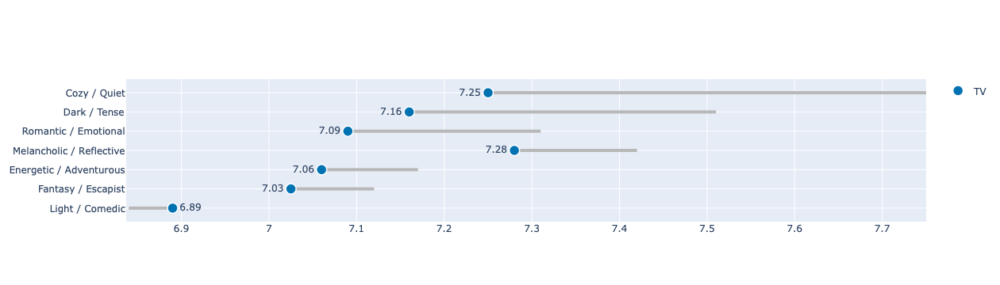

In [199]:
tv_text_positions = np.where(
    question_8_full["atmosphere"] == "Light / Comedic",
    "middle right",
    "middle left",
)

movie_text_positions = np.where(
    question_8_full["atmosphere"] == "Light / Comedic",
    "middle left",
    "middle right",
)

fig_q8.add_trace(
    go.Scatter(
        x=question_8_full["TV"],
        y=question_8_full["atmosphere"],
        mode="markers+text",
        name="TV",
        marker={
            "size": 13,
            "color": "#0072B2",
            "line": {
                "width": 1.5,
                "color": "white",
            },
        },
        text=question_8_full["TV"].map(
            lambda value: f"{value:.2f}"
        ),
        textposition=tv_text_positions,
        customdata=np.column_stack(
            [
                question_8_full["tv_count"],
                question_8_full["movie_minus_tv"],
            ]
        ),
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Format: TV<br>"
            "Median score: %{x:.2f}<br>"
            "Anime titles: %{customdata[0]:,.0f}<br>"
            "Movie − TV difference: "
            "%{customdata[1]:+.2f}"
            "<extra></extra>"
        ),
    )
)

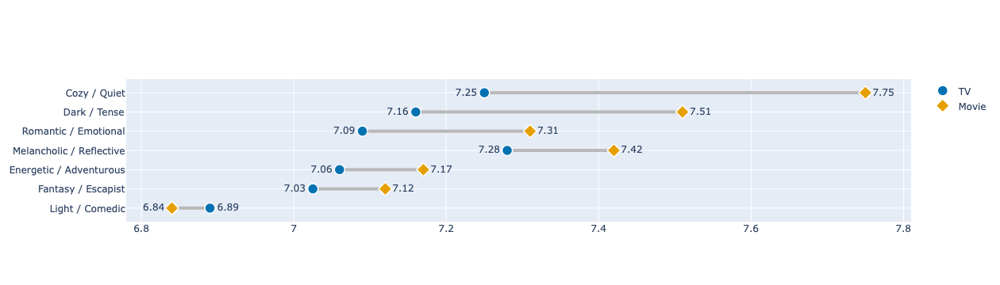

In [200]:
fig_q8.add_trace(
    go.Scatter(
        x=question_8_full["Movie"],
        y=question_8_full["atmosphere"],
        mode="markers+text",
        name="Movie",
        marker={
            "size": 13,
            "color": "#E69F00",
            "symbol": "diamond",
            "line": {
                "width": 1.5,
                "color": "white"
            }
        },
        text=question_8_full["Movie"].map(
            lambda value: f"{value:.2f}"
        ),
        textposition=movie_text_positions,
        customdata=np.column_stack(
            [
                question_8_full["movie_count"],
                question_8_full["movie_minus_tv"]
            ]
        ),
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Format: Movie<br>"
            "Median score: %{x:.2f}<br>"
            "Anime titles: %{customdata[0]:,.0f}<br>"
            "Movie − TV difference: "
            "%{customdata[1]:+.2f}"
            "<extra></extra>"
        )
    )
)

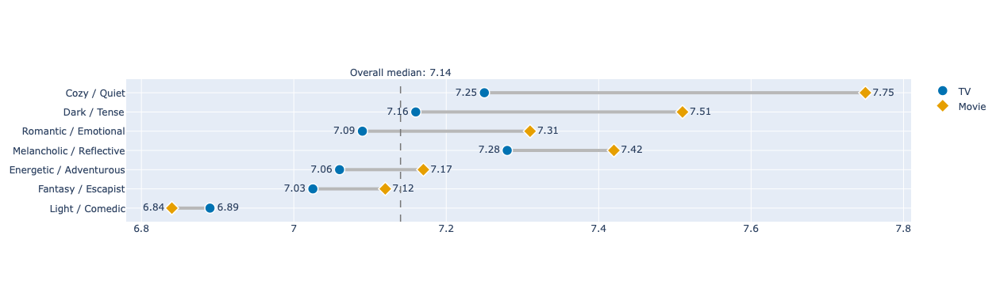

In [201]:
overall_median_q8 = (
    question_8_plot_df["score"]
    .median()
)

fig_q8.add_vline(
    x=overall_median_q8,
    line_width=1.5,
    line_dash="dash",
    line_color="#777777",
    annotation_text=(
        f"Overall median: "
        f"{overall_median_q8:.2f}"
    ),
    annotation_position="top"
)

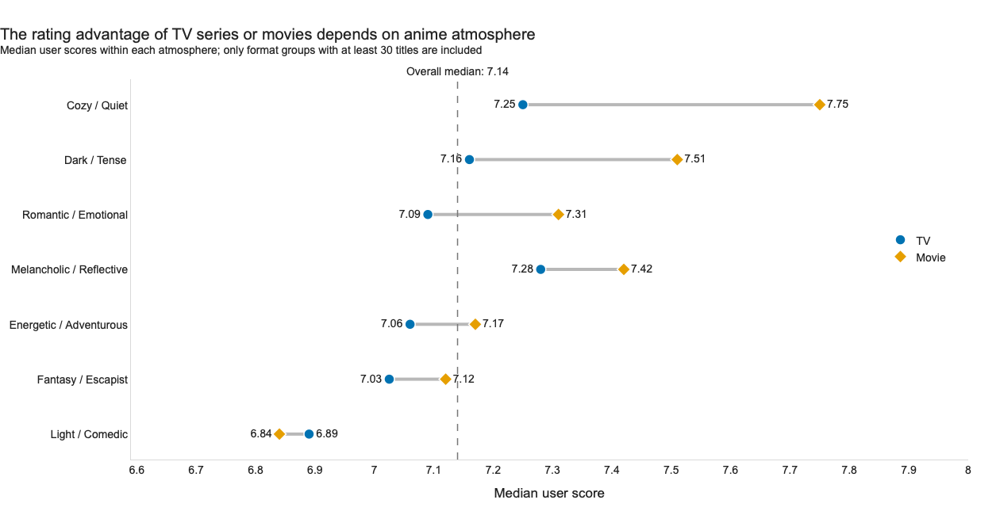

In [202]:
fig_q8 = apply_chart_style(
    fig_q8,
    title=(
        "The rating advantage of TV series or movies "
        "depends on anime atmosphere"
    ),
    subtitle=(
        "Median user scores within each atmosphere; "
        "only format groups with at least "
        f"{MIN_TITLES_PER_FORMAT} titles are included"
    )
)

fig_q8.update_layout(
    height=650,
    legend={
        "orientation": "v",
        "yanchor": "bottom",
        "y": 0.5,
        "xanchor": "left",
        "x": 0.9
    }
)

fig_q8.update_yaxes(
    categoryorder="array",
    categoryarray=atmosphere_order_q8
)

score_min_q8 = min(
    question_8_full["TV"].min(),
    question_8_full["Movie"].min()
)

score_max_q8 = max(
    question_8_full["TV"].max(),
    question_8_full["Movie"].max()
)

fig_q8.update_xaxes(
    title="Median user score",
    range=[
        score_min_q8 - 0.25,
        score_max_q8 + 0.25
    ],
    dtick=0.1
)

fig_q8.show()

In [203]:
question_8_difference = (
    question_8_full[
        [
            "atmosphere",
            "TV",
            "Movie",
            "movie_minus_tv",
            "tv_count",
            "movie_count"
        ]
    ]
    .copy()
)

question_8_difference["format_advantage"] = np.where(
    question_8_difference["movie_minus_tv"] >= 0,
    "Movie scores higher",
    "TV scores higher"
)

question_8_difference["difference_label"] = (
    question_8_difference["movie_minus_tv"]
    .map(lambda value: f"{value:+.2f}")
)

question_8_difference

type,atmosphere,TV,Movie,movie_minus_tv,tv_count,movie_count,format_advantage,difference_label
0,Light / Comedic,6.890,6.84,-0.050,401,83,TV scores higher,-0.05
1,Fantasy / Escapist,7.025,7.12,0.095,884,265,Movie scores higher,+0.09
2,Energetic / Adventurous,7.060,7.17,0.110,1222,501,Movie scores higher,+0.11
3,Melancholic / Reflective,7.280,7.42,0.140,737,331,Movie scores higher,+0.14
4,Romantic / Emotional,7.090,7.31,0.220,459,49,Movie scores higher,+0.22
5,Dark / Tense,7.160,7.51,0.350,277,105,Movie scores higher,+0.35
6,Cozy / Quiet,7.250,7.75,0.500,310,55,Movie scores higher,+0.50


In [204]:
fig_q8_difference = px.bar(
    question_8_difference,
    x="movie_minus_tv",
    y="atmosphere",
    orientation="h",
    color="format_advantage",
    text="difference_label",
    color_discrete_map={
        "Movie scores higher": "#E69F00",
        "TV scores higher": "#0072B2"
    },
    custom_data=[
        "TV",
        "Movie",
        "tv_count",
        "movie_count"
    ],
    labels={
        "movie_minus_tv": (
            "Median-score difference: Movie − TV"
        ),
        "atmosphere": "",
        "format_advantage": ""
    }
)

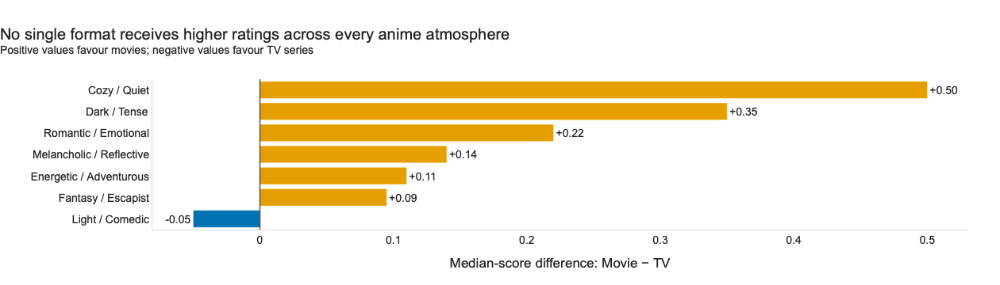

In [205]:
fig_q8_difference.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Movie − TV: %{x:+.2f}<br>"
        "TV median: %{customdata[0]:.2f}<br>"
        "Movie median: %{customdata[1]:.2f}<br>"
        "TV titles: %{customdata[2]:,.0f}<br>"
        "Movie titles: %{customdata[3]:,.0f}"
        "<extra></extra>"
    )
)

fig_q8_difference.add_vline(
    x=0,
    line_width=1.5,
    line_color="#555555"
)

fig_q8_difference = apply_chart_style(
    fig_q8_difference,
    title=(
        "No single format receives higher ratings "
        "across every anime atmosphere"
    ),
    subtitle=(
        "Positive values favour movies; "
        "negative values favour TV series"
    )
)

fig_q8_difference.update_layout(
    showlegend=False
)

fig_q8_difference.show()

In [206]:
largest_movie_advantage_row = (
    question_8_difference
    .sort_values(
        "movie_minus_tv",
        ascending=False
    )
    .iloc[0]
)

largest_tv_advantage_row = (
    question_8_difference
    .sort_values(
        "movie_minus_tv",
        ascending=True
    )
    .iloc[0]
)

In [207]:
largest_movie_advantage = (
    largest_movie_advantage_row[
        "movie_minus_tv"
    ]
)

largest_tv_advantage = (
    largest_tv_advantage_row[
        "movie_minus_tv"
    ]
)

print(
    "Largest movie advantage:",
    largest_movie_advantage_row["atmosphere"],
    f"({largest_movie_advantage:+.2f} points)"
)

print(
    "Largest TV advantage:",
    largest_tv_advantage_row["atmosphere"],
    f"({largest_tv_advantage:+.2f} points)"
)

Largest movie advantage: Cozy / Quiet (+0.50 points)
Largest TV advantage: Light / Comedic (-0.05 points)


In [208]:
question_8_difference["higher_rated_format"] = np.where(
    question_8_difference["movie_minus_tv"] > 0,
    "Movie",
    np.where(
        question_8_difference["movie_minus_tv"] < 0,
        "TV",
        "Equal"
    )
)

question_8_difference[
    [
        "atmosphere",
        "TV",
        "Movie",
        "movie_minus_tv",
        "higher_rated_format"
    ]
]

type,atmosphere,TV,Movie,movie_minus_tv,higher_rated_format
0,Light / Comedic,6.890,6.84,-0.050,TV
1,Fantasy / Escapist,7.025,7.12,0.095,Movie
2,Energetic / Adventurous,7.060,7.17,0.110,Movie
3,Melancholic / Reflective,7.280,7.42,0.140,Movie
4,Romantic / Emotional,7.090,7.31,0.220,Movie
5,Dark / Tense,7.160,7.51,0.350,Movie
6,Cozy / Quiet,7.250,7.75,0.500,Movie


In [209]:
format_win_counts = (
    question_8_difference[
        "higher_rated_format"
    ]
    .value_counts()
    .rename_axis("format")
    .reset_index(name="atmosphere_count")
)

format_win_counts

,format,atmosphere_count
0,Movie,6
1,TV,1


### Key insight

The relationship between atmosphere and user score differs between TV series and movies.

**Cozy / Quiet** shows the largest movie advantage. Its median movie score exceeds its median TV score by approximately **0.50 points**.

In contrast, **Light / Comedic** shows the strongest TV advantage, with TV series scoring approximately **- 0.5 points** higher than movies.

Movies receive the higher median score in **6 atmosphere categories**, while TV series lead in **1 category**.

These results suggest that format and atmosphere interact rather than affecting user ratings independently. Some emotional or thematic experiences may benefit from extended episodic development, while others may work more successfully within a concentrated film format.

### Limitations

- Only TV series and movies are compared; other formats such as OVA and ONA are excluded.
- Only titles with at least 1,000 user ratings are included, which underrepresents niche anime.
- Atmosphere–format combinations with fewer than 30 titles are removed to improve reliability.
- Median scores summarize each category but conceal variation among individual anime.
- TV series and movies differ in duration, production structure, audience expectations, and release conditions.
- The analysis cannot determine whether format itself causes the observed score difference.
- Atmosphere categories are produced through rule-based genre and theme matching.
- Separate seasons and sequels are treated as independent titles.
- Movie and TV sample sizes may still differ substantially within the same atmosphere.

## 16. Analytical Question 9

### Which studios perform best within different anime atmospheres when both ratings and production volume are considered?

Studio performance should not be evaluated using only the highest-rated individual title.

A studio with one highly rated anime may appear stronger than a studio that has produced many consistently successful titles.

This analysis compares studios within anime atmosphere categories using:

- median user score;
- number of analysed titles;
- median audience size.

Only studio–atmosphere combinations with a sufficient production volume are included.

In [210]:
studio_long = (
    df[
        [
            "mal_id",
            "title",
            "score",
            "scored_by",
            "members",
            "atmosphere",
            "studios_list"
        ]
    ]
    .explode("studios_list")
    .rename(
        columns={
            "studios_list": "studio"
        }
    )
)

In [211]:
studio_long = studio_long[
    studio_long["studio"].notna()
    & studio_long["studio"].ne("")
].copy()

studio_long.head()

,mal_id,title,score,scored_by,members,atmosphere,studio
0,1,Cowboy Bebop,8.75,1059628.0,2051751,Fantasy / Escapist,Sunrise
1,5,Cowboy Bebop: Tengoku no Tobira,8.38,231900.0,411149,Fantasy / Escapist,Bones
2,6,Trigun,8.22,400979.0,832801,Energetic / Adventurous,Madhouse
3,7,Witch Hunter Robin,7.25,46538.0,129274,Melancholic / Reflective,Sunrise
4,8,Bouken Ou Beet,7.01,7229.0,16881,Energetic / Adventurous,Toei Animation


In [212]:
question_9_df = studio_long.dropna(
    subset=[
        "score",
        "scored_by",
        "members",
        "atmosphere",
        "studio"
    ]
).copy()

In [213]:
question_9_df = question_9_df[
    (question_9_df["scored_by"] >= 1000)
    & (question_9_df["members"] > 0)
    & (question_9_df["atmosphere"] != "Other")
].copy()

print(
    f"Studio–anime observations included: "
    f"{len(question_9_df):,}"
)

print(
    f"Unique studios included: "
    f"{question_9_df['studio'].nunique():,}"
)

Studio–anime observations included: 10,352
Unique studios included: 758


In [214]:
question_9_summary = (
    question_9_df
    .groupby(
        [
            "atmosphere",
            "studio"
        ]
    )
    .agg(
        anime_count=(
            "mal_id",
            "nunique"
        ),
        median_score=(
            "score",
            "median"
        ),
        mean_score=(
            "score",
            "mean"
        ),
        median_members=(
            "members",
            "median"
        ),
        total_members=(
            "members",
            "sum"
        )
    )
    .reset_index()
)

question_9_summary.head()

,atmosphere,studio,anime_count,median_score,mean_score,median_members,total_members
0,Cozy / Quiet,8bit,14,7.335,7.240714,29159.5,651830
1,Cozy / Quiet,A-1 Pictures,4,7.535,7.370000,50616.5,279934
2,Cozy / Quiet,A-Real,3,5.390,5.160000,11219.0,33021
3,Cozy / Quiet,A.C.G.T.,2,6.490,6.490000,14330.0,28660
4,Cozy / Quiet,ACiD FiLM,1,5.880,5.880000,6887.0,6887


In [215]:
question_9_summary[
    "anime_count"
].describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95
    ]
)

count    1931.000000
mean        5.360953
std        12.369933
min         1.000000
50%         2.000000
75%         5.000000
90%        12.000000
95%        19.000000
max       261.000000
Name: anime_count, dtype: float64

In [216]:
MIN_STUDIO_TITLES = 5

In [217]:
question_9_filtered = question_9_summary[
    question_9_summary["anime_count"]
    >= MIN_STUDIO_TITLES
].copy()

print(
    f"Studio–atmosphere combinations remaining: "
    f"{len(question_9_filtered):,}"
)

print(
    f"Studios remaining: "
    f"{question_9_filtered['studio'].nunique():,}"
)

Studio–atmosphere combinations remaining: 518
Studios remaining: 191


In [218]:
question_9_atmosphere_counts = (
    question_9_filtered
    .groupby("atmosphere")
    .agg(
        studio_count=(
            "studio",
            "nunique"
        ),
        anime_count=(
            "anime_count",
            "sum"
        )
    )
    .reset_index()
    .sort_values(
        "studio_count",
        ascending=False
    )
)

question_9_atmosphere_counts

,atmosphere,studio_count,anime_count
2,Energetic / Adventurous,131,2659
3,Fantasy / Escapist,111,1712
5,Melancholic / Reflective,83,1315
4,Light / Comedic,64,844
6,Romantic / Emotional,62,671
0,Cozy / Quiet,36,377
1,Dark / Tense,31,405


### Studio performance index

To balance quality and production volume, studios are ranked within each atmosphere using two percentile measures:

- median-score percentile;
- production-volume percentile.

The studio performance index is the average of these two values.

This project-specific index rewards studios that combine strong ratings with repeated production experience in the same atmosphere.

In [219]:
question_9_filtered[
    "score_percentile_within_atmosphere"
] = (
    question_9_filtered
    .groupby("atmosphere")[
        "median_score"
    ]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

In [220]:
question_9_filtered[
    "volume_percentile_within_atmosphere"
] = (
    question_9_filtered
    .groupby("atmosphere")[
        "anime_count"
    ]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

In [221]:
question_9_filtered[
    "studio_performance_index"
] = (
    question_9_filtered[
        "score_percentile_within_atmosphere"
    ]
    + question_9_filtered[
        "volume_percentile_within_atmosphere"
    ]
) / 2

In [222]:
top_studios_by_atmosphere = (
    question_9_filtered
    .sort_values(
        [
            "atmosphere",
            "studio_performance_index",
            "median_score"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .groupby("atmosphere")
    .head(3)
    .copy()
)

top_studios_by_atmosphere[
    [
        "atmosphere",
        "studio",
        "anime_count",
        "median_score",
        "median_members",
        "studio_performance_index"
    ]
]

,atmosphere,studio,anime_count,median_score,median_members,studio_performance_index
73,Cozy / Quiet,Kyoto Animation,23,7.750,135636.0,93.055556
109,Cozy / Quiet,SILVER LINK.,14,7.725,77290.5,83.333333
140,Cozy / Quiet,Sunrise,27,7.410,22428.0,83.333333
311,Dark / Tense,TMS Entertainment,60,7.615,19577.5,90.322581
334,Dark / Tense,Wit Studio,17,7.880,150504.0,85.483871
245,Dark / Tense,MAPPA,16,8.060,442409.0,83.064516
529,Energetic / Adventurous,MAPPA,38,7.490,116472.0,88.358779
403,Energetic / Adventurous,Bones,65,7.410,152698.0,87.977099
625,Energetic / Adventurous,Shin-Ei Animation,46,7.340,9171.5,84.923664
1109,Fantasy / Escapist,White Fox,16,7.975,309720.0,88.513514


In [223]:
top_studios_by_atmosphere[
    "studio_atmosphere_label"
] = (
    top_studios_by_atmosphere["studio"]
    + " — "
    + top_studios_by_atmosphere["atmosphere"]
)

In [224]:
fig_q9 = px.bar(
    top_studios_by_atmosphere,
    x="studio_performance_index",
    y="studio",
    color="atmosphere",
    facet_col="atmosphere",
    facet_col_wrap=2,
    orientation="h",
    text="studio_performance_index",
    color_discrete_sequence=CVD_COLORS,
    custom_data=[
        "anime_count",
        "median_score",
        "median_members",
        "score_percentile_within_atmosphere",
        "volume_percentile_within_atmosphere"
    ],
    labels={
        "studio_performance_index": (
            "Studio performance index"
        ),
        "studio": "",
        "atmosphere": "Atmosphere"
    }
)

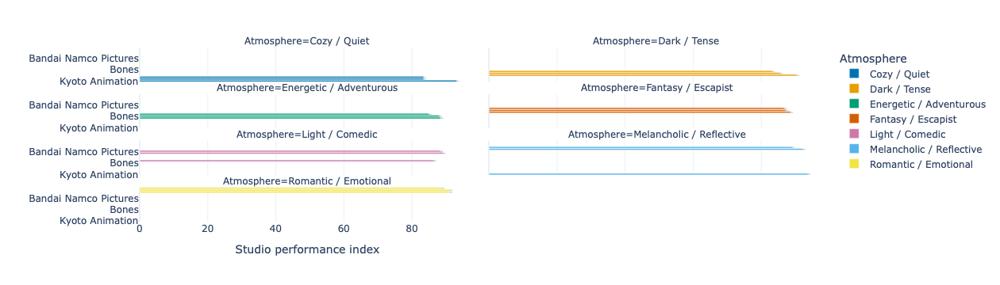

In [225]:
fig_q9.update_traces(
    texttemplate="%{x:.1f}",
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Performance index: %{x:.1f}<br>"
        "Anime titles: %{customdata[0]:,.0f}<br>"
        "Median score: %{customdata[1]:.2f}<br>"
        "Median members: %{customdata[2]:,.0f}<br>"
        "Score percentile: %{customdata[3]:.1f}<br>"
        "Volume percentile: %{customdata[4]:.1f}"
        "<extra></extra>"
    )
)

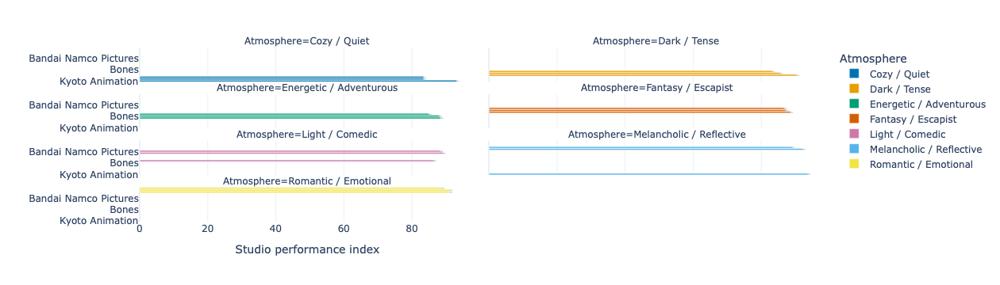

In [226]:
fig_q9.for_each_annotation(
    lambda annotation: annotation.update(
        text=annotation.text.replace(
            "atmosphere=",
            ""
        )
    )
)

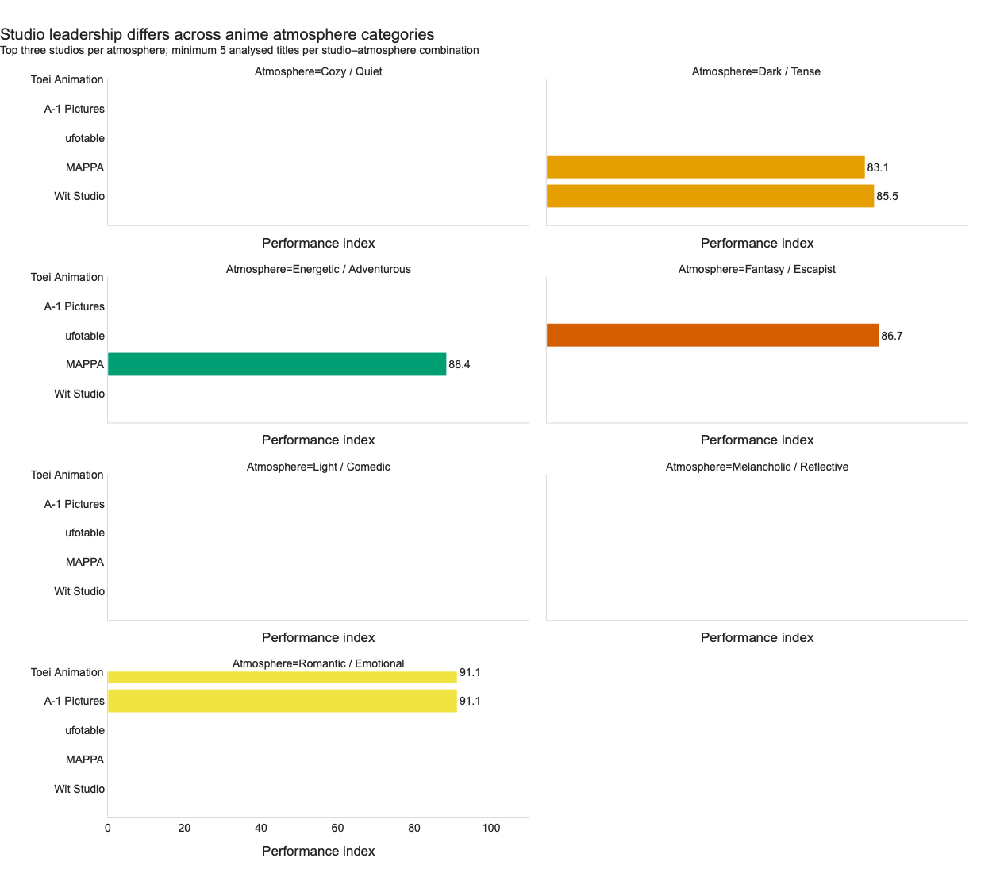

In [227]:
fig_q9 = apply_chart_style(
    fig_q9,
    title=(
        "Studio leadership differs across "
        "anime atmosphere categories"
    ),
    subtitle=(
        f"Top three studios per atmosphere; "
        f"minimum {MIN_STUDIO_TITLES} analysed titles "
        "per studio–atmosphere combination"
    )
)

fig_q9.update_layout(
    height=1100,
    showlegend=False
)

fig_q9.update_xaxes(
    range=[0, 110],
    title="Performance index"
)

fig_q9.update_yaxes(
    categoryorder="total ascending"
)

fig_q9.show()

In [228]:
best_studio_each_atmosphere = (
    question_9_filtered
    .sort_values(
        [
            "atmosphere",
            "studio_performance_index",
            "median_score"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .groupby("atmosphere")
    .first()
    .reset_index()
)

best_studio_each_atmosphere

,atmosphere,studio,anime_count,median_score,mean_score,median_members,total_members,score_percentile_within_atmosphere,volume_percentile_within_atmosphere,studio_performance_index
0,Cozy / Quiet,Kyoto Animation,23,7.750,7.430000,135636.0,7529147,90.277778,95.833333,93.055556
1,Dark / Tense,TMS Entertainment,60,7.615,7.551667,19577.5,2301060,80.645161,100.000000,90.322581
2,Energetic / Adventurous,MAPPA,38,7.490,7.480526,116472.0,13114436,86.259542,90.458015,88.358779
3,Fantasy / Escapist,White Fox,16,7.975,7.666250,309720.0,9388097,98.198198,78.828829,88.513514
4,Light / Comedic,Shaft,23,7.380,7.119565,31498.0,1485529,89.062500,89.062500,89.062500
5,Melancholic / Reflective,Kyoto Animation,30,7.935,7.894667,210054.0,12942044,97.590361,89.759036,93.674699
6,Romantic / Emotional,Toei Animation,27,7.390,7.355556,25679.0,2124919,90.322581,91.935484,91.129032


In [229]:
best_studio_each_atmosphere[
    "label"
] = (
    best_studio_each_atmosphere["studio"]
    + "<br>"
    + best_studio_each_atmosphere[
        "anime_count"
    ].astype(int).astype(str)
    + " titles"
)

In [230]:
fig_q9_best = px.scatter(
    best_studio_each_atmosphere,
    x="anime_count",
    y="median_score",
    size="median_members",
    color="atmosphere",
    text="label",
    size_max=55,
    color_discrete_sequence=CVD_COLORS,
    hover_name="studio",
    hover_data={
        "atmosphere": True,
        "anime_count": ":,",
        "median_score": ":.2f",
        "median_members": ":,.0f",
        "studio_performance_index": ":.1f"
    },
    labels={
        "anime_count": "Number of analysed titles",
        "median_score": "Median user score",
        "median_members": "Median members",
        "studio_performance_index": (
            "Performance index"
        ),
        "atmosphere": "Atmosphere"
    }
)

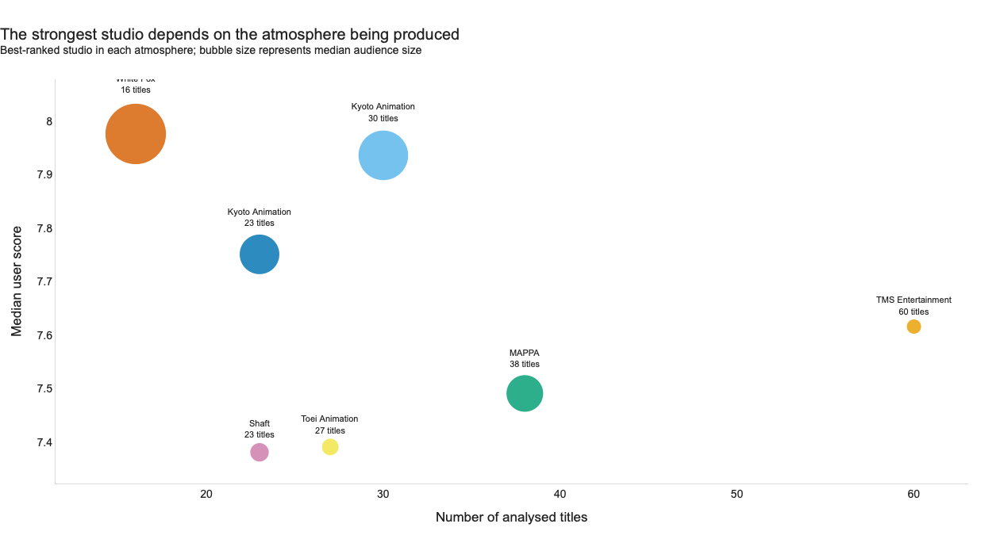

In [231]:
fig_q9_best.update_traces(
    marker={
        "opacity": 0.82,
        "line": {
            "width": 1.5,
            "color": "white"
        }
    },
    textposition="top center",
    textfont={
        "size": 11
    }
)

fig_q9_best = apply_chart_style(
    fig_q9_best,
    title=(
        "The strongest studio depends on "
        "the atmosphere being produced"
    ),
    subtitle=(
        "Best-ranked studio in each atmosphere; "
        "bubble size represents median audience size"
    )
)

fig_q9_best.update_layout(
    height=680,
    showlegend=False
)

fig_q9_best.show()

In [232]:
highest_rated_studio_row = (
    question_9_filtered
    .sort_values(
        [
            "median_score",
            "anime_count"
        ],
        ascending=[
            False,
            False
        ]
    )
    .iloc[0]
)

highest_volume_studio_row = (
    question_9_filtered
    .sort_values(
        [
            "anime_count",
            "median_score"
        ],
        ascending=[
            False,
            False
        ]
    )
    .iloc[0]
)

highest_performance_row = (
    question_9_filtered
    .sort_values(
        "studio_performance_index",
        ascending=False
    )
    .iloc[0]
)

In [233]:
print(
    "Highest median score:",
    highest_rated_studio_row["studio"],
    "within",
    highest_rated_studio_row["atmosphere"],
    f"({highest_rated_studio_row['median_score']:.2f})"
)

print(
    "Largest production volume:",
    highest_volume_studio_row["studio"],
    "within",
    highest_volume_studio_row["atmosphere"],
    f"({highest_volume_studio_row['anime_count']:,.0f} titles)"
)

print(
    "Highest combined performance index:",
    highest_performance_row["studio"],
    "within",
    highest_performance_row["atmosphere"],
    f"({highest_performance_row['studio_performance_index']:.1f})"
)

Highest median score: Artland within Cozy / Quiet (8.62)
Largest production volume: Toei Animation within Energetic / Adventurous (261 titles)
Highest combined performance index: Kyoto Animation within Melancholic / Reflective (93.7)


In [234]:
studio_leader_table = (
    best_studio_each_atmosphere[
        [
            "atmosphere",
            "studio",
            "anime_count",
            "median_score",
            "median_members",
            "studio_performance_index"
        ]
    ]
    .sort_values(
        "studio_performance_index",
        ascending=False
    )
)

studio_leader_table

,atmosphere,studio,anime_count,median_score,median_members,studio_performance_index
5,Melancholic / Reflective,Kyoto Animation,30,7.935,210054.0,93.674699
0,Cozy / Quiet,Kyoto Animation,23,7.750,135636.0,93.055556
6,Romantic / Emotional,Toei Animation,27,7.390,25679.0,91.129032
1,Dark / Tense,TMS Entertainment,60,7.615,19577.5,90.322581
4,Light / Comedic,Shaft,23,7.380,31498.0,89.062500
3,Fantasy / Escapist,White Fox,16,7.975,309720.0,88.513514
2,Energetic / Adventurous,MAPPA,38,7.490,116472.0,88.358779


In [235]:
index_score_correlation = (
    question_9_filtered[
        "studio_performance_index"
    ]
    .corr(
        question_9_filtered[
            "median_score"
        ]
    )
)

index_volume_correlation = (
    question_9_filtered[
        "studio_performance_index"
    ]
    .corr(
        question_9_filtered[
            "anime_count"
        ]
    )
)

print(
    "Performance index correlation with median score:",
    f"{index_score_correlation:.2f}"
)

print(
    "Performance index correlation with production volume:",
    f"{index_volume_correlation:.2f}"
)

Performance index correlation with median score: 0.67
Performance index correlation with production volume: 0.47


### Key insight

Studio performance varies substantially across anime atmospheres, and no single studio necessarily dominates every category.

The highest combined performance index belongs to **Kyoto Animation** within the **Melancholic / Reflective** category, with an index of approximately **93.7**.

The highest median user score is achieved by **Artland** within **Cozy / Quiet**, at approximately **8.62**. However, the largest production volume belongs to **Toei Animation** within **Energetic / Adventurous**, with **261 analysed titles**.

This distinction demonstrates that studio quality and production experience are related but separate dimensions. Some studios achieve exceptional ratings with a relatively focused catalogue, while others develop broader experience within a particular atmosphere.

### Limitations

- The studio performance index is a project-specific measure based on equal weighting of rating and production-volume percentiles.
- Different weighting choices could change the studio rankings.
- Only studio–atmosphere combinations with at least five analysed titles are included.
- Anime with multiple credited studios are counted for every listed studio.
- The analysis cannot separate the contribution of individual studios in co-productions.
- Median score does not account for differences in the number of user ratings beyond the minimum threshold.
- Studios operating for longer periods have had more opportunities to build larger catalogues.
- Separate seasons and sequels are treated as separate titles.
- Atmosphere categories are based on rule-driven genre and theme classification.
- Association between studio and rating does not prove that the studio alone caused the audience response.

## 17. Analytical Question 10

### Which genre–theme combinations are associated with both high user ratings and large audiences?

Genres describe broad narrative categories, while themes provide more specific information about setting, subject matter, or storytelling structure.

Examining genres or themes separately may conceal important interactions. For example, the audience response to drama may differ substantially when it is combined with psychological, historical, school, or workplace themes.

This analysis therefore examines genre–theme combinations using:

- median user score;
- median audience size;
- number of titles in each combination.

Only combinations with sufficient representation are included to reduce the influence of isolated titles.

In [236]:
question_10_df = df[
    [
        "mal_id",
        "title",
        "score",
        "scored_by",
        "members",
        "release_year",
        "type",
        "atmosphere",
        "genres_list",
        "themes_list"
    ]
].copy()

In [237]:
question_10_long = (
    question_10_df
    .explode("genres_list")
    .rename(
        columns={
            "genres_list": "genre"
        }
    )
)

In [238]:
question_10_long = (
    question_10_long
    .explode("themes_list")
    .rename(
        columns={
            "themes_list": "theme"
        }
    )
)

In [239]:
question_10_long = question_10_long[
    question_10_long["genre"].notna()
    & question_10_long["genre"].ne("")
    & question_10_long["theme"].notna()
    & question_10_long["theme"].ne("")
].copy()

print(
    f"Anime–genre–theme observations: "
    f"{len(question_10_long):,}"
)

Anime–genre–theme observations: 39,856


In [240]:
question_10_long = question_10_long.dropna(
    subset=[
        "score",
        "scored_by",
        "members",
        "genre",
        "theme"
    ]
).copy()

question_10_long = question_10_long[
    (question_10_long["scored_by"] >= 1000)
    & (question_10_long["members"] > 0)
].copy()

print(
    f"Observations after reliability filtering: "
    f"{len(question_10_long):,}"
)

print(
    f"Unique anime remaining: "
    f"{question_10_long['mal_id'].nunique():,}"
)

Observations after reliability filtering: 26,533
Unique anime remaining: 6,987


In [241]:
question_10_long["genre_theme"] = (
    question_10_long["genre"]
    + " + "
    + question_10_long["theme"]
)

question_10_long[
    [
        "title",
        "genre",
        "theme",
        "genre_theme"
    ]
].head(15)

,title,genre,theme,genre_theme
0,Cowboy Bebop,Action,Adult Cast,Action + Adult Cast
0,Cowboy Bebop,Action,Space,Action + Space
0,Cowboy Bebop,Award Winning,Adult Cast,Award Winning + Adult Cast
0,Cowboy Bebop,Award Winning,Space,Award Winning + Space
0,Cowboy Bebop,Sci-Fi,Adult Cast,Sci-Fi + Adult Cast
0,Cowboy Bebop,Sci-Fi,Space,Sci-Fi + Space
1,Cowboy Bebop: Tengoku no Tobira,Action,Adult Cast,Action + Adult Cast
1,Cowboy Bebop: Tengoku no Tobira,Action,Space,Action + Space
1,Cowboy Bebop: Tengoku no Tobira,Sci-Fi,Adult Cast,Sci-Fi + Adult Cast
1,Cowboy Bebop: Tengoku no Tobira,Sci-Fi,Space,Sci-Fi + Space


In [242]:
genre_theme_counts = (
    question_10_long
    .groupby(
        [
            "genre",
            "theme",
            "genre_theme"
        ]
    )
    .agg(
        anime_count=(
            "mal_id",
            "nunique"
        )
    )
    .reset_index()
    .sort_values(
        "anime_count",
        ascending=False
    )
)

genre_theme_counts.head(20)

,genre,theme,genre_theme,anime_count
212,Comedy,School,Comedy + School,869
599,Sci-Fi,Mecha,Sci-Fi + Mecha,659
563,Romance,School,Romance + School,596
204,Comedy,Parody,Comedy + Parody,383
616,Sci-Fi,Space,Sci-Fi + Space,378
350,Fantasy,Isekai,Fantasy + Isekai,358
12,Action,Historical,Action + Historical,336
601,Sci-Fi,Military,Sci-Fi + Military,323
19,Action,Martial Arts,Action + Martial Arts,317
36,Action,Super Power,Action + Super Power,315


In [243]:
genre_theme_counts[
    "anime_count"
].describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count    769.000000
mean      34.503251
std       71.379909
min        1.000000
50%        9.000000
75%       32.000000
90%       91.200000
95%      160.000000
99%      318.920000
max      869.000000
Name: anime_count, dtype: float64

In [244]:
MIN_TITLES_PER_COMBINATION = 30

In [245]:
question_10_summary = (
    question_10_long
    .groupby(
        [
            "genre",
            "theme",
            "genre_theme"
        ]
    )
    .agg(
        anime_count=(
            "mal_id",
            "nunique"
        ),
        median_score=(
            "score",
            "median"
        ),
        mean_score=(
            "score",
            "mean"
        ),
        median_members=(
            "members",
            "median"
        ),
        lower_quartile_score=(
            "score",
            lambda values: values.quantile(0.25)
        ),
        upper_quartile_score=(
            "score",
            lambda values: values.quantile(0.75)
        )
    )
    .reset_index()
)

question_10_summary.head()

,genre,theme,genre_theme,anime_count,median_score,mean_score,median_members,lower_quartile_score,upper_quartile_score
0,Action,Adult Cast,Action + Adult Cast,226,7.345,7.321327,37343.0,6.9225,7.7775
1,Action,Anthropomorphic,Action + Anthropomorphic,35,6.650,6.704286,31242.0,6.2300,7.3200
2,Action,CGDCT,Action + CGDCT,9,7.250,7.237778,67657.0,7.1300,7.5400
3,Action,Childcare,Action + Childcare,12,8.050,7.764167,293923.5,7.3050,8.1250
4,Action,Crossdressing,Action + Crossdressing,3,7.270,7.020000,90169.0,6.8500,7.3150


In [246]:
question_10_summary = question_10_summary[
    question_10_summary["anime_count"]
    >= MIN_TITLES_PER_COMBINATION
].copy()

print(
    f"Genre–theme combinations remaining: "
    f"{len(question_10_summary):,}"
)

Genre–theme combinations remaining: 205


In [247]:
question_10_summary["log_median_members"] = np.log10(
    question_10_summary["median_members"]
)

question_10_summary[
    [
        "genre_theme",
        "anime_count",
        "median_score",
        "median_members",
        "log_median_members"
    ]
].head()

,genre_theme,anime_count,median_score,median_members,log_median_members
0,Action + Adult Cast,226,7.345,37343.0,4.572209
1,Action + Anthropomorphic,35,6.650,31242.0,4.494739
6,Action + Detective,65,7.330,38875.0,4.589670
9,Action + Gore,174,7.240,111160.5,5.045950
10,Action + Harem,141,6.800,178880.0,5.252562


In [248]:
overall_combo_median_score = (
    question_10_summary["median_score"]
    .median()
)

overall_combo_median_members = (
    question_10_summary["median_members"]
    .median()
)

overall_combo_log_members = np.log10(
    overall_combo_median_members
)

print(
    "Median combination score:",
    f"{overall_combo_median_score:.2f}"
)

print(
    "Median combination audience:",
    f"{overall_combo_median_members:,.0f} members"
)

Median combination score: 7.15
Median combination audience: 50,385 members


### Genre–theme success index

To rank combinations by both reception and reach, two percentile measures are calculated:

- median-score percentile;
- median-audience percentile.

The genre–theme success index is their equally weighted average.

This project-specific index is used only as a ranking aid. The original rating and audience values remain visible in the visualisation.

In [249]:
question_10_summary[
    "score_percentile"
] = (
    question_10_summary["median_score"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

question_10_summary[
    "audience_percentile"
] = (
    question_10_summary["median_members"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

In [250]:
question_10_summary[
    "success_index"
] = (
    question_10_summary["score_percentile"]
    + question_10_summary["audience_percentile"]
) / 2

In [251]:
conditions_q10 = [
    (
        question_10_summary["median_score"]
        >= overall_combo_median_score
    )
    & (
        question_10_summary["median_members"]
        >= overall_combo_median_members
    ),

    (
        question_10_summary["median_score"]
        >= overall_combo_median_score
    )
    & (
        question_10_summary["median_members"]
        < overall_combo_median_members
    ),

    (
        question_10_summary["median_score"]
        < overall_combo_median_score
    )
    & (
        question_10_summary["median_members"]
        >= overall_combo_median_members
    )
]

choices_q10 = [
    "High rating, large audience",
    "High rating, smaller audience",
    "Lower rating, large audience"
]

question_10_summary["success_category"] = np.select(
    conditions_q10,
    choices_q10,
    default="Lower rating, smaller audience"
)

In [252]:
question_10_summary[
    "success_category"
].value_counts()

success_category
High rating, large audience       55
Lower rating, smaller audience    54
High rating, smaller audience     48
Lower rating, large audience      48
Name: count, dtype: int64

In [253]:
top_success_labels = (
    question_10_summary
    .nlargest(
        12,
        "success_index"
    )["genre_theme"]
    .tolist()
)

highest_score_combo = (
    question_10_summary
    .sort_values(
        "median_score",
        ascending=False
    )
    .iloc[0]["genre_theme"]
)

largest_audience_combo = (
    question_10_summary
    .sort_values(
        "median_members",
        ascending=False
    )
    .iloc[0]["genre_theme"]
)

labelled_combinations = set(
    top_success_labels
    + [
        highest_score_combo,
        largest_audience_combo
    ]
)

In [254]:
question_10_summary["chart_label"] = np.where(
    question_10_summary["genre_theme"].isin(
        labelled_combinations
    ),
    question_10_summary["genre_theme"],
    ""
)

In [255]:
success_category_colors = {
    "High rating, large audience": "#0072B2",
    "High rating, smaller audience": "#009E73",
    "Lower rating, large audience": "#E69F00",
    "Lower rating, smaller audience": "#B8B8B8"
}

fig_q10 = px.scatter(
    question_10_summary,
    x="log_median_members",
    y="median_score",
    size="anime_count",
    color="success_category",
    size_max=45,
    color_discrete_map=success_category_colors,
    custom_data=[
        "genre_theme",
        "genre",
        "theme",
        "median_members",
        "anime_count",
        "mean_score",
        "lower_quartile_score",
        "upper_quartile_score",
        "success_index"
    ],
    labels={
        "log_median_members": (
            "Typical audience size, log10(median members)"
        ),
        "median_score": "Median user score",
        "success_category": "Combination profile",
        "anime_count": "Anime titles"
    }
)

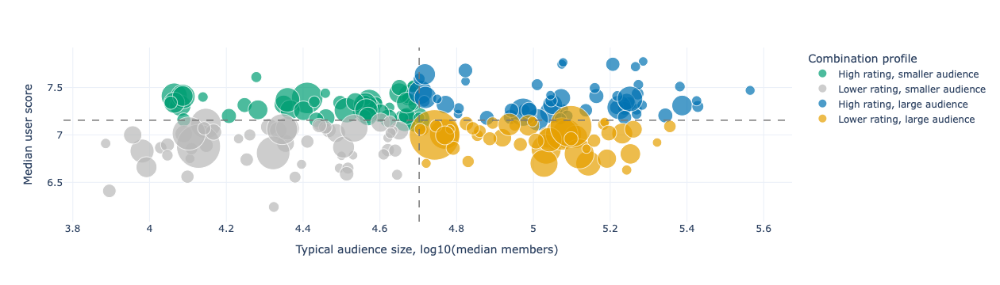

In [256]:
fig_q10.add_vline(
    x=overall_combo_log_members,
    line_width=1.5,
    line_dash="dash",
    line_color="#777777"
)

fig_q10.add_hline(
    y=overall_combo_median_score,
    line_width=1.5,
    line_dash="dash",
    line_color="#777777"
)

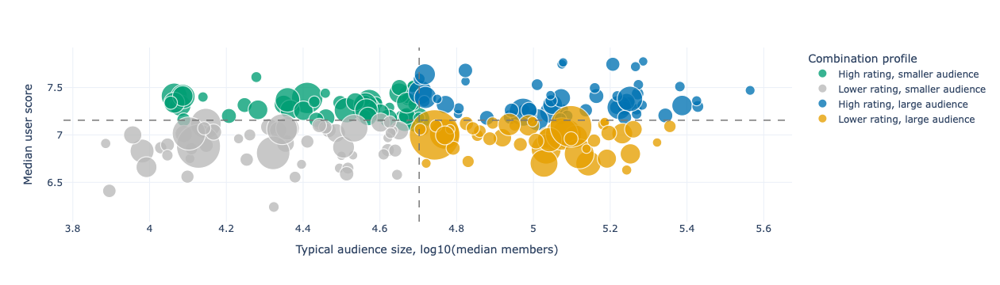

In [257]:
fig_q10.update_traces(
    marker={
        "opacity": 0.78,
        "line": {
            "width": 1.2,
            "color": "white"
        }
    },
    textposition="top center",
    textfont={
        "size": 10
    },
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Genre: %{customdata[1]}<br>"
        "Theme: %{customdata[2]}<br>"
        "Median score: %{y:.2f}<br>"
        "Mean score: %{customdata[5]:.2f}<br>"
        "Median members: %{customdata[3]:,.0f}<br>"
        "Anime titles: %{customdata[4]:,.0f}<br>"
        "Middle 50% of scores: "
        "%{customdata[6]:.2f}–%{customdata[7]:.2f}<br>"
        "Success index: %{customdata[8]:.1f}"
        "<extra></extra>"
    )
)

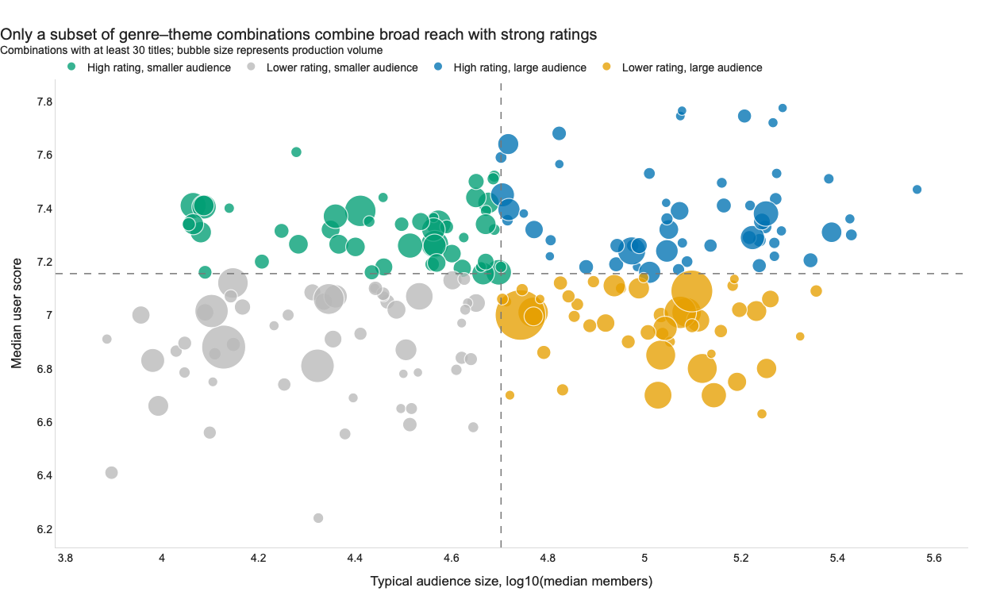

In [258]:
fig_q10 = apply_chart_style(
    fig_q10,
    title=(
        "Only a subset of genre–theme combinations "
        "combine broad reach with strong ratings"
    ),
    subtitle=(
        f"Combinations with at least "
        f"{MIN_TITLES_PER_COMBINATION} titles; "
        "bubble size represents production volume"
    )
)

fig_q10.update_layout(
    height=760,
    legend={
        "orientation": "h",
        "yanchor": "bottom",
        "y": 1,
        "xanchor": "left",
        "x": 0
    }
)

fig_q10.show()

In [259]:
top_genre_theme_combinations = (
    question_10_summary
    .sort_values(
        [
            "success_index",
            "median_score"
        ],
        ascending=[
            False,
            False
        ]
    )
    .head(15)
    .copy()
)

top_genre_theme_combinations[
    "success_label"
] = (
    top_genre_theme_combinations[
        "success_index"
    ]
    .map(lambda value: f"{value:.1f}")
)

In [260]:
top_genre_theme_plot = (
    top_genre_theme_combinations
    .sort_values(
        "success_index",
        ascending=True
    )
)

fig_q10_rank = px.bar(
    top_genre_theme_plot,
    x="success_index",
    y="genre_theme",
    orientation="h",
    color="success_category",
    text="success_label",
    color_discrete_map=success_category_colors,
    custom_data=[
        "median_score",
        "median_members",
        "anime_count",
        "score_percentile",
        "audience_percentile"
    ],
    labels={
        "success_index": "Genre–theme success index",
        "genre_theme": "",
        "success_category": ""
    }
)

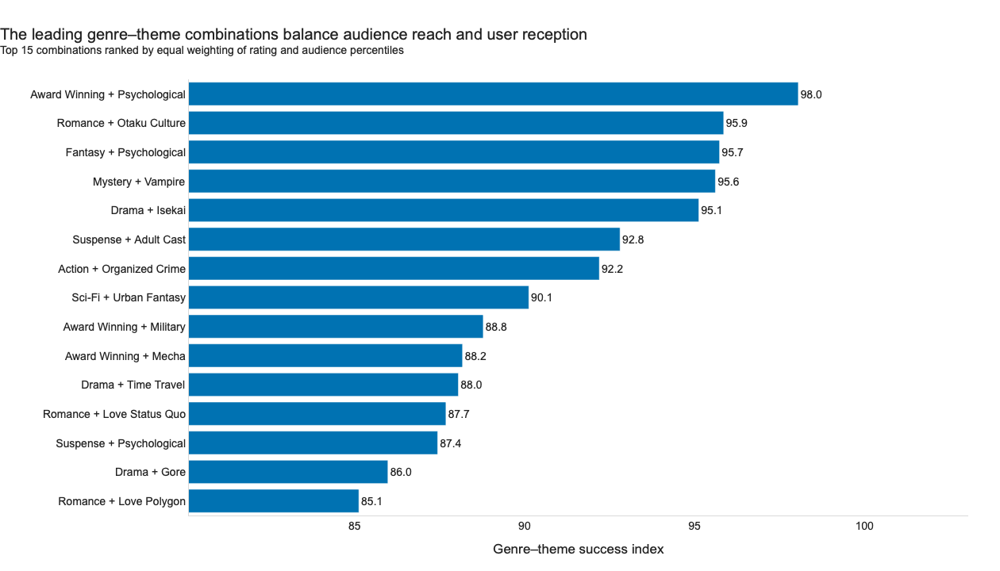

In [261]:
fig_q10_rank.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Success index: %{x:.1f}<br>"
        "Median score: %{customdata[0]:.2f}<br>"
        "Median members: %{customdata[1]:,.0f}<br>"
        "Anime titles: %{customdata[2]:,.0f}<br>"
        "Score percentile: %{customdata[3]:.1f}<br>"
        "Audience percentile: %{customdata[4]:.1f}"
        "<extra></extra>"
    )
)

fig_q10_rank = apply_chart_style(
    fig_q10_rank,
    title=(
        "The leading genre–theme combinations "
        "balance audience reach and user reception"
    ),
    subtitle=(
        "Top 15 combinations ranked by equal weighting "
        "of rating and audience percentiles"
    )
)

fig_q10_rank.update_layout(
    height=720,
    showlegend=False
)

fig_q10_rank.update_xaxes(
    range=[
        max(
            0,
            top_genre_theme_plot[
                "success_index"
            ].min() - 5
        ),
        min(
            105,
            top_genre_theme_plot[
                "success_index"
            ].max() + 5
        )
    ]
)

fig_q10_rank.show()

In [262]:
highest_success_row = (
    question_10_summary
    .sort_values(
        "success_index",
        ascending=False
    )
    .iloc[0]
)

highest_score_combo_row = (
    question_10_summary
    .sort_values(
        [
            "median_score",
            "anime_count"
        ],
        ascending=[
            False,
            False
        ]
    )
    .iloc[0]
)

largest_audience_combo_row = (
    question_10_summary
    .sort_values(
        [
            "median_members",
            "median_score"
        ],
        ascending=[
            False,
            False
        ]
    )
    .iloc[0]
)

largest_volume_combo_row = (
    question_10_summary
    .sort_values(
        [
            "anime_count",
            "median_score"
        ],
        ascending=[
            False,
            False
        ]
    )
    .iloc[0]
)

In [263]:
print(
    "Highest combined success:",
    highest_success_row["genre_theme"],
    f"(index: {highest_success_row['success_index']:.1f})"
)

print(
    "Highest median score:",
    highest_score_combo_row["genre_theme"],
    f"({highest_score_combo_row['median_score']:.2f})"
)

print(
    "Largest median audience:",
    largest_audience_combo_row["genre_theme"],
    (
        f"({largest_audience_combo_row['median_members']:,.0f} "
        "members)"
    )
)

print(
    "Largest production volume:",
    largest_volume_combo_row["genre_theme"],
    f"({largest_volume_combo_row['anime_count']:,.0f} titles)"
)

Highest combined success: Award Winning + Psychological (index: 98.0)
Highest median score: Award Winning + Psychological (7.78)
Largest median audience: Romance + Otaku Culture (366,907 members)
Largest production volume: Comedy + School (869 titles)


In [264]:
broad_success_combinations = (
    question_10_summary[
        question_10_summary[
            "success_category"
        ] == "High rating, large audience"
    ]
    .sort_values(
        "success_index",
        ascending=False
    )
)

broad_success_combinations[
    [
        "genre_theme",
        "anime_count",
        "median_score",
        "median_members",
        "success_index"
    ]
].head(20)

,genre_theme,anime_count,median_score,median_members,success_index
134,Award Winning + Psychological,30,7.775,193134.5,98.048780
555,Romance + Otaku Culture,33,7.470,366907.0,95.853659
366,Fantasy + Psychological,38,7.510,240747.5,95.731707
523,Mystery + Vampire,35,7.720,184456.0,95.609756
242,Drama + Isekai,37,7.530,187703.0,95.121951
736,Suspense + Adult Cast,68,7.745,161012.0,92.804878
24,Action + Organized Crime,54,7.435,186840.0,92.195122
622,Sci-Fi + Urban Fantasy,35,7.360,266215.0,90.121951
127,Award Winning + Military,30,7.765,119492.0,88.780488
125,Award Winning + Mecha,32,7.745,118538.5,88.170732


In [265]:
acclaimed_niche_combinations = (
    question_10_summary[
        question_10_summary[
            "success_category"
        ] == "High rating, smaller audience"
    ]
    .sort_values(
        [
            "median_score",
            "success_index"
        ],
        ascending=[
            False,
            False
        ]
    )
)

acclaimed_niche_combinations[
    [
        "genre_theme",
        "anime_count",
        "median_score",
        "median_members",
        "success_index"
    ]
].head(15)

,genre_theme,anime_count,median_score,median_members,success_index
51,Adventure + Detective,41,7.610,18971.0,56.097561
211,Comedy + Samurai,49,7.520,48780.0,71.341463
245,Drama + Mahou Shoujo,51,7.510,48533.0,70.609756
629,Slice of Life + CGDCT,88,7.500,44738.5,68.536585
577,Sci-Fi + Adult Cast,143,7.440,44681.0,66.951220
681,Sports + Racing,36,7.440,28697.0,58.170732
226,Drama + Adult Cast,157,7.420,47458.0,68.170732
540,Romance + Historical,143,7.410,12202.0,46.951220
56,Adventure + Historical,231,7.410,11593.0,46.341463
348,Fantasy + Historical,202,7.405,12214.0,46.585366


In [266]:
popular_lower_rated_combinations = (
    question_10_summary[
        question_10_summary[
            "success_category"
        ] == "Lower rating, large audience"
    ]
    .sort_values(
        "median_members",
        ascending=False
    )
)

popular_lower_rated_combinations[
    [
        "genre_theme",
        "anime_count",
        "median_score",
        "median_members",
        "success_index"
    ]
].head(15)

,genre_theme,anime_count,median_score,median_members,success_index
29,Action + Reincarnation,53,7.090,226736.0,70.121951
316,Ecchi + Urban Fantasy,30,6.920,209974.5,58.536585
368,Fantasy + Reincarnation,106,7.060,182153.5,65.243902
10,Action + Harem,141,6.800,178880.0,51.829268
55,Adventure + Harem,35,6.630,174964.0,46.829268
15,Action + Isekai,148,7.015,170371.0,60.121951
471,Horror + Psychological,84,7.020,157130.5,59.512195
346,Fantasy + Harem,125,6.750,155382.0,47.195122
209,Comedy + Reincarnation,32,7.135,153400.0,67.195122
76,Adventure + Reincarnation,45,7.110,152159.0,65.487805


In [267]:
top_genre_theme_combinations[
    "score_iqr"
] = (
    top_genre_theme_combinations[
        "upper_quartile_score"
    ]
    - top_genre_theme_combinations[
        "lower_quartile_score"
    ]
)

top_genre_theme_combinations[
    [
        "genre_theme",
        "median_score",
        "score_iqr",
        "median_members",
        "anime_count",
        "success_index"
    ]
].sort_values(
    [
        "success_index",
        "score_iqr"
    ],
    ascending=[
        False,
        True
    ]
)

,genre_theme,median_score,score_iqr,median_members,anime_count,success_index
134,Award Winning + Psychological,7.775,0.8225,193134.5,30,98.048780
555,Romance + Otaku Culture,7.470,0.7500,366907.0,33,95.853659
366,Fantasy + Psychological,7.510,1.0525,240747.5,38,95.731707
523,Mystery + Vampire,7.720,1.5200,184456.0,35,95.609756
242,Drama + Isekai,7.530,1.3700,187703.0,37,95.121951
736,Suspense + Adult Cast,7.745,0.8300,161012.0,68,92.804878
24,Action + Organized Crime,7.435,1.2225,186840.0,54,92.195122
622,Sci-Fi + Urban Fantasy,7.360,0.5700,266215.0,35,90.121951
127,Award Winning + Military,7.765,0.5750,119492.0,30,88.780488
125,Award Winning + Mecha,7.745,0.9850,118538.5,32,88.170732


### Key insight

The genre–theme combination with the strongest balance of audience reach and user reception is **Award Winning + Psychological**, with a combined success index of approximately **98**.

However, the combination with the highest median user score is **Award Winning + Psychological**, at approximately **7.78**, while **Romance + Otaku Culture** attracts the largest typical audience at approximately **366,907 members**.

The most frequently represented combination is **Comedy + School**, with **869 analysed titles**.

These differences show that production frequency, audience reach, and user evaluation are separate dimensions. Only a subset of genre–theme combinations performs strongly across both popularity and rating measures.

### Limitations

- One anime may contribute to several genre–theme combinations because titles can contain multiple genres and themes.
- The combinations should therefore not be interpreted as mutually exclusive categories.
- Only combinations with at least 30 analysed titles are included, excluding rare but potentially meaningful pairings.
- Changing the minimum group-size threshold could alter the set of displayed combinations.
- The success index is a project-specific measure based on equal weighting of rating and audience percentiles.
- Different weighting choices could change the ranking.
- Median values reduce the influence of individual blockbusters but conceal variation within combinations.
- Only titles with at least 1,000 user ratings are included, underrepresenting niche anime.
- MyAnimeList members represent platform activity rather than confirmed completed viewing.
- Genre and theme labels are metadata categories and may not capture the full narrative or emotional character of an anime.
- The observed relationships are associative and do not establish that a genre–theme combination directly causes popularity or higher ratings.

## 18. Overall findings

This project examined anime success as a multidimensional concept rather than treating popularity and rating as interchangeable measures.

The analysis considered:

- audience size;
- user score;
- audience loyalty;
- anime atmosphere;
- release format;
- historical period;
- production studio;
- genre–theme combinations.

Across the analytical questions, the results show that anime success depends on the interaction between content characteristics, format, historical context, and audience behaviour.

In [268]:
project_findings = pd.DataFrame(
    {
        "Question": [
            "Q1",
            "Q2",
            "Q3",
            "Q4",
            "Q5",
            "Q6",
            "Q7",
            "Q8",
            "Q9",
            "Q10"
        ],
        "Topic": [
            "Audience size and score by format",
            "Audience loyalty by atmosphere",
            "Typical audience and score by atmosphere",
            "Rating consistency by atmosphere",
            "Atmosphere share across decades",
            "Relative popularity across periods",
            "Hidden gems",
            "TV versus Movie ratings",
            "Studio performance by atmosphere",
            "Genre–theme success"
        ],
        "Main_result": [
            (
                f"{strongest_type} has the strongest "
                f"audience–score relationship "
                f"({strongest_correlation:.2f})"
            ),
            (
                f"{largest_increase_row['atmosphere']} shows "
                f"the largest loyalty increase "
                f"({largest_increase_row['loyalty_change']:+.2f} pp)"
            ),
            (
                f"{largest_audience_row['atmosphere']} has "
                f"the largest typical audience"
            ),
            (
                f"{best_combination_row['atmosphere']} offers "
                f"the strongest rating–consistency balance"
            ),
            (
                f"{largest_growth_row['atmosphere']} shows "
                f"the largest historical release-share increase"
            ),
            (
                f"{largest_gain_row['atmosphere']} shows "
                f"the largest relative popularity gain"
            ),
            (
                f"{top_hidden_gem_row['title']} is the "
                f"highest-ranked hidden gem"
            ),
            (
                f"{largest_movie_advantage_row['atmosphere']} "
                f"shows the largest Movie advantage"
            ),
            (
                f"{highest_performance_row['studio']} leads "
                f"the combined studio performance index"
            ),
            (
                f"{highest_success_row['genre_theme']} leads "
                f"the genre–theme success index"
            )
        ]
    }
)

project_findings

,Question,Topic,Main_result
0,Q1,Audience size and score by format,Movie has the strongest audience–score relationship (0.61)
1,Q2,Audience loyalty by atmosphere,Melancholic / Reflective shows the largest loyalty increase (+0.53 pp)
2,Q3,Typical audience and score by atmosphere,Romantic / Emotional has the largest typical audience
3,Q4,Rating consistency by atmosphere,Melancholic / Reflective offers the strongest rating–consistency balance
4,Q5,Atmosphere share across decades,Light / Comedic shows the largest historical release-share increase
5,Q6,Relative popularity across periods,Light / Comedic shows the largest relative popularity gain
6,Q7,Hidden gems,Fanren Xiu Xian Zhuan 4th Season is the highest-ranked hidden gem
7,Q8,TV versus Movie ratings,Cozy / Quiet shows the largest Movie advantage
8,Q9,Studio performance by atmosphere,Kyoto Animation leads the combined studio performance index
9,Q10,Genre–theme success,Award Winning + Psychological leads the genre–theme success index


### Overall interpretation

The findings indicate that anime success cannot be explained by a single variable.

First, audience size and user score are positively associated, but the strength of that association differs across release formats. This means that popularity provides useful information about user reception, but it cannot replace rating as a separate measure.

Second, atmosphere is associated with several dimensions of success. Atmosphere categories differ in their typical audience size, rating consistency, and ability to convert viewers into dedicated fans. The atmosphere attracting the largest audience is not necessarily the one with the highest or most stable ratings.

Third, the anime landscape has changed over time. Some atmospheres increased their share of production, while relative audience preferences also shifted. However, production growth and audience popularity did not always move in the same direction.

Fourth, format and production context matter. The comparison between television series and movies shows that the same atmosphere can perform differently depending on how the anime is presented. Studio performance also varies by atmosphere, suggesting that production experience may be specialised rather than universal.

Finally, genre–theme combinations reveal more specific patterns than broad genre labels alone. Only some combinations achieve both strong user ratings and large audiences, while others remain highly rated but comparatively niche.

Overall, popularity, rating, loyalty, and production volume should be interpreted as related but distinct dimensions of anime success.

## 19. Answer to the main research question

Anime characteristics are associated with popularity, user ratings, and audience loyalty in different ways.

Release format affects the strength of the relationship between audience size and score. Atmosphere is associated with typical audience reach, rating consistency, and the proportion of viewers who add a title to their favourites. Genre–theme combinations provide additional explanatory detail by identifying specific content patterns linked to both reach and reception.

These relationships also change over time. The production share of atmosphere categories shifted across decades, while their relative audience popularity developed differently between the 2000s, 2010s, and the current 2020–2025 period.

The analysis therefore suggests that successful anime cannot be defined by popularity alone. A more complete evaluation requires several complementary measures:

- audience reach;
- user evaluation;
- audience loyalty;
- historical context;
- production format and studio experience.

## 20. Project limitations

Several limitations should be considered when interpreting the results.

### Platform representation

The dataset represents activity on MyAnimeList. Its users may differ from the wider global anime audience in age, location, viewing habits, and genre preferences.

### Audience measures

`members` represents users who added an anime to their MyAnimeList account. It does not confirm that they watched or completed the title.

`favorites` represents one specific form of audience attachment and is used as a proxy for loyalty.

### Rating bias

User ratings are voluntary and may be affected by self-selection. Anime with fewer ratings may have less stable scores, which is why several analyses use a minimum threshold of 1,000 ratings.

### Historical comparison

Older titles have had more time to accumulate members and ratings. Relative popularity percentiles reduce this issue but cannot remove it completely.

Recent periods, particularly 2020–2025, are incomplete and should be interpreted as current snapshots.

### Atmosphere classification

Atmosphere is not an original dataset variable. It was created using rule-based genre and theme matching.

The classification involves subjective analytical decisions, and each anime is assigned only one primary atmosphere even when several categories may apply.

### Multiple categories

Anime may contain several genres, themes, or credited studios. In the corresponding analyses, one anime can contribute to more than one group.

### Causality

The analysis identifies associations. It does not establish that atmosphere, format, studio, or genre–theme combinations directly cause higher popularity or stronger ratings.

### Custom indices

The hidden-gem, studio-performance, and genre–theme-success indices were created specifically for this project. Different thresholds or weighting choices could produce different rankings.

## 21. Further research

Future analysis could extend the project in several ways.

One possibility would be to use natural language processing on anime synopses to create data-driven atmosphere categories rather than relying only on genre and theme rules.

A second extension would be to model score or audience size using regression or machine-learning techniques while controlling simultaneously for format, year, episode count, studio, source material, and atmosphere.

The project could also compare MyAnimeList results with data from other platforms to test whether the observed audience preferences are platform-specific.

Finally, analysing individual franchises rather than separate seasons could reduce the influence of sequel-heavy series and provide a franchise-level perspective on popularity and loyalty.

## 22. Exporting processed data

The cleaned and feature-engineered dataset is exported for use in the Streamlit dashboard.

Exporting the processed data ensures that the notebook and dashboard use the same atmosphere classifications and derived variables.

In [269]:
processed_columns = [
    "mal_id",
    "title",
    "title_english",
    "type",
    "source",
    "episodes",
    "status",
    "duration",
    "rating",
    "score",
    "scored_by",
    "rank",
    "popularity",
    "members",
    "favorites",
    "favorite_rate_pct",
    "season",
    "release_year",
    "decade",
    "studios",
    "genres",
    "themes",
    "demographics",
    "atmosphere",
    "atmosphere_match_score",
    "genre_count",
    "theme_count",
    "log_members",
    "synopsis",
    "image_url"
]

processed_columns = [
    column
    for column in processed_columns
    if column in df.columns
]

In [270]:
dashboard_df = df[
    processed_columns
].copy()

dashboard_df.head()

,mal_id,title,title_english,type,source,episodes,status,duration,rating,score,scored_by,rank,popularity,members,favorites,favorite_rate_pct,season,release_year,decade,studios,genres,themes,demographics,atmosphere,atmosphere_match_score,genre_count,theme_count,log_members,synopsis,image_url
0,1,Cowboy Bebop,Cowboy Bebop,TV,Original,26.0,Finished Airing,24 min per ep,R - 17+ (violence & profanity),8.75,1059628.0,49.0,41,2051751,89485,4.361397,spring,1998.0,1990s,Sunrise,Action|Award Winning|Sci-Fi,Adult Cast|Space,NaN,Fantasy / Escapist,2,3,2,6.312125,"Crime is timeless. By the year 2071, humanity has expanded across the galaxy, filling the surface of other planets w...",https://myanimelist.net/images/anime/4/19644.jpg
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,Movie,Original,1.0,Finished Airing,1 hr 55 min,R - 17+ (violence & profanity),8.38,231900.0,240.0,658,411149,1782,0.433420,NaN,2001.0,2000s,Bones,Action|Sci-Fi,Adult Cast|Space,NaN,Fantasy / Escapist,2,2,2,5.614000,"Another day, another bounty—such is the life of the often unlucky crew of the Bebop. However, this routine is interr...",https://myanimelist.net/images/anime/1439/93480.jpg
2,6,Trigun,Trigun,TV,Manga,26.0,Finished Airing,24 min per ep,PG-13 - Teens 13 or older,8.22,400979.0,420.0,265,832801,17610,2.114551,spring,1998.0,1990s,Madhouse,Action|Adventure|Sci-Fi,Adult Cast,Shounen,Energetic / Adventurous,2,3,1,5.920542,"Vash the Stampede is the man with a $$60,000,000,000 bounty on his head. The reason: he's a merciless villain who la...",https://myanimelist.net/images/anime/1130/120002.jpg
3,7,Witch Hunter Robin,Witch Hunter Robin,TV,Original,26.0,Finished Airing,25 min per ep,PG-13 - Teens 13 or older,7.25,46538.0,3529.0,1989,129274,707,0.546900,summer,2002.0,2000s,Sunrise,Action|Drama|Mystery|Supernatural,Detective,NaN,Melancholic / Reflective,1,4,1,5.111515,"Though hidden away from the general public, Witches—those with supernatural powers—have always existed in human soci...",https://myanimelist.net/images/anime/10/19969.jpg
4,8,Bouken Ou Beet,Beet the Vandel Buster,TV,Manga,52.0,Finished Airing,23 min per ep,PG - Children,7.01,7229.0,4900.0,5891,16881,18,0.106629,fall,2004.0,2000s,Toei Animation,Action|Adventure|Fantasy,NaN,Shounen,Energetic / Adventurous,2,3,0,4.227424,"It is the dark century and the people are suffering under the rule of the devil, Vandel, who is able to manipulate m...",https://myanimelist.net/images/anime/7/21569.jpg


In [271]:
dashboard_df.to_csv(
    "anime_processed.csv",
    index=False
)

print(
    "Processed dataset saved as anime_processed.csv"
)

print(
    f"Rows exported: {len(dashboard_df):,}"
)

print(
    f"Columns exported: {dashboard_df.shape[1]}"
)

Processed dataset saved as anime_processed.csv
Rows exported: 29,936
Columns exported: 30


In [272]:
question_3_summary.to_csv(
    "atmosphere_overview.csv",
    index=False
)

hidden_gems.to_csv(
    "hidden_gems.csv",
    index=False
)

studio_leader_table.to_csv(
    "studio_leaders.csv",
    index=False
)

top_genre_theme_combinations.to_csv(
    "genre_theme_leaders.csv",
    index=False
)

project_findings.to_csv(
    "project_findings.csv",
    index=False
)

print("Analytical summary tables exported.")

Analytical summary tables exported.


In [273]:
import os

exported_files = [
    "anime_processed.csv",
    "atmosphere_overview.csv",
    "hidden_gems.csv",
    "studio_leaders.csv",
    "genre_theme_leaders.csv",
    "project_findings.csv"
]

for file_name in exported_files:
    if os.path.exists(file_name):
        file_size_kb = (
            os.path.getsize(file_name) / 1024
        )

        print(
            f"{file_name}: "
            f"{file_size_kb:,.1f} KB"
        )
    else:
        print(
            f"{file_name}: not found"
        )

anime_processed.csv: 17,293.0 KB
atmosphere_overview.csv: 0.6 KB
hidden_gems.csv: 519.6 KB
studio_leaders.csv: 0.5 KB
genre_theme_leaders.csv: 3.6 KB
project_findings.csv: 1.0 KB


## 23. Reproducibility checklist

Before final submission, the notebook should be restarted and executed from beginning to end.

The following checks should be completed:

- all cells run without errors;
- the raw dataset path is correct;
- no analysis depends on manually created variables from an earlier session;
- chart titles accurately describe the actual results;
- all placeholder values in the written insights have been replaced;
- every analytical question has at least one explanatory Plotly visualisation;
- charts use readable labels and a consistent colour-safe design;
- processed datasets are successfully exported;
- external libraries are documented;
- the final notebook is exported to HTML or PDF.

In [274]:
import sys
import plotly

print("Python version:")
print(sys.version)

print("\nPandas version:")
print(pd.__version__)

print("\nNumPy version:")
print(np.__version__)

print("\nPlotly version:")
print(plotly.__version__)

Python version:
3.14.6 (main, Jun 10 2026, 10:03:53) [Clang 16.0.0 (clang-1600.0.26.6)]

Pandas version:
3.0.3

NumPy version:
2.5.1

Plotly version:
6.9.0


In [275]:
main_figures = {
    "Q1": fig,
    "Q2": fig_q2,
    "Q3": fig_q3,
    "Q4": fig_q4,
    "Q5": fig_q5,
    "Q6": fig_q6,
    "Q7": fig_q7,
    "Q8": fig_q8,
    "Q9": fig_q9_best,
    "Q10": fig_q10
}

for question, figure in main_figures.items():
    print(
        question,
        type(figure).__name__
    )

Q1 Figure
Q2 Figure
Q3 Figure
Q4 Figure
Q5 Figure
Q6 Figure
Q7 Figure
Q8 Figure
Q9 Figure
Q10 Figure


In [276]:
os.makedirs(
    "figures_html",
    exist_ok=True
)

for question, figure in main_figures.items():
    output_path = (
        f"figures_html/{question.lower()}_figure.html"
    )

    figure.write_html(
        output_path,
        include_plotlyjs="cdn"
    )

print(
    "Interactive Plotly figures saved "
    "to the figures_html folder."
)

Interactive Plotly figures saved to the figures_html folder.


## 24. Conclusion

This project demonstrates that anime success is multidimensional.

Large audiences are often associated with stronger ratings, but the relationship varies across formats and content categories. Atmosphere is connected not only to popularity but also to rating consistency and audience loyalty. Historical comparisons show that both production patterns and relative audience preferences changed over time.

The analysis also identifies highly rated but comparatively undiscovered titles, atmosphere-specific studio leaders, and genre–theme combinations that balance broad audience reach with strong user reception.

The central conclusion is that popularity alone provides an incomplete description of anime success. Ratings, loyalty, format, historical context, and production characteristics offer complementary perspectives that together produce a more meaningful understanding of audience response.